# Nucleotide content around the PAS (A/C/G/U + dimers)

This notebook compares the **nucleotide (A, C, G, U) and dinucleotide content** around the poly(A) sites (PAS) of 3'UTR pairs whose isoform usage shifts with that of all other pairs. It is the sequence control of the m6A analyses (`Figure_m6A_loading.ipynb`): m6A can only sit on an A, so a group richer in A is expected to carry more m6A sites. It was split out of an earlier, larger m6A notebook.

**Groups of 3'UTR pairs** (MN_diff shift tables, `projects/ALS_Comp/MN_diff/results/3UTR_analysis/shifts/`), each compared with all the other pairs of `table_of_pairs.csv` (one pair per proximal isoform: the one with the longest distal isoform):
- lengthened from D22 to D35 in CTRL nuclei: `pairs_distals_D22_Nuclear_Wildtype_vs_D35_Nuclear_Wildtype.csv`;
- lengthened from D22 to D35 in the CTRL cytoplasm: `pairs_distals_D22_Cytoplasmic_Wildtype_vs_D35_Cytoplasmic_Wildtype.csv`;
- longer in the nucleus than in the cytoplasm at D35 in CTRL: `pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Cytoplasmic_Wildtype.csv`.

The plot legends call the shifting group "Lengthening" in every comparison.

**Inputs**
- `MN_diff/results/3UTR_analysis/table_of_pairs.csv` and the shift tables above.
- 3'UTR annotation `annotation/hg38/3UTR_MNs/hg38_NoOverlap.gtf` (PAS = 3' end of each isoform).
- hg38 genome (`annotation/hg38/UCSC/hg38.fa`, read through its `.fai` index): sequence from −1000 to +200 nt around each PAS, on the transcript strand.

Figures are saved under `../Figures/Figure_m6A/nucleotide_content_around_PAS/` and listed with their legends in `../Figures/README.md`; the table is saved under `../Tables/Figure_m6A_nucleotide_content/` and described in `../Tables/README.md`.

## Contents

- Setup and data loading; FASTA reader and PAS positions; window-profile functions
- One section per group, each saving one figure per nucleotide and dinucleotide (A, C, G, U; AU, GC, GU, GA, AC, CU, AA, UU, CC, GG):
    - `<nucleotide>_content_around_PAS_nuclear_lengthened_D22_to_D35_CTRL.pdf`
    - `<nucleotide>_content_around_PAS_cytoplasmic_lengthened_D22_to_D35_CTRL.pdf`
    - `<nucleotide>_content_around_PAS_longer_in_nucleus_D35_CTRL.pdf`
- Dinucleotide enrichment per region (R1, R2, R3), the three groups side by side:
    - `dinucleotide_signed_log10p_per_region_heatmap.pdf` (one colour scale) and `dinucleotide_signed_log10p_per_region_heatmap_per_group_scale.pdf`
    - table `../Tables/Figure_m6A_nucleotide_content/dinucleotide_enrichment_mean_signed_log10_Fisher_p_lengthened_vs_other_3UTR_pairs_per_region_R1_R2_R3.csv`

## Setup and data loading

Imports, output folders, the 3'UTR pairs (reduced to the longest distal isoform per proximal isoform, `table_of_pairs_longest`) and the PAS annotation.

In [1]:
import pandas as pd
import matplotlib

import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns


matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

In [2]:
figures_subfolder = "../Figures/Figure_m6A/nucleotide_content_around_PAS"
tables_subfolder = "../Tables/Figure_m6A_nucleotide_content"
import os

if not os.path.exists(f"{figures_subfolder}"):
    os.makedirs(f"{figures_subfolder}")

# save_figure saves a figure and lists it, with its legend, in ../Figures/README.md;
# save_table saves a .csv table and lists it, with its description, in ../Tables/README.md
from functools import partial
from utrals.paths import PROJECT_DIR, ANNOT_DIR  # data locations outside the repository (paths.env)
from utrals import figures
save_figure = partial(figures.save_figure, notebook="Figure_m6A_nucleotide_content.ipynb")
save_table = partial(figures.save_table, notebook="Figure_m6A_nucleotide_content.ipynb")
figures.fix_random_seeds(0)  # fixed jitter and bootstrap confidence intervals: identical figures on every run

In [3]:
table_of_pairs = pd.read_csv(f"{PROJECT_DIR}/MN_diff/results/3UTR_analysis/table_of_pairs.csv")
path_to_shift = f"{PROJECT_DIR}/MN_diff/results/3UTR_analysis/shifts"

In [4]:

# Keep only the distal isoform with the longest length per proximal_id
table_of_pairs_longest = (
    table_of_pairs
    .sort_values('length', ascending=False)
    .drop_duplicates(subset='proximal_id', keep='first')
    .reset_index(drop=True)
)

print(f"Original pairs: {len(table_of_pairs)}")
print(f"After keeping longest distal per proximal: {len(table_of_pairs_longest)}")
table_of_pairs_longest[['proximal_id', 'distal_id', 'length']].head()


Original pairs: 7877
After keeping longest distal per proximal: 7877


,proximal_id,distal_id,length
0,CDK14.1.ENST00000265741.CTRL1.D14.Nuclear.Wild...,CDK14.ENST00000406263.Ensembl,92404
1,NBDY.ENST00000423617.Ensembl,NBDY.3.ENST00000374922.MUT1.D22.Cytoplasmic.VC...,88736
2,IRS1.1.ENST00000305123.CTRL5.D3.Cytoplasmic.Wi...,IRS1.ENST00000305123.Ensembl,63697
3,ZBED6.1.ENST00000550078.CTRL3.D7.Nuclear.Wildtype,ZBED6.ENST00000550078.Ensembl,53661
4,SHISAL1.2.ENST00000381176.CTRL5.D3.Cytoplasmic...,SHISAL1.ENST00000381176.Ensembl,41762


In [5]:
from genomemanager.gtf_utils import read_gtf

annotation = read_gtf(f"{ANNOT_DIR}/3UTR_MNs/hg38_NoOverlap.gtf")

## Genome sequence and PAS positions

`FaidxFasta` reads hg38 through its samtools `.fai` index (no pysam in this environment); `revcomp` gives the transcript strand of `-`-strand genes. `build_pas_lookup_seq` gives one PAS per isoform of `hg38_NoOverlap.gtf` (`pas_lookup`: largest end on the `+` strand, smallest start on the `-` strand).


In [6]:
class FaidxFasta:
    """Minimal random-access FASTA reader using a samtools .fai index
    (no pysam/pyfaidx dependency available in this environment)."""
    def __init__(self, fasta_path):
        self.fh = open(fasta_path, 'rb')
        self.index = {}
        with open(fasta_path + '.fai') as f:
            for line in f:
                name, length, offset, linebases, linewidth = line.rstrip('\n').split('\t')
                self.index[name] = (int(length), int(offset), int(linebases), int(linewidth))

    def fetch(self, chrom, start, end):
        """0-based half-open [start, end) fetch."""
        if chrom not in self.index:
            return None
        length, offset, linebases, linewidth = self.index[chrom]
        start, end = max(0, start), min(length, end)
        if end <= start:
            return ''
        newline_len = linewidth - linebases
        start_line, start_col = divmod(start, linebases)
        end_line, end_col = divmod(end - 1, linebases)
        file_start = offset + start_line * linewidth + start_col
        file_end = offset + end_line * linewidth + end_col + 1
        self.fh.seek(file_start)
        raw = self.fh.read(file_end - file_start)
        if newline_len:
            raw = raw.replace(b'\n' * newline_len, b'')
        return raw.decode('ascii').upper()

_COMPLEMENT = str.maketrans('ACGTN', 'TGCAN')
def revcomp(seq):
    return seq.translate(_COMPLEMENT)[::-1]

hg38_fasta = FaidxFasta(f"{ANNOT_DIR}/UCSC/hg38.fa")


In [7]:
def build_pas_lookup_seq(annotation_df):
    """One PAS position per transcript (max end for '+' strand, min start for '-')."""
    ann = annotation_df
    chrom_col = next((c for c in ['seqname', 'chrom', 'chr', 'Chromosome'] if c in ann.columns), ann.columns[0])
    tid_col   = next((c for c in ['transcript_id', 'transcript_name', 'name'] if c in ann.columns), None)

    ann_tx = ann[[chrom_col, 'start', 'end', 'strand', tid_col]].copy()
    ann_tx = ann_tx.groupby(tid_col).agg(
        chrom  = (chrom_col, 'first'),
        start  = ('start',   'min'),
        end    = ('end',     'max'),
        strand = ('strand',  'first')
    ).reset_index().rename(columns={tid_col: 'Isoform'})

    ann_tx['PAS'] = np.where(ann_tx['strand'] == '+', ann_tx['end'], ann_tx['start'])
    if not ann_tx['chrom'].iloc[0].startswith('chr'):
        ann_tx['chrom'] = 'chr' + ann_tx['chrom'].astype(str)
    return ann_tx[['Isoform', 'chrom', 'strand', 'PAS']]

pas_lookup = build_pas_lookup_seq(annotation)

NUCLEOTIDES = ['A', 'C', 'G', 'T']
NT_LABEL = {'A': 'A', 'C': 'C', 'G': 'G', 'T': 'U'}

## Window-profile functions (50-nt windows around the PAS)

Same windowed-scan / Fisher-exact-test layout as the m6A profiles of `Figure_m6A_loading.ipynb` (`plot_m6a_profiles`) (`-1000` to `+200` nt around the PAS, 50 nt bins, proximal/distal columns), but instead of "proportion of transcripts with a site in the window" this plots the **fraction of nucleotides that are A / C / G / U**, pooled across all bases of all transcripts in that window, for Lengthening vs Other. The Fisher exact test per window compares (nt count vs non-nt count) between the two groups, exactly as the m6A profile compares (bound vs unbound) counts.


In [8]:
_window_seq_cache = {}

def get_window_sequences(iso_df, isoform_col, ann_tx, fasta, wl_full=-1000, wr_full=200):
    """Fetch the full [wl_full, wr_full) window around the PAS for every transcript
    (reverse-complemented on the '-' strand); only full-length windows are kept.
    Results are memoized per (Isoform, wl_full, wr_full), since the same transcripts
    are re-fetched across the Nuclear/Cytoplasmic/D35 comparison groups below."""
    matched = iso_df[[isoform_col]].drop_duplicates().rename(columns={isoform_col: 'Isoform'}).merge(ann_tx, on='Isoform', how='inner')
    seqs = []
    for r in matched.itertuples(index=False):
        cache_key = (r.Isoform, wl_full, wr_full)
        if cache_key in _window_seq_cache:
            seq = _window_seq_cache[cache_key]
        else:
            if r.strand == '+':
                seq = fasta.fetch(r.chrom, r.PAS + wl_full, r.PAS + wr_full)
            else:
                seq = fasta.fetch(r.chrom, r.PAS - wr_full, r.PAS - wl_full)
                if seq:
                    seq = revcomp(seq)
            _window_seq_cache[cache_key] = seq
        if seq and len(seq) == (wr_full - wl_full):
            seqs.append(seq)
    return seqs



In [9]:
WL_FULL, WR_FULL = -1000, 200


## Pairs lengthened from D22 to D35 in CTRL nuclei

`pairs_distals_D22_Nuclear_Wildtype_vs_D35_Nuclear_Wildtype.csv` vs all other pairs. The cell fetches the [−1000, +200) sequence around the PAS of the proximal and of the distal isoform of every pair (`full_window_seqs`, used by the plot functions defined next); only full-length windows are kept. Saved: `<nucleotide>_content_around_PAS_nuclear_lengthened_D22_to_D35_CTRL.pdf`.

In [10]:
fisher_sig_lengthening = pd.read_csv(f"{path_to_shift}/pairs_distals_D22_Nuclear_Wildtype_vs_D35_Nuclear_Wildtype.csv")
fisher_sig_lengthening = fisher_sig_lengthening[fisher_sig_lengthening['distal_id'].isin(table_of_pairs_longest['distal_id'])]
fisher_other = table_of_pairs_longest[~table_of_pairs_longest['distal_id'].isin(fisher_sig_lengthening['distal_id'])][["proximal_id", "distal_id"]]

WL_FULL, WR_FULL = -1000, 200
full_window_seqs = {}
for iso_type in ['proximal', 'distal']:
    col_name = f"{iso_type}_id"
    full_window_seqs[(iso_type, 'Lengthening')] = get_window_sequences(fisher_sig_lengthening, col_name, pas_lookup, hg38_fasta, WL_FULL, WR_FULL)
    full_window_seqs[(iso_type, 'Other')] = get_window_sequences(fisher_other, col_name, pas_lookup, hg38_fasta, WL_FULL, WR_FULL)
    print(f"{iso_type}: Lengthening n={len(full_window_seqs[(iso_type, 'Lengthening')])}, "
          f"Other n={len(full_window_seqs[(iso_type, 'Other')])}")


proximal: Lengthening n=2481, Other n=5396


distal: Lengthening n=2481, Other n=5396


In [11]:
from scipy.stats import fisher_exact

In [12]:
def compute_nt_window_profile(seqs, nt, window_lefts, WINDOW_SIZE, wl_full=WL_FULL):
    """Fraction of bases equal to `nt` in each 50 nt window, pooled across all sequences."""
    result = []
    for wl in window_lefts:
        offset = wl - wl_full
        n_nt, n_total = 0, 0
        for seq in seqs:
            bin_seq = seq[offset:offset + WINDOW_SIZE]
            n_nt += bin_seq.count(nt)
            n_total += len(bin_seq)
        result.append({
            'rel_pos': wl,
            'fraction': n_nt / n_total if n_total else np.nan,
            'n_nt': n_nt,
            'n_total': n_total,
        })
    return pd.DataFrame(result)


def plot_nucleotide_window_profiles(nt, WINDOW_SIZE=50, color='green', y_min=0):
    """Same 2x2 layout as plot_m6a_profiles: top row = fraction of `nt` per window,
    bottom row = Fisher exact test (Lengthening vs Other), proximal/distal columns."""
    window_lefts = list(range(WL_FULL, WR_FULL, WINDOW_SIZE))
    x_centers = [wl + WINDOW_SIZE / 2 for wl in window_lefts]

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    max_frac = 0
    max_pval = 0
    pvalues = {}
    for i, iso_type in enumerate(['proximal', 'distal']):
        print(f"Computing {NT_LABEL[nt]}-content profile for {iso_type} isoforms...")
        prof_sig = compute_nt_window_profile(full_window_seqs[(iso_type, 'Lengthening')], nt, window_lefts, WINDOW_SIZE)
        prof_other = compute_nt_window_profile(full_window_seqs[(iso_type, 'Other')], nt, window_lefts, WINDOW_SIZE)

        max_frac = max(max_frac, prof_sig['fraction'].max(), prof_other['fraction'].max())

        # --- Top Row: fraction of nt ---
        ax_top = axes[0, i]
        ax_top.plot(x_centers, prof_sig['fraction'],   'o-', color=color,   linewidth=1.5, label='Lengthening (dPUD < −0.15)')
        ax_top.plot(x_centers, prof_other['fraction'], 'o-', color='#aaaaaa', linewidth=1.5, label='Other')
        ax_top.axvline(0, color='black', linestyle='--', linewidth=1, label='PAS')

        ax_top.set_xlabel('Position relative to PAS (nt)', fontsize=10)
        ax_top.set_ylabel(f'Fraction {NT_LABEL[nt]}', fontsize=10)
        ax_top.set_title(f'{NT_LABEL[nt]} content around PAS\n({iso_type} isoforms)', fontsize=11)
        ax_top.set_xticks(x_centers[::5])
        ax_top.set_xticklabels([str(window_lefts[j]) for j in range(0, len(window_lefts), 5)], rotation=45, ha='right', fontsize=8)
        if i == 0:
            ax_top.legend(fontsize=9)
        sns.despine(ax=ax_top)

        # --- Bottom Row: Fisher tests ---
        ax_bot = axes[1, i]
        pvals = []
        for j in range(len(window_lefts)):
            a = int(prof_sig['n_nt'].iloc[j])
            b = int(prof_sig['n_total'].iloc[j] - a)
            c = int(prof_other['n_nt'].iloc[j])
            d = int(prof_other['n_total'].iloc[j] - c)
            _, p = fisher_exact([[a, b], [c, d]], alternative='two-sided')
            pvals.append(p)
        pvalues[iso_type] = pd.DataFrame({'rel_pos': window_lefts, 'pval': -np.log10(pvals)})

        max_pval = max(max_pval, max(-np.log10(pvals)))

        neg_log10_p = [-np.log10(p) if p > 0 else 0 for p in pvals]
        colors = [color if p < 0.05 else '#aaaaaa' for p in pvals]

        ax_bot.bar(x_centers, neg_log10_p, width=WINDOW_SIZE * 0.8, color=colors, edgecolor='white')
        ax_bot.axvline(0, color='black', linestyle='--', linewidth=1)
        ax_bot.axhline(-np.log10(0.05), color='black', linestyle='--', linewidth=1, label='p = 0.05')

        ax_bot.set_xlabel('Position relative to PAS (nt)', fontsize=10)
        ax_bot.set_ylabel('–log₁₀(p-value)', fontsize=10)
        ax_bot.set_title(f'Fisher Exact Test: Lengthening vs Other\n({iso_type} isoforms)', fontsize=11)
        ax_bot.set_xticks(x_centers[::5])
        ax_bot.set_xticklabels([str(window_lefts[j]) for j in range(0, len(window_lefts), 5)], rotation=45, ha='right', fontsize=8)
        if i == 0:
            ax_bot.legend(fontsize=9)
        sns.despine(ax=ax_bot)

        if iso_type == 'distal':
            ax_top.set_xlim(-1000, 0)
            ax_bot.set_xlim(-1000, 0)

    axes[0, 0].set_ylim(y_min, max_frac * 1.05)
    axes[0, 1].set_ylim(y_min, max_frac * 1.05)
    axes[1, 0].set_ylim(0, max_pval * 1.05)
    axes[1, 1].set_ylim(0, max_pval * 1.05)
    plt.tight_layout()
    return fig, axes, pvalues


In [13]:
DIMERS = ['AT', 'GC', 'GT', 'GA', 'AC', 'CT', 'AA', 'TT', 'CC', 'GG']
DIMER_LABEL = {'AT': 'AU', 'GC': 'GC', 'GT': 'GU', 'GA': 'GA', 'AC': 'AC', 'CT': 'CU', 'AA': 'AA', 'TT': 'UU', 'CC': 'CC', 'GG': 'GG'}

def compute_dimer_window_profile(seqs, dimer, window_lefts, WINDOW_SIZE, wl_full=WL_FULL):
    """Fraction of (overlapping) dinucleotide positions equal to `dimer` in each 50 nt window, pooled across all sequences."""
    result = []
    for wl in window_lefts:
        offset = wl - wl_full
        n_dimer, n_total = 0, 0
        for seq in seqs:
            bin_seq = seq[offset:offset + WINDOW_SIZE]
            n_dimer += sum(1 for k in range(len(bin_seq) - 1) if bin_seq[k:k + 2] == dimer)
            n_total += max(len(bin_seq) - 1, 0)
        result.append({
            'rel_pos': wl,
            'fraction': n_dimer / n_total if n_total else np.nan,
            'n_dimer': n_dimer,
            'n_total': n_total,
        })
    return pd.DataFrame(result)


def plot_dimer_window_profiles(dimer, WINDOW_SIZE=50, color='green', y_min=0):
    """Same 2x2 layout as plot_nucleotide_window_profiles, but for dinucleotide content."""
    window_lefts = list(range(WL_FULL, WR_FULL, WINDOW_SIZE))
    x_centers = [wl + WINDOW_SIZE / 2 for wl in window_lefts]

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    max_frac = 0
    max_pval = 0
    pvalues = {}
    for i, iso_type in enumerate(['proximal', 'distal']):
        print(f"Computing {DIMER_LABEL[dimer]}-content profile for {iso_type} isoforms...")
        prof_sig = compute_dimer_window_profile(full_window_seqs[(iso_type, 'Lengthening')], dimer, window_lefts, WINDOW_SIZE)
        prof_other = compute_dimer_window_profile(full_window_seqs[(iso_type, 'Other')], dimer, window_lefts, WINDOW_SIZE)

        max_frac = max(max_frac, prof_sig['fraction'].max(), prof_other['fraction'].max())

        # --- Top Row: fraction of dimer ---
        ax_top = axes[0, i]
        ax_top.plot(x_centers, prof_sig['fraction'],   'o-', color=color,   linewidth=1.5, label='Lengthening (dPUD < −0.15)')
        ax_top.plot(x_centers, prof_other['fraction'], 'o-', color='#aaaaaa', linewidth=1.5, label='Other')
        ax_top.axvline(0, color='black', linestyle='--', linewidth=1, label='PAS')

        ax_top.set_xlabel('Position relative to PAS (nt)', fontsize=10)
        ax_top.set_ylabel(f'Fraction {DIMER_LABEL[dimer]}', fontsize=10)
        ax_top.set_title(f'{DIMER_LABEL[dimer]} content around PAS\n({iso_type} isoforms)', fontsize=11)
        ax_top.set_xticks(x_centers[::5])
        ax_top.set_xticklabels([str(window_lefts[j]) for j in range(0, len(window_lefts), 5)], rotation=45, ha='right', fontsize=8)
        if i == 0:
            ax_top.legend(fontsize=9)
        sns.despine(ax=ax_top)

        # --- Bottom Row: Fisher tests ---
        ax_bot = axes[1, i]
        pvals = []
        for j in range(len(window_lefts)):
            a = int(prof_sig['n_dimer'].iloc[j])
            b = int(prof_sig['n_total'].iloc[j] - a)
            c = int(prof_other['n_dimer'].iloc[j])
            d = int(prof_other['n_total'].iloc[j] - c)
            _, p = fisher_exact([[a, b], [c, d]], alternative='two-sided')
            pvals.append(p)
        pvalues[iso_type] = pd.DataFrame({'rel_pos': window_lefts, 'pval': -np.log10(pvals)})

        max_pval = max(max_pval, max(-np.log10(pvals)))

        neg_log10_p = [-np.log10(p) if p > 0 else 0 for p in pvals]
        colors = [color if p < 0.05 else '#aaaaaa' for p in pvals]

        ax_bot.bar(x_centers, neg_log10_p, width=WINDOW_SIZE * 0.8, color=colors, edgecolor='white')
        ax_bot.axvline(0, color='black', linestyle='--', linewidth=1)
        ax_bot.axhline(-np.log10(0.05), color='black', linestyle='--', linewidth=1, label='p = 0.05')

        ax_bot.set_xlabel('Position relative to PAS (nt)', fontsize=10)
        ax_bot.set_ylabel('–log₁₀(p-value)', fontsize=10)
        ax_bot.set_title(f'Fisher Exact Test: Lengthening vs Other\n({iso_type} isoforms)', fontsize=11)
        ax_bot.set_xticks(x_centers[::5])
        ax_bot.set_xticklabels([str(window_lefts[j]) for j in range(0, len(window_lefts), 5)], rotation=45, ha='right', fontsize=8)
        if i == 0:
            ax_bot.legend(fontsize=9)
        sns.despine(ax=ax_bot)

        if iso_type == 'distal':
            ax_top.set_xlim(-1000, 0)
            ax_bot.set_xlim(-1000, 0)

    axes[0, 0].set_ylim(y_min, max_frac * 1.05)
    axes[0, 1].set_ylim(y_min, max_frac * 1.05)
    axes[1, 0].set_ylim(0, max_pval * 1.05)
    axes[1, 1].set_ylim(0, max_pval * 1.05)
    plt.tight_layout()
    return fig, axes, pvalues


### A / C / G / U content profiles (50 nt windows), Lengthening vs Other


Computing A-content profile for proximal isoforms...


Computing A-content profile for distal isoforms...


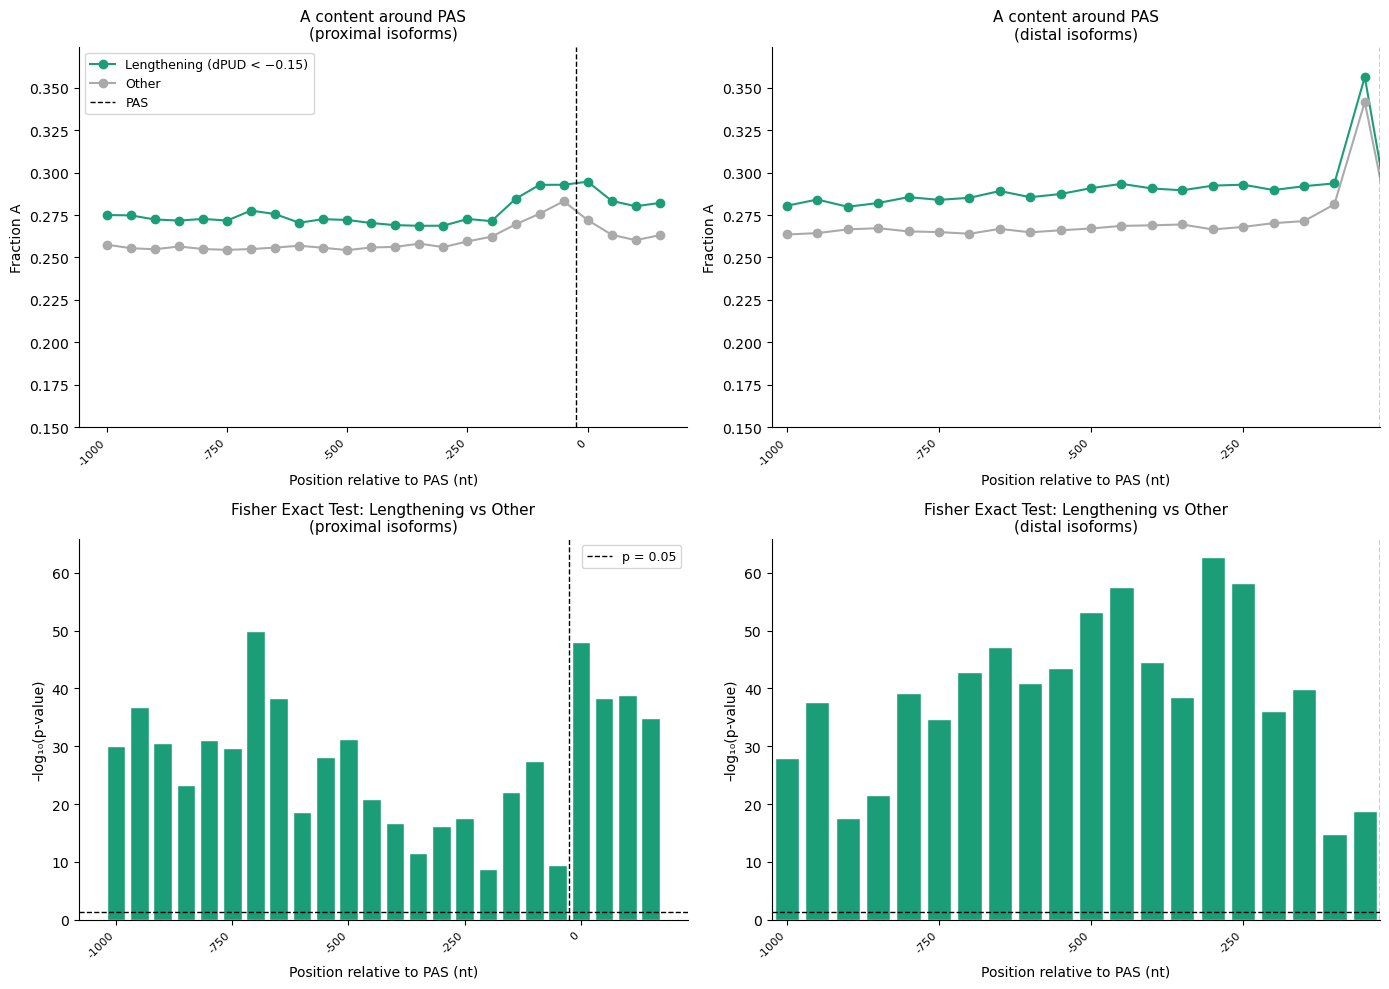

Computing C-content profile for proximal isoforms...


Computing C-content profile for distal isoforms...


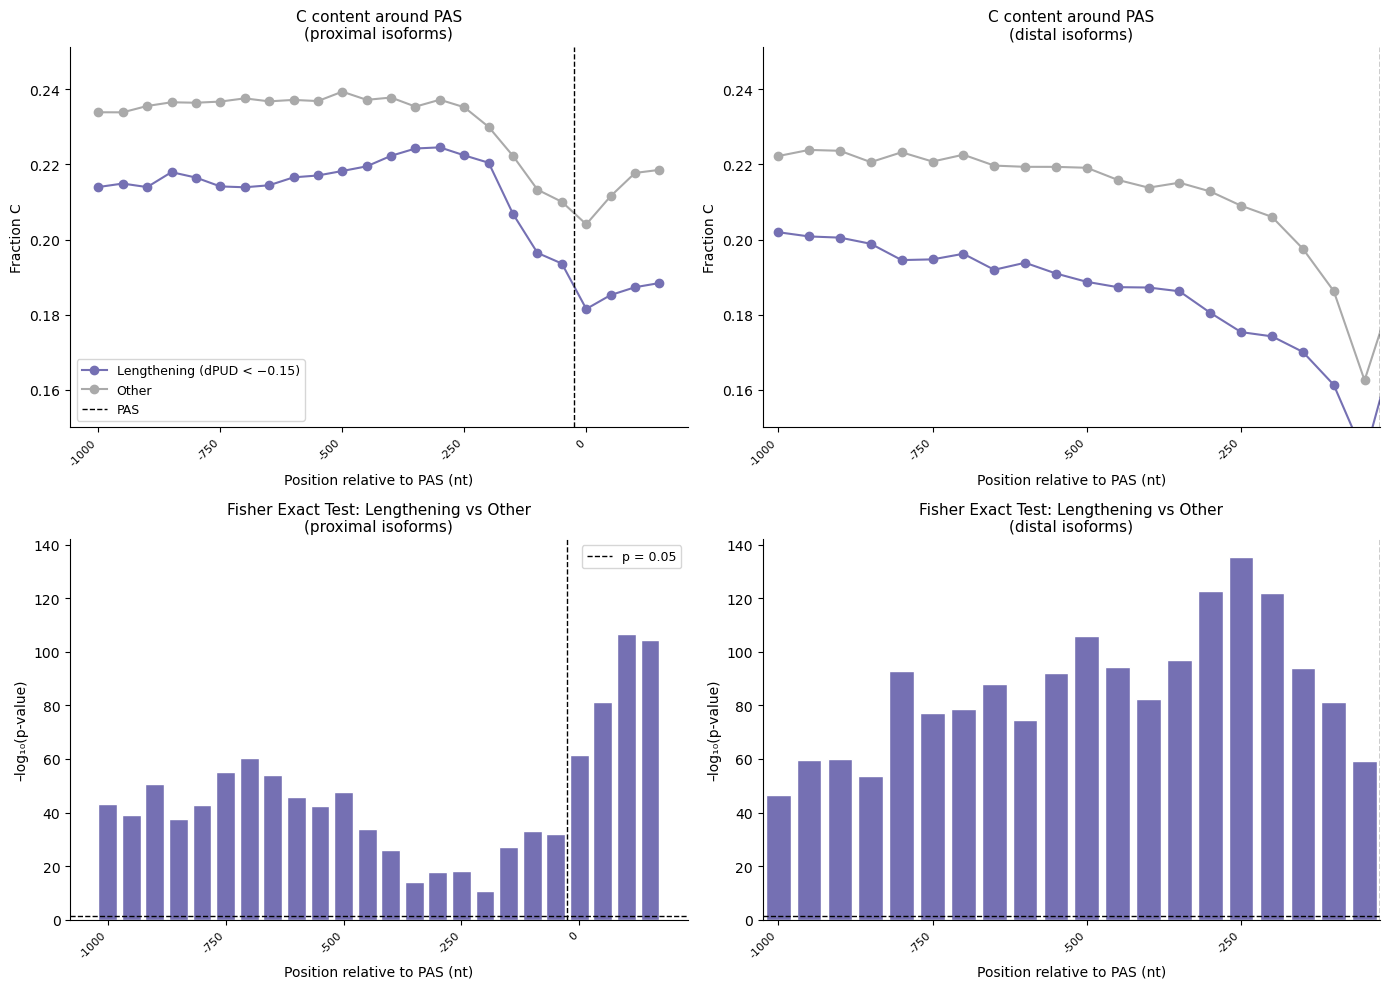

Computing G-content profile for proximal isoforms...


Computing G-content profile for distal isoforms...


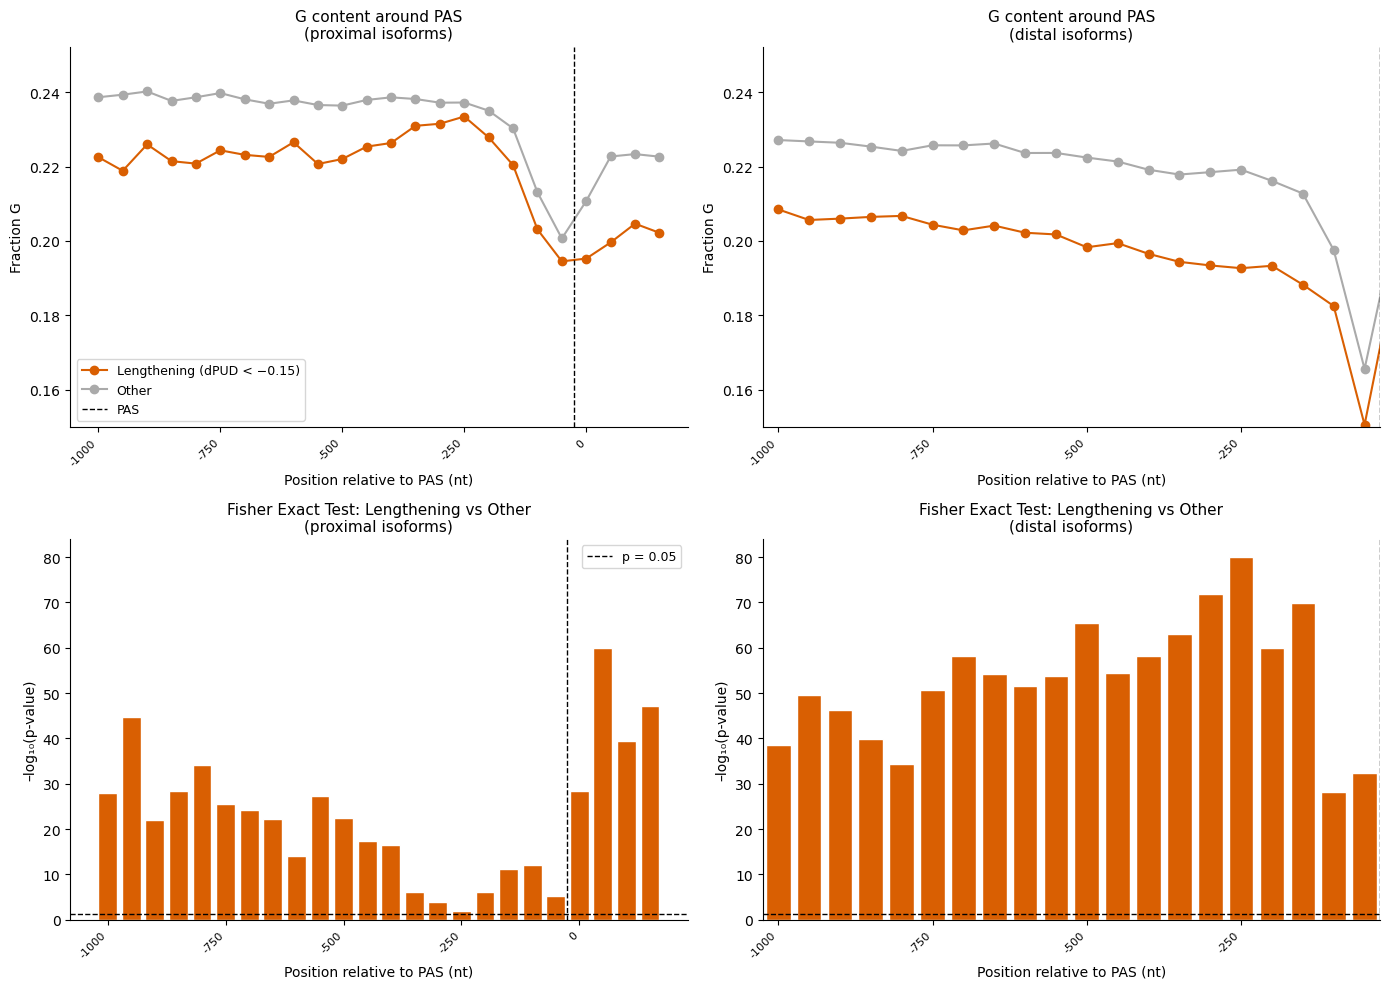

Computing U-content profile for proximal isoforms...


Computing U-content profile for distal isoforms...


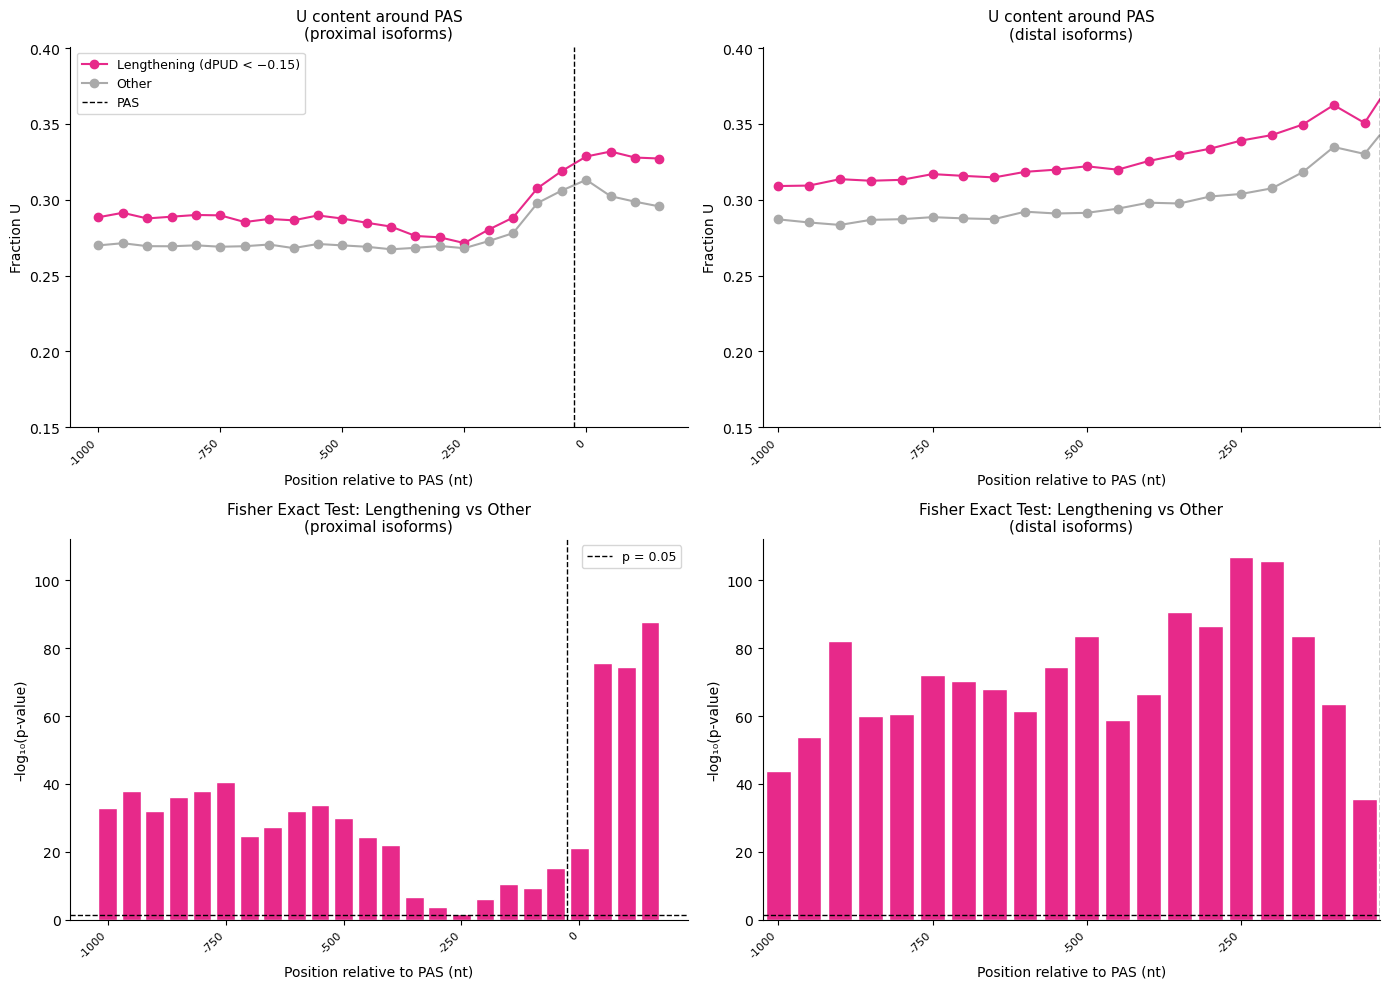

In [14]:
nt_colors = {'A': '#1b9e77', 'C': '#7570b3', 'G': '#d95f02', 'T': '#e7298a'}

for nt in NUCLEOTIDES:
    fig, axes, pvalues_nt = plot_nucleotide_window_profiles(nt, WINDOW_SIZE=50, color=nt_colors[nt], y_min=0.15)
    save_figure(f"{figures_subfolder}/{NT_LABEL[nt]}_content_around_PAS_nuclear_lengthened_D22_to_D35_CTRL.pdf",
                pattern="<nucleotides>_content_around_PAS_nuclear_lengthened_D22_to_D35_CTRL.pdf",
                legend="One file per nucleotide (A, C, G, U) and dinucleotide (AU, GC, GU, GA, AC, CU, AA, UU, CC, GG). Top: fraction of bases (or of overlapping dinucleotide positions) equal to it in each 50-nt window from -1000 to +200 nt around the PAS (hg38 sequence on the transcript strand, pooled over all transcripts), for 3'UTR pairs lengthened from D22 to D35 in CTRL nuclei (pairs_distals_D22_Nuclear_Wildtype_vs_D35_Nuclear_Wildtype) (coloured) vs all other pairs (grey; longest distal isoform per proximal), proximal (left) and distal (right, shown up to the PAS) isoform. Bottom: -log10(p) of a two-sided Fisher's exact test per window (coloured = p < 0.05, uncorrected; dashed line = p 0.05). The plot legend labels the group 'Lengthening' in every comparison.")
    plt.show()


### AU / GC / GU / GA / AC / CU / AA / UU / CC / GG dinucleotide content profiles (50 nt windows), Lengthening vs Other


Computing AU-content profile for proximal isoforms...


Computing AU-content profile for distal isoforms...


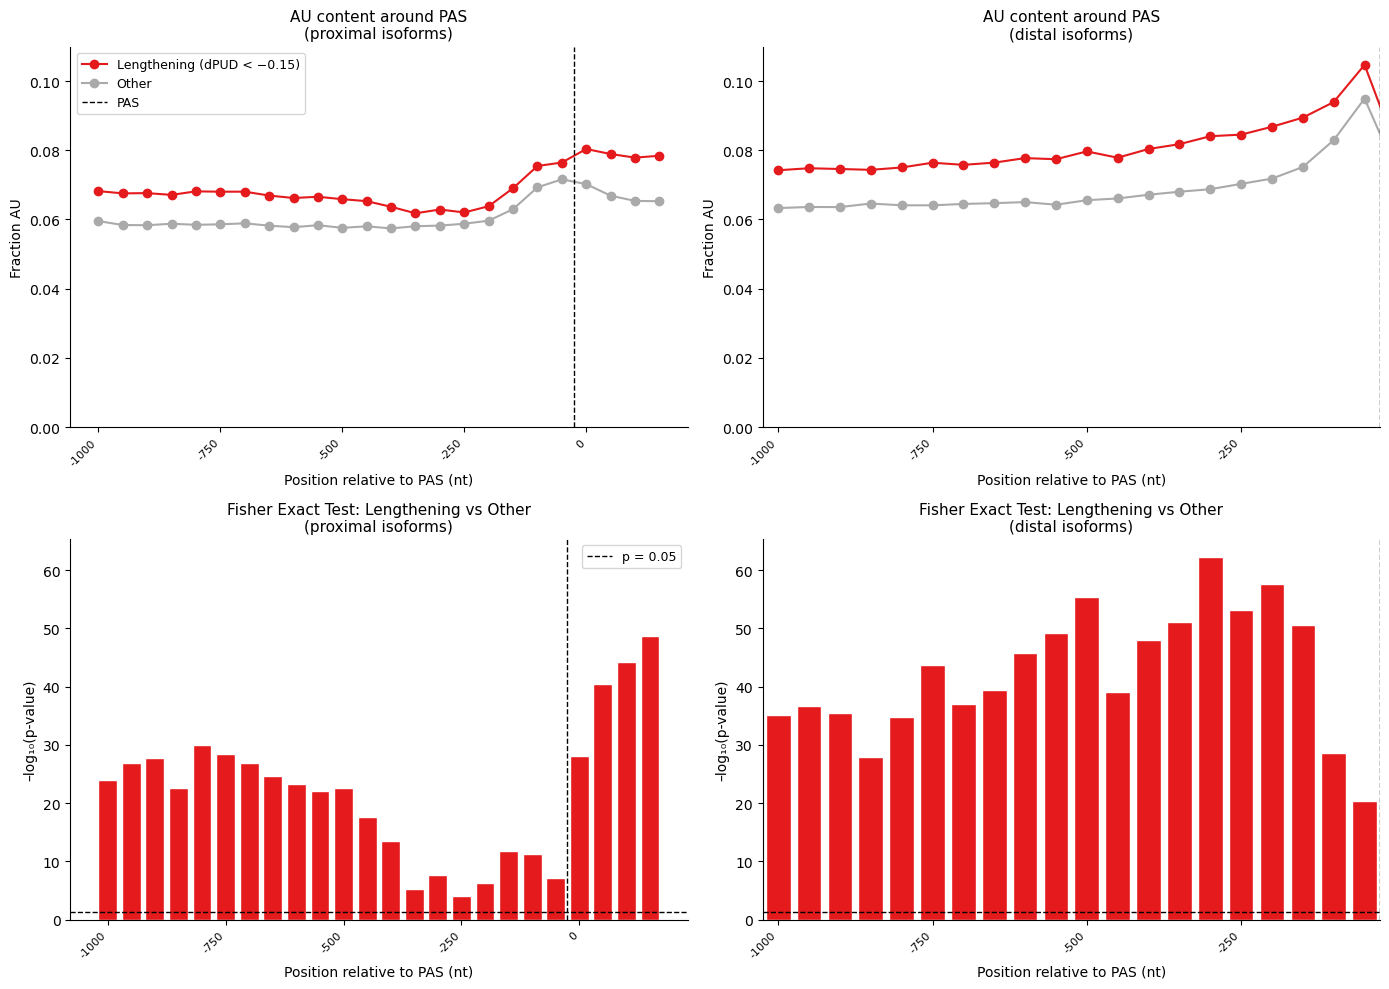

Computing GC-content profile for proximal isoforms...


Computing GC-content profile for distal isoforms...


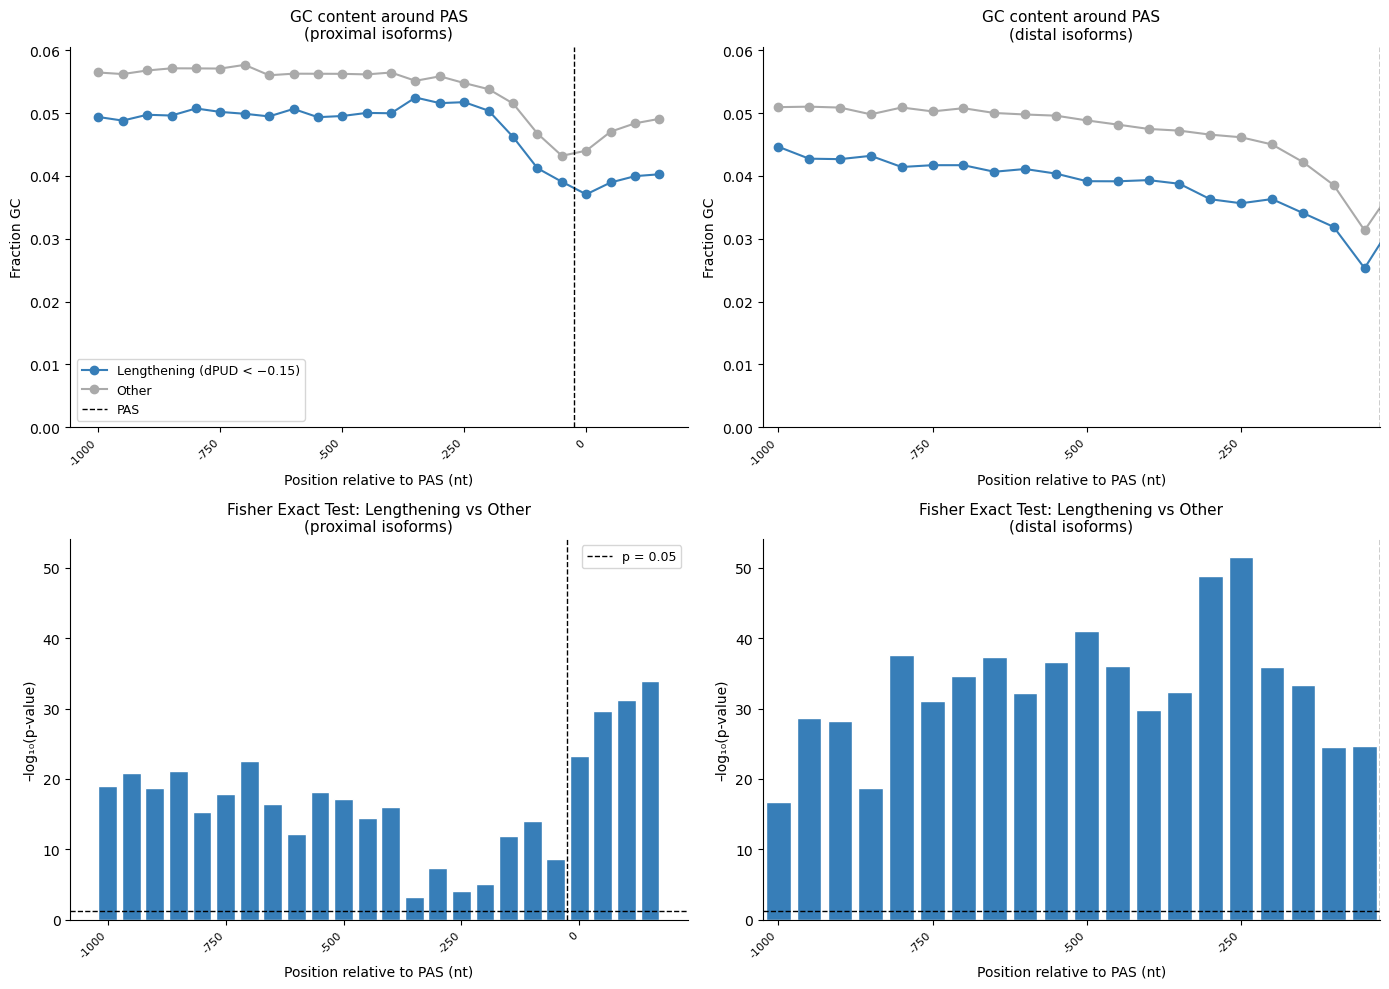

Computing GU-content profile for proximal isoforms...


Computing GU-content profile for distal isoforms...


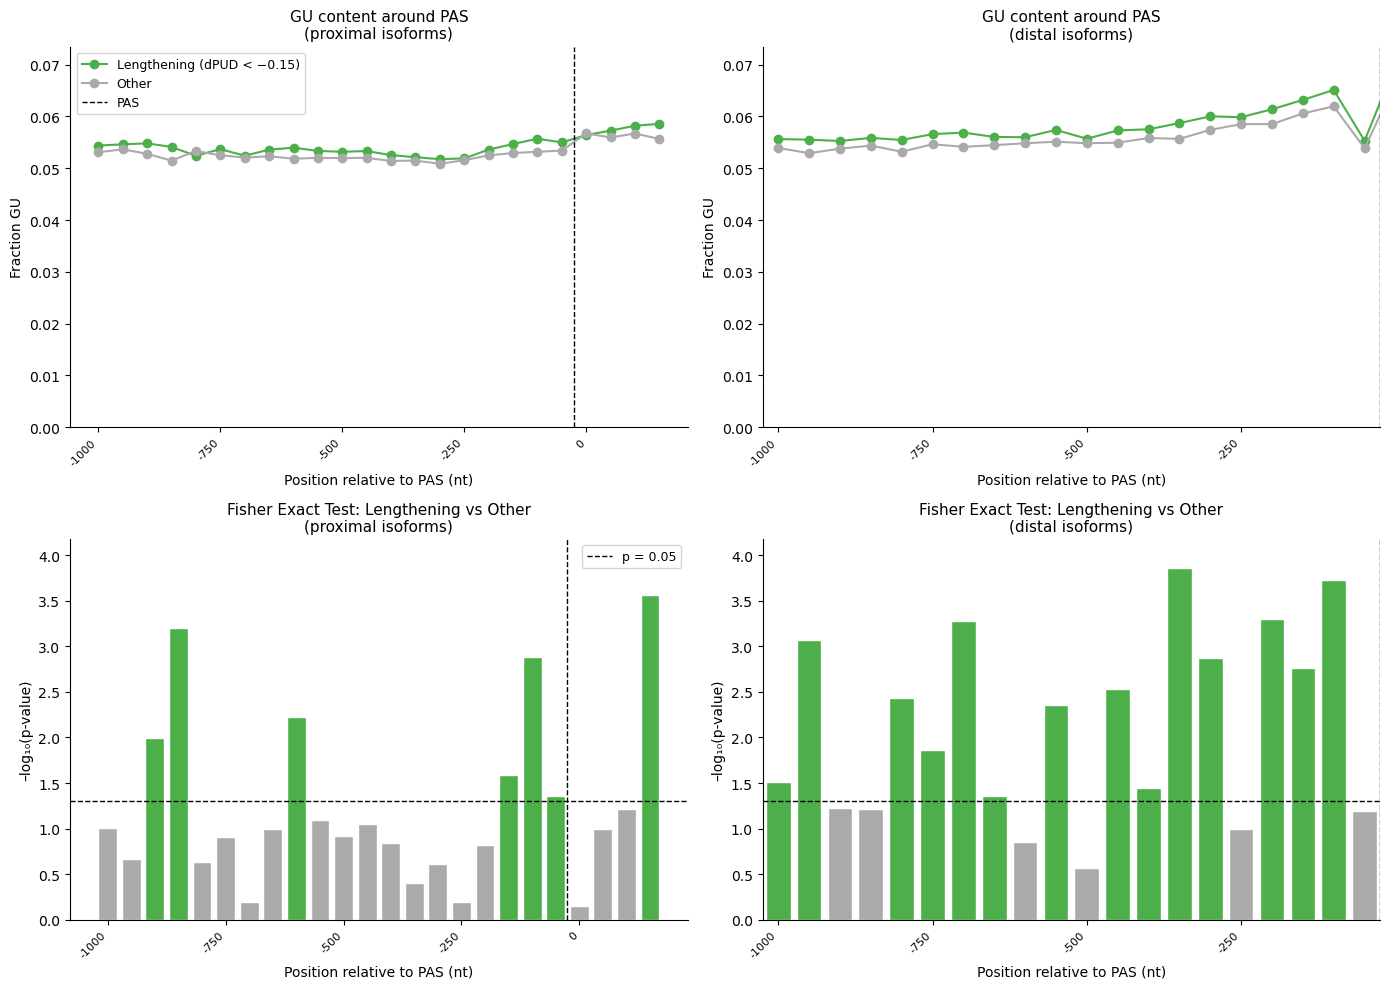

Computing GA-content profile for proximal isoforms...


Computing GA-content profile for distal isoforms...


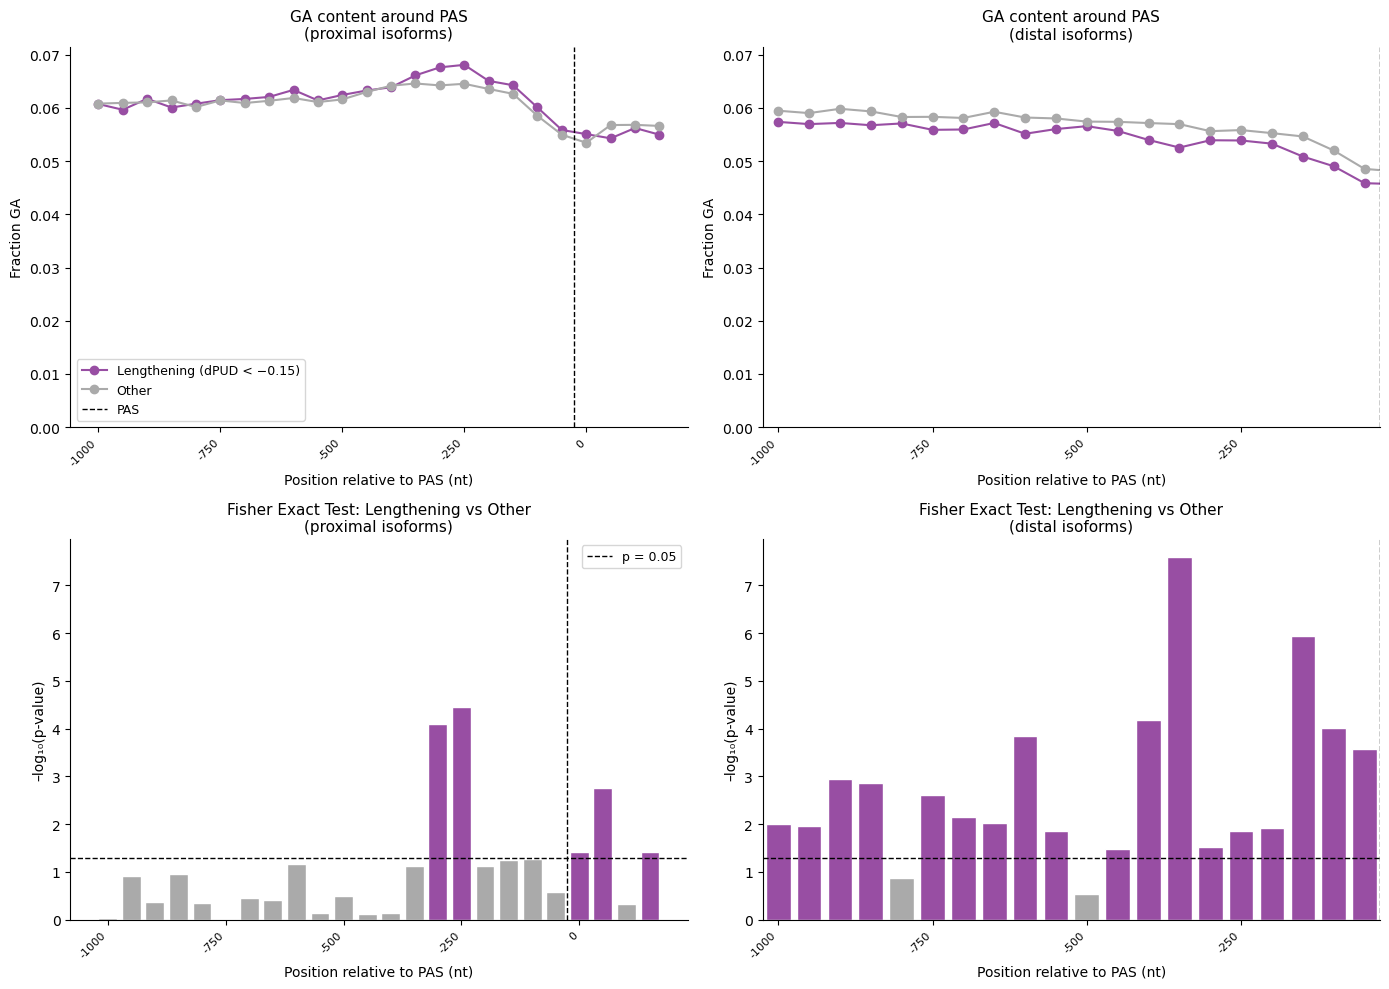

Computing AC-content profile for proximal isoforms...


Computing AC-content profile for distal isoforms...


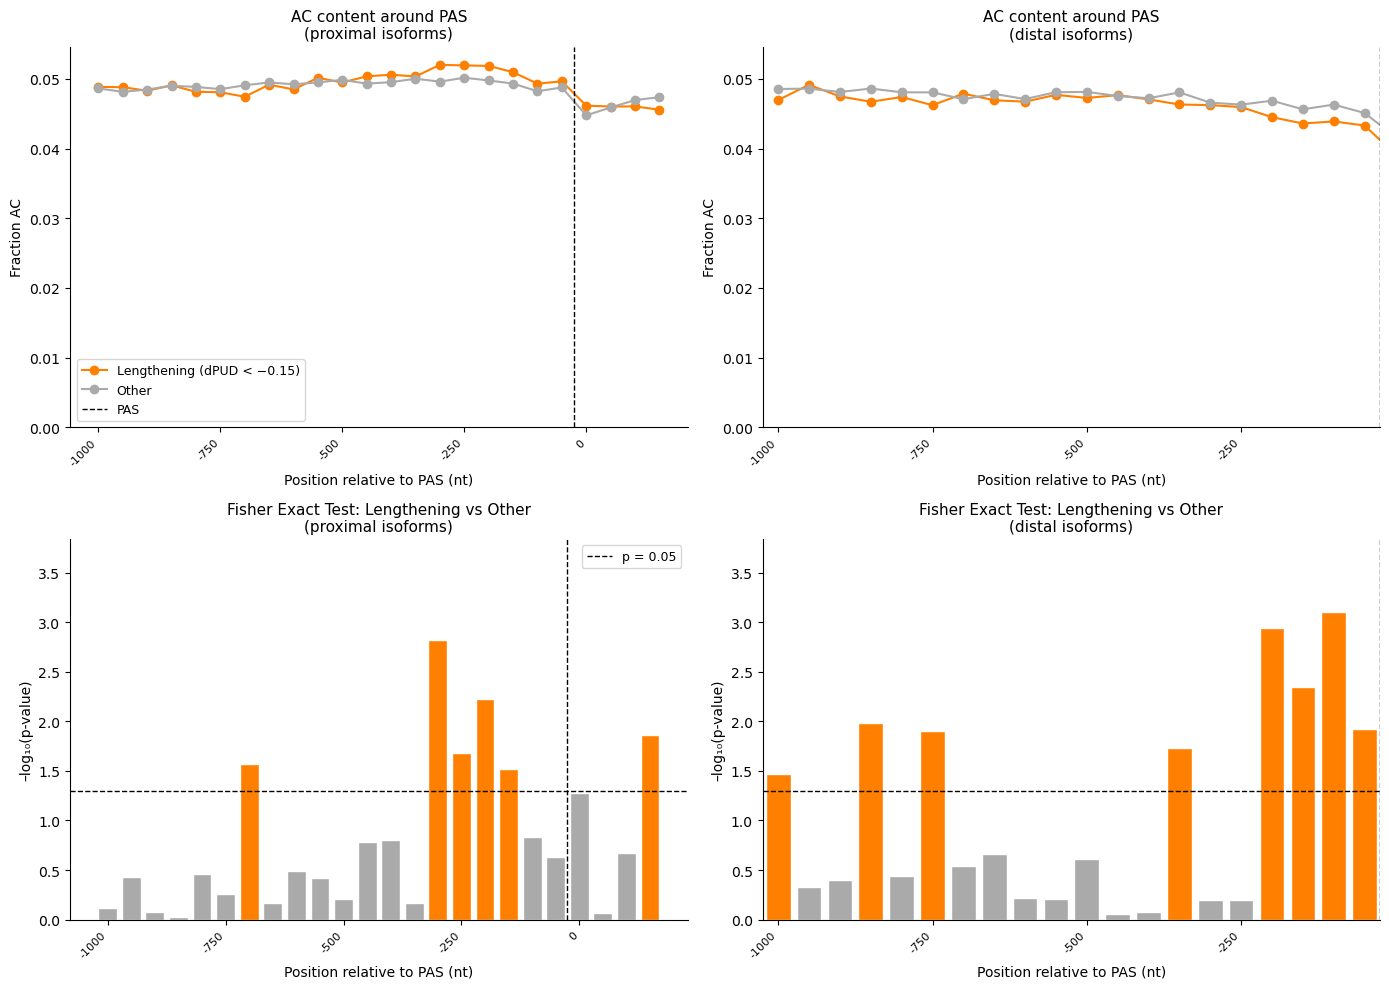

Computing CU-content profile for proximal isoforms...


Computing CU-content profile for distal isoforms...


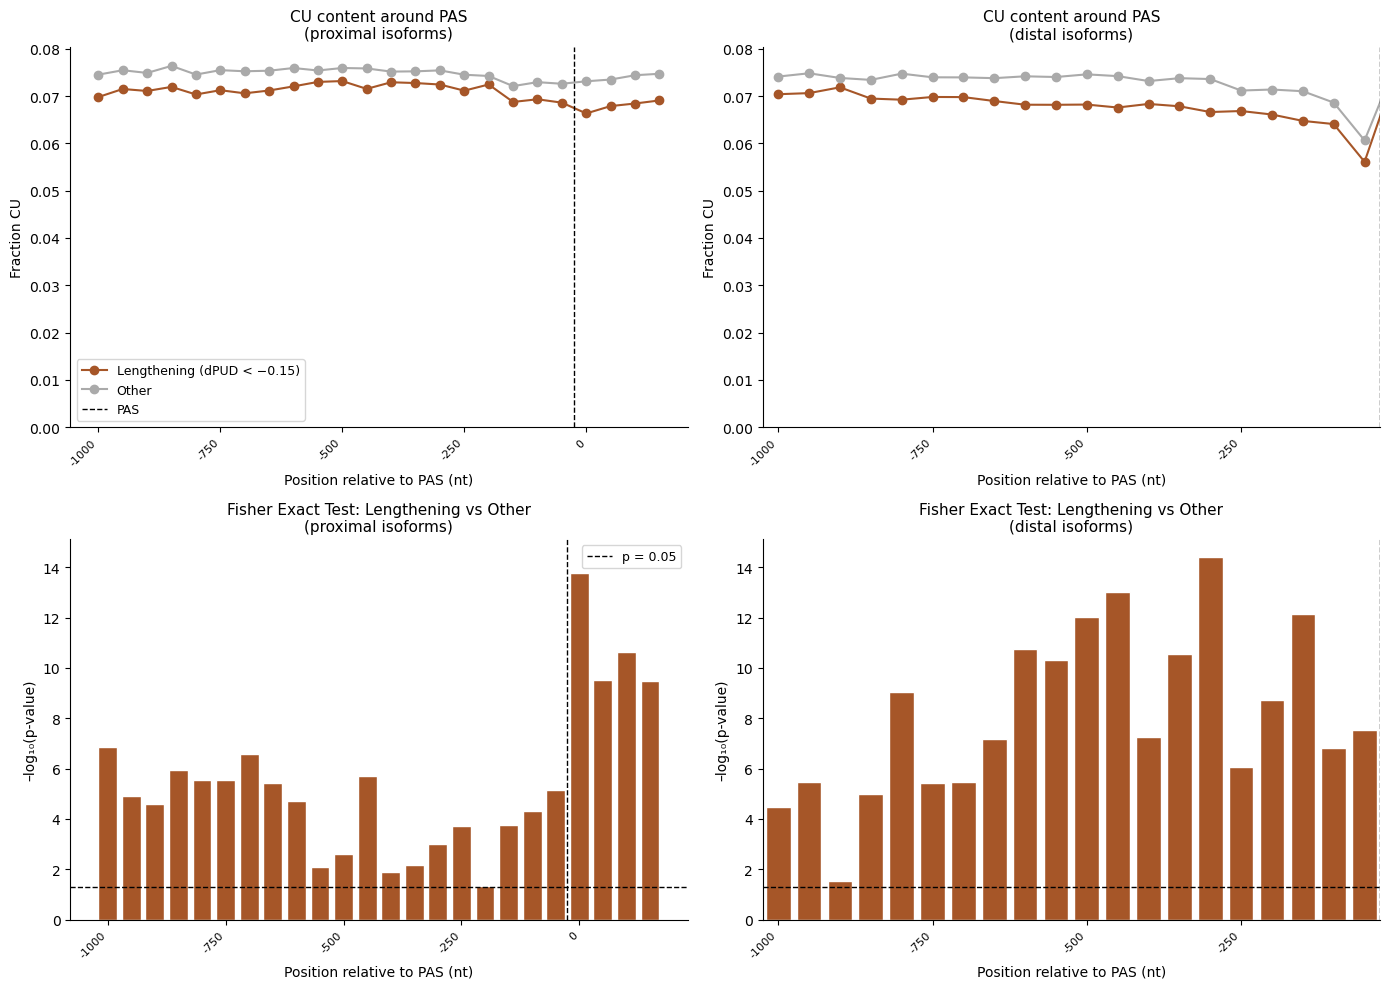

Computing AA-content profile for proximal isoforms...


Computing AA-content profile for distal isoforms...


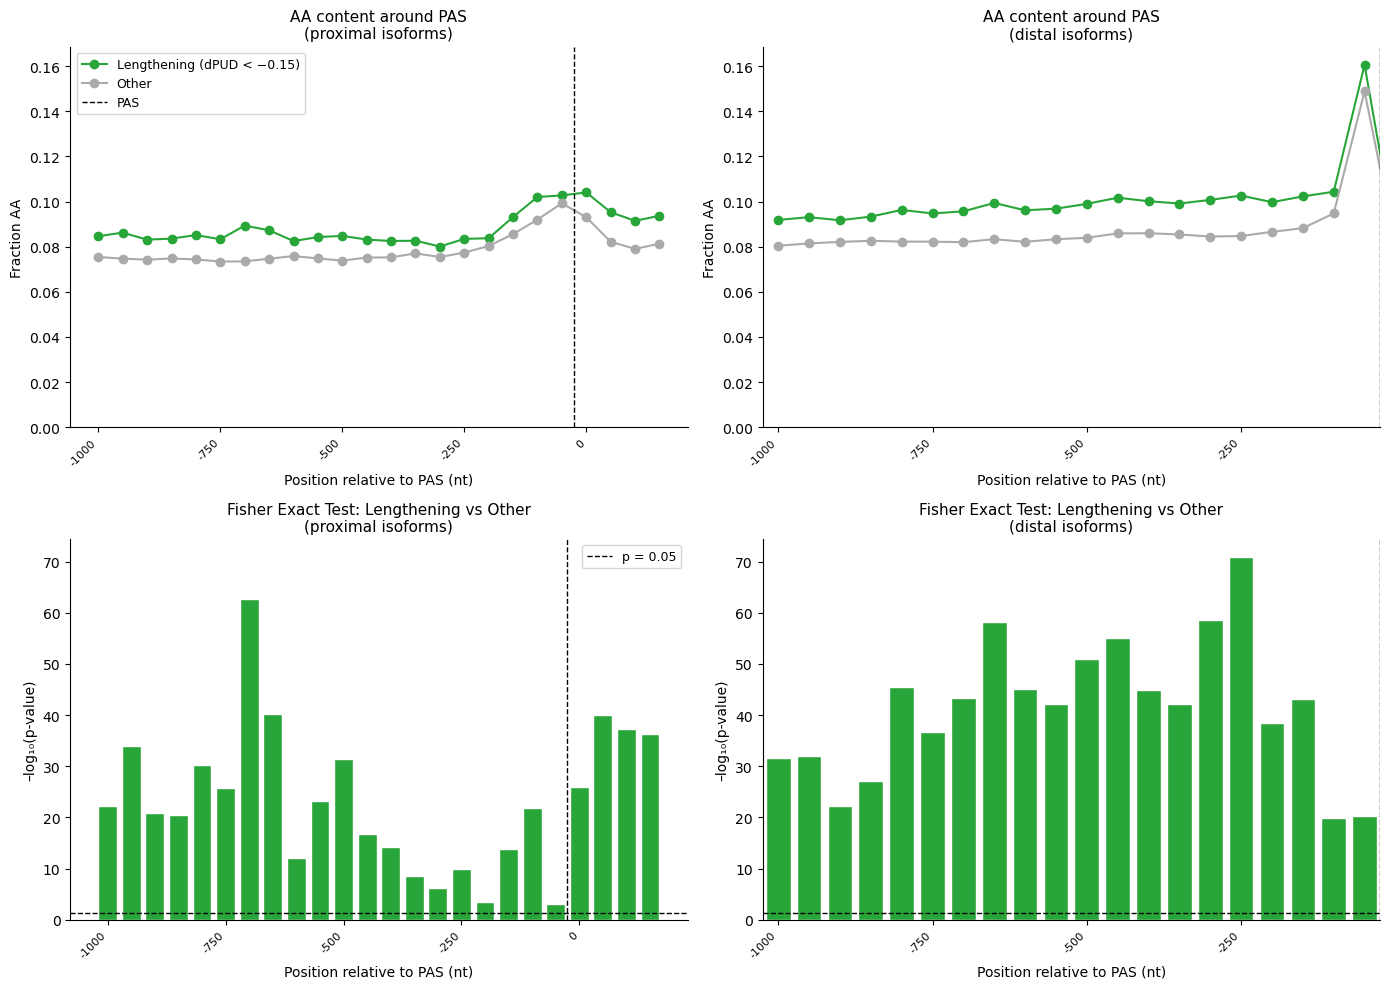

Computing UU-content profile for proximal isoforms...


Computing UU-content profile for distal isoforms...


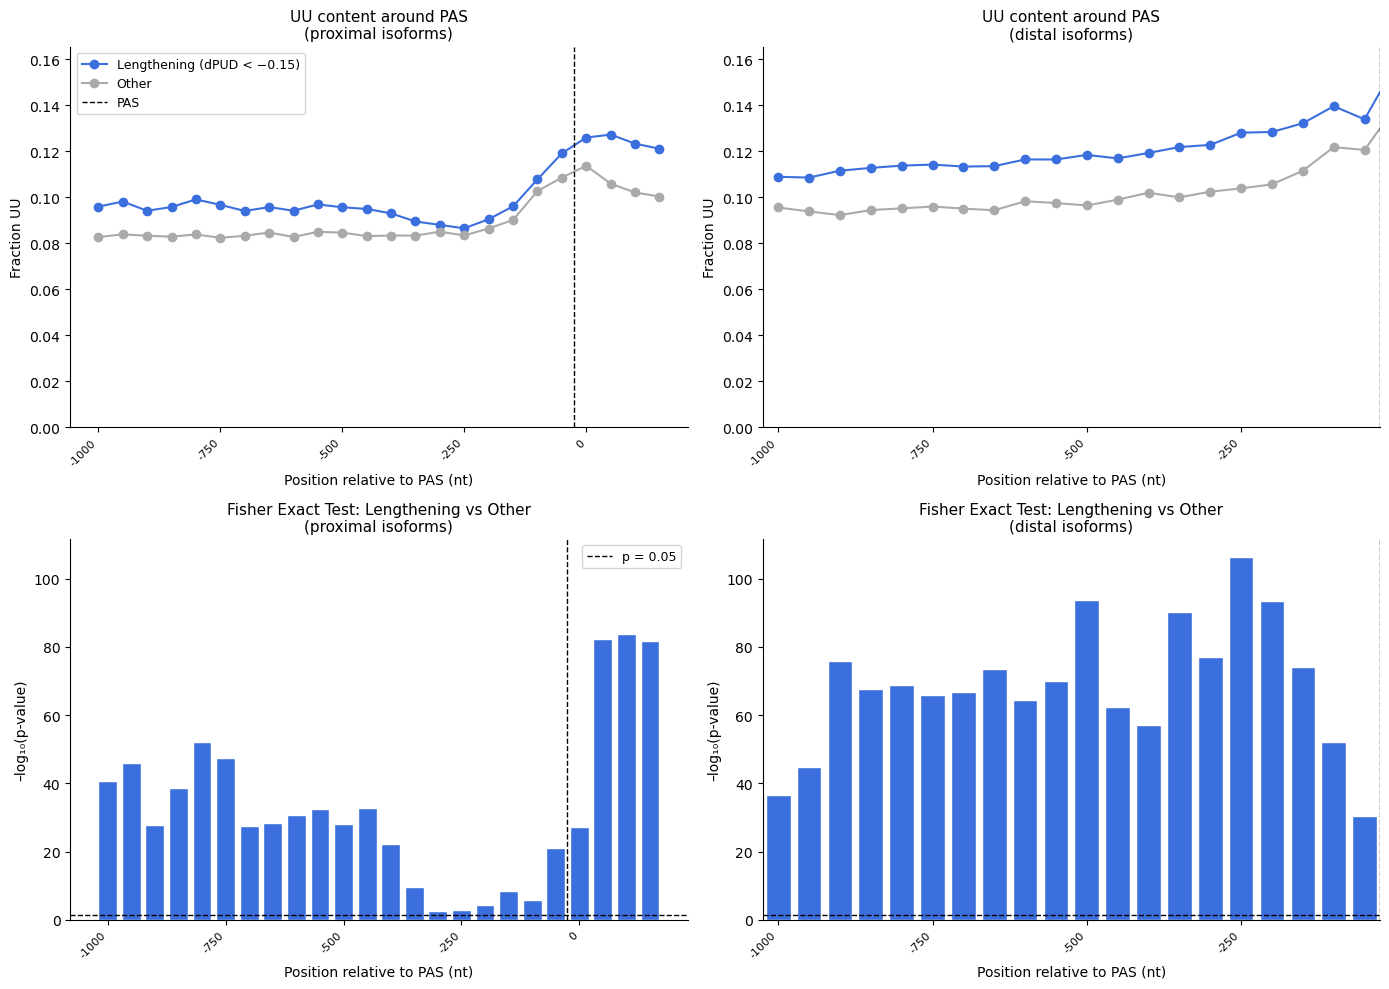

Computing CC-content profile for proximal isoforms...


Computing CC-content profile for distal isoforms...


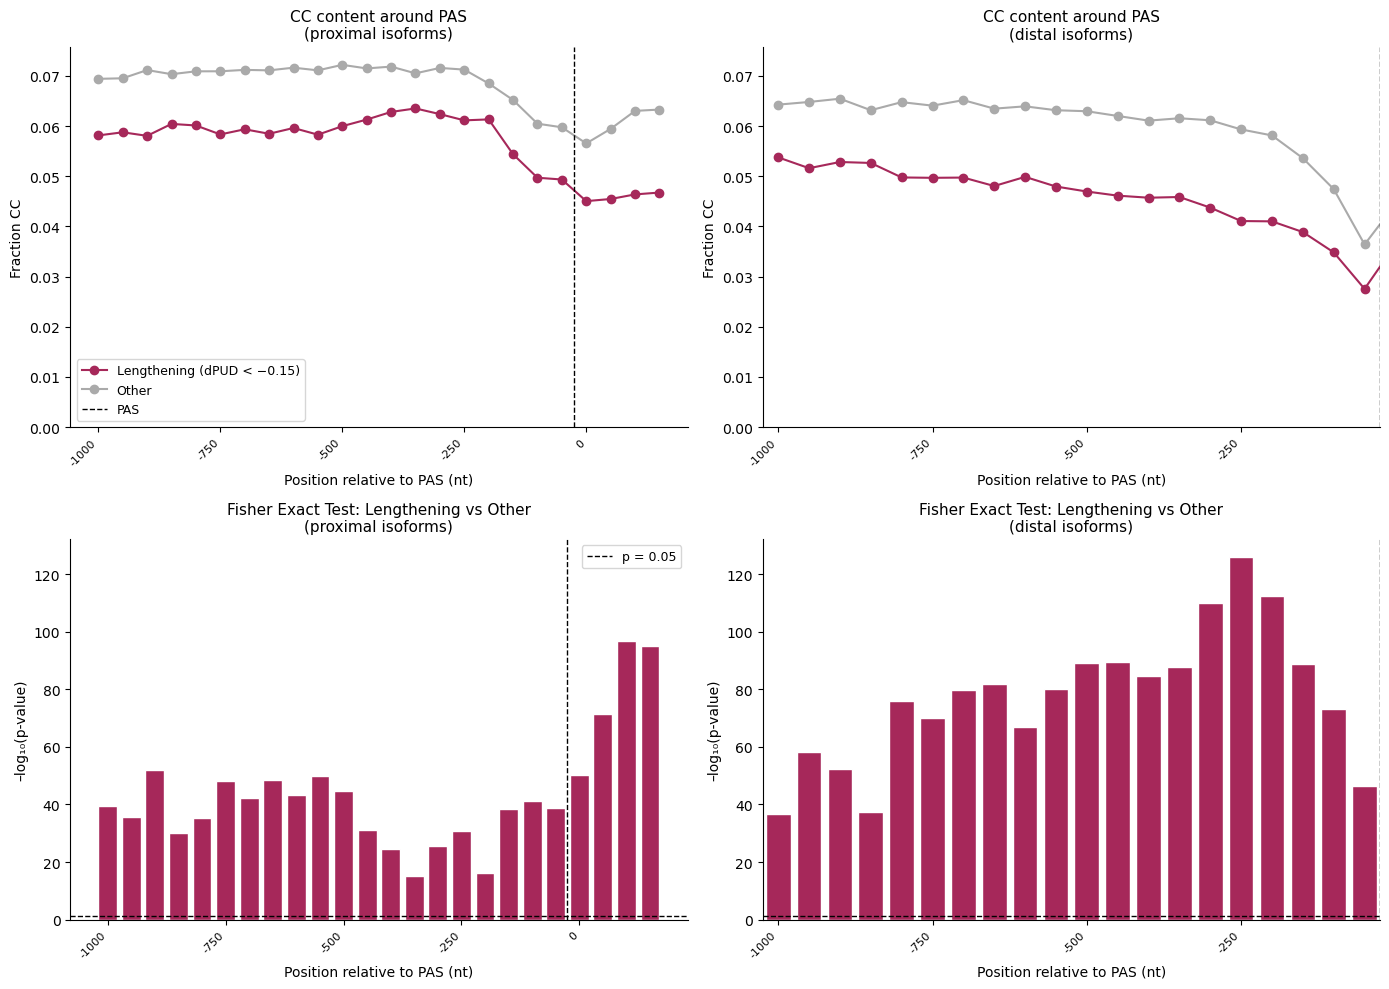

Computing GG-content profile for proximal isoforms...


Computing GG-content profile for distal isoforms...


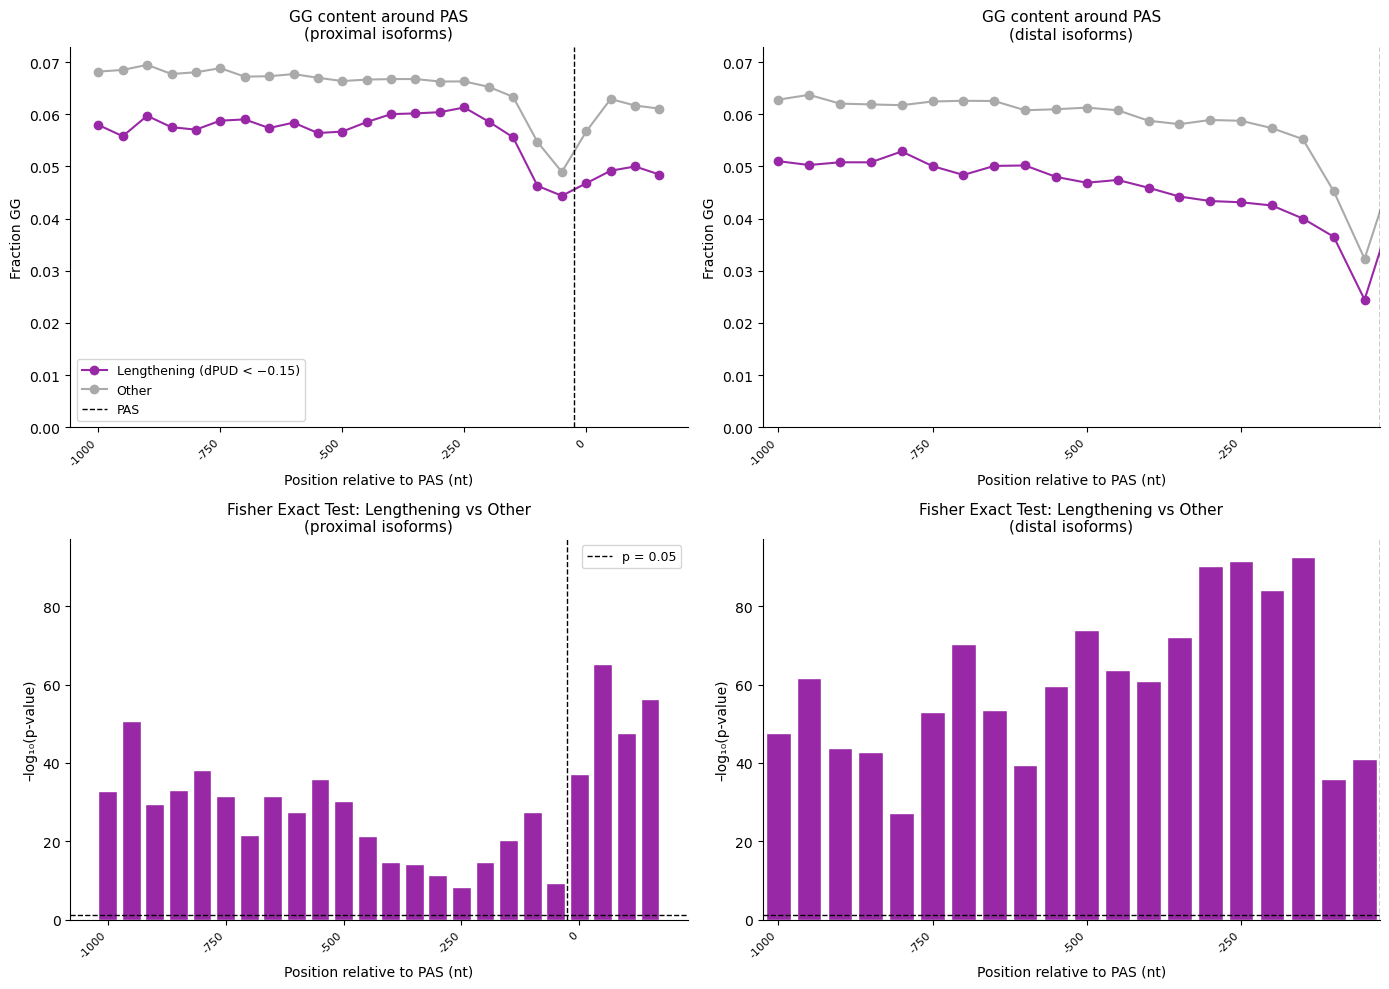

In [15]:
dimer_colors = {'AT': '#e41a1c', 'GC': '#377eb8', 'GT': '#4daf4a', 'GA': '#984ea3', 'AC': '#ff7f00', 'CT': '#a65628', 'AA': "#28a639",'TT': "#3c6fde", 'GG': "#9928a6", 'CC': "#a6285a"}

for dimer in DIMERS:
    fig, axes, pvalues_dimer = plot_dimer_window_profiles(dimer, WINDOW_SIZE=50, color=dimer_colors[dimer], y_min=0)
    save_figure(f"{figures_subfolder}/{DIMER_LABEL[dimer]}_content_around_PAS_nuclear_lengthened_D22_to_D35_CTRL.pdf",
                pattern="<nucleotides>_content_around_PAS_nuclear_lengthened_D22_to_D35_CTRL.pdf",
                legend="One file per nucleotide (A, C, G, U) and dinucleotide (AU, GC, GU, GA, AC, CU, AA, UU, CC, GG). Top: fraction of bases (or of overlapping dinucleotide positions) equal to it in each 50-nt window from -1000 to +200 nt around the PAS (hg38 sequence on the transcript strand, pooled over all transcripts), for 3'UTR pairs lengthened from D22 to D35 in CTRL nuclei (pairs_distals_D22_Nuclear_Wildtype_vs_D35_Nuclear_Wildtype) (coloured) vs all other pairs (grey; longest distal isoform per proximal), proximal (left) and distal (right, shown up to the PAS) isoform. Bottom: -log10(p) of a two-sided Fisher's exact test per window (coloured = p < 0.05, uncorrected; dashed line = p 0.05). The plot legend labels the group 'Lengthening' in every comparison.")
    plt.show()


## Pairs lengthened from D22 to D35 in the CTRL cytoplasm

`pairs_distals_D22_Cytoplasmic_Wildtype_vs_D35_Cytoplasmic_Wildtype.csv` vs all other pairs; same profiles. Saved: `<nucleotide>_content_around_PAS_cytoplasmic_lengthened_D22_to_D35_CTRL.pdf`.

In [16]:
fisher_sig_lengthening = pd.read_csv(f"{path_to_shift}/pairs_distals_D22_Cytoplasmic_Wildtype_vs_D35_Cytoplasmic_Wildtype.csv")
fisher_sig_lengthening = fisher_sig_lengthening[fisher_sig_lengthening['distal_id'].isin(table_of_pairs_longest['distal_id'])]
fisher_other = table_of_pairs_longest[~table_of_pairs_longest['distal_id'].isin(fisher_sig_lengthening['distal_id'])][["proximal_id", "distal_id"]]

full_window_seqs = {}
for iso_type in ['proximal', 'distal']:
    col_name = f"{iso_type}_id"
    full_window_seqs[(iso_type, 'Lengthening')] = get_window_sequences(fisher_sig_lengthening, col_name, pas_lookup, hg38_fasta, WL_FULL, WR_FULL)
    full_window_seqs[(iso_type, 'Other')] = get_window_sequences(fisher_other, col_name, pas_lookup, hg38_fasta, WL_FULL, WR_FULL)
    print(f"{iso_type}: Lengthening n={len(full_window_seqs[(iso_type, 'Lengthening')])}, "
          f"Other n={len(full_window_seqs[(iso_type, 'Other')])}")


proximal: Lengthening n=271, Other n=7606
distal: Lengthening n=271, Other n=7606


Computing A-content profile for proximal isoforms...


Computing A-content profile for distal isoforms...


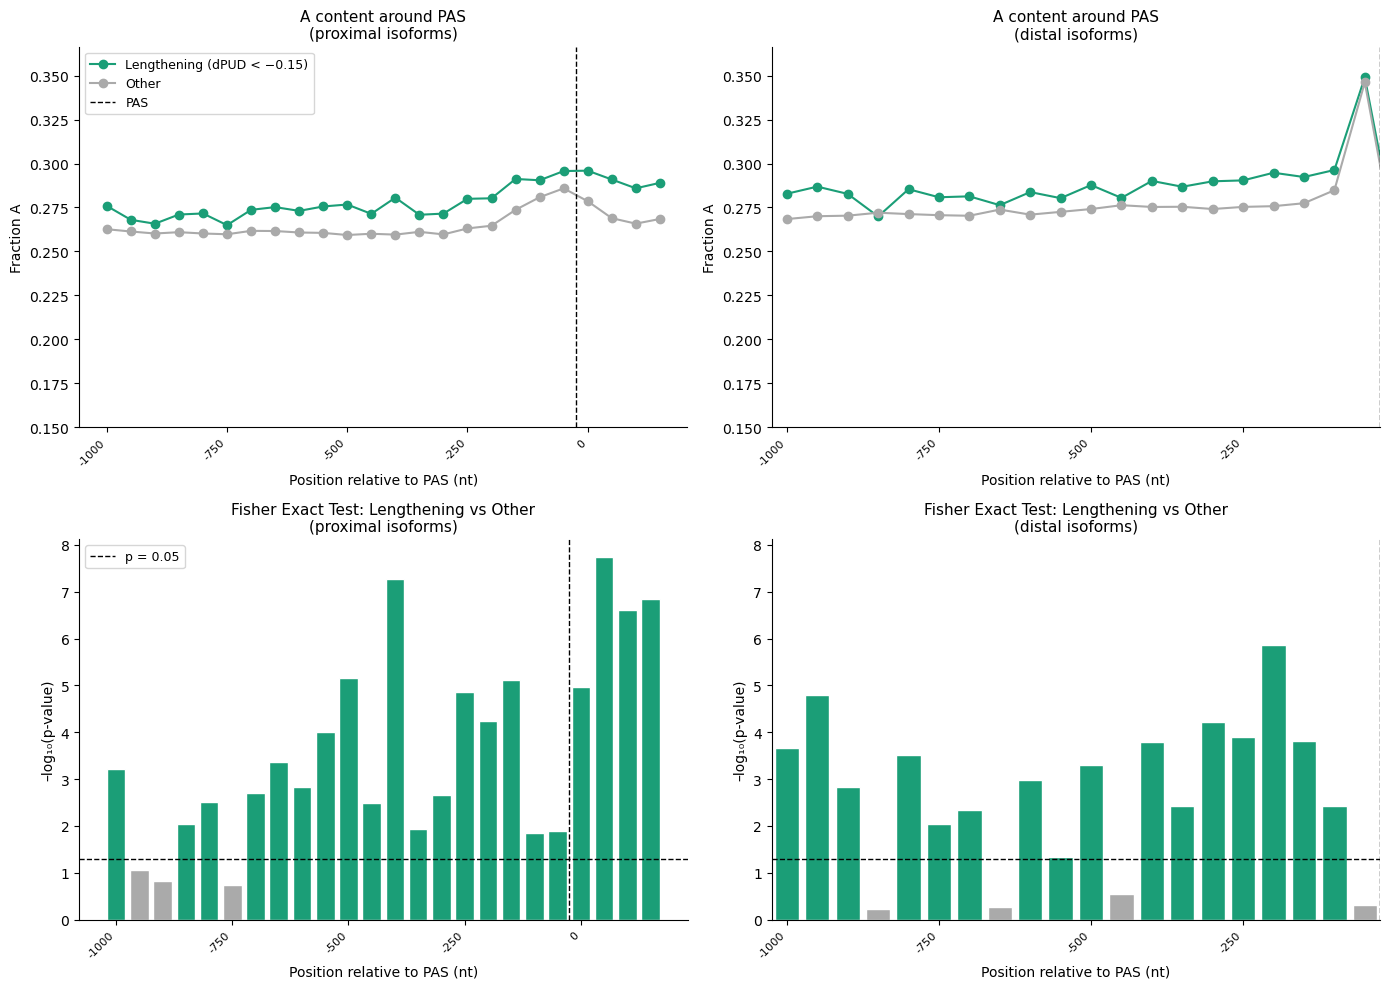

Computing C-content profile for proximal isoforms...


Computing C-content profile for distal isoforms...


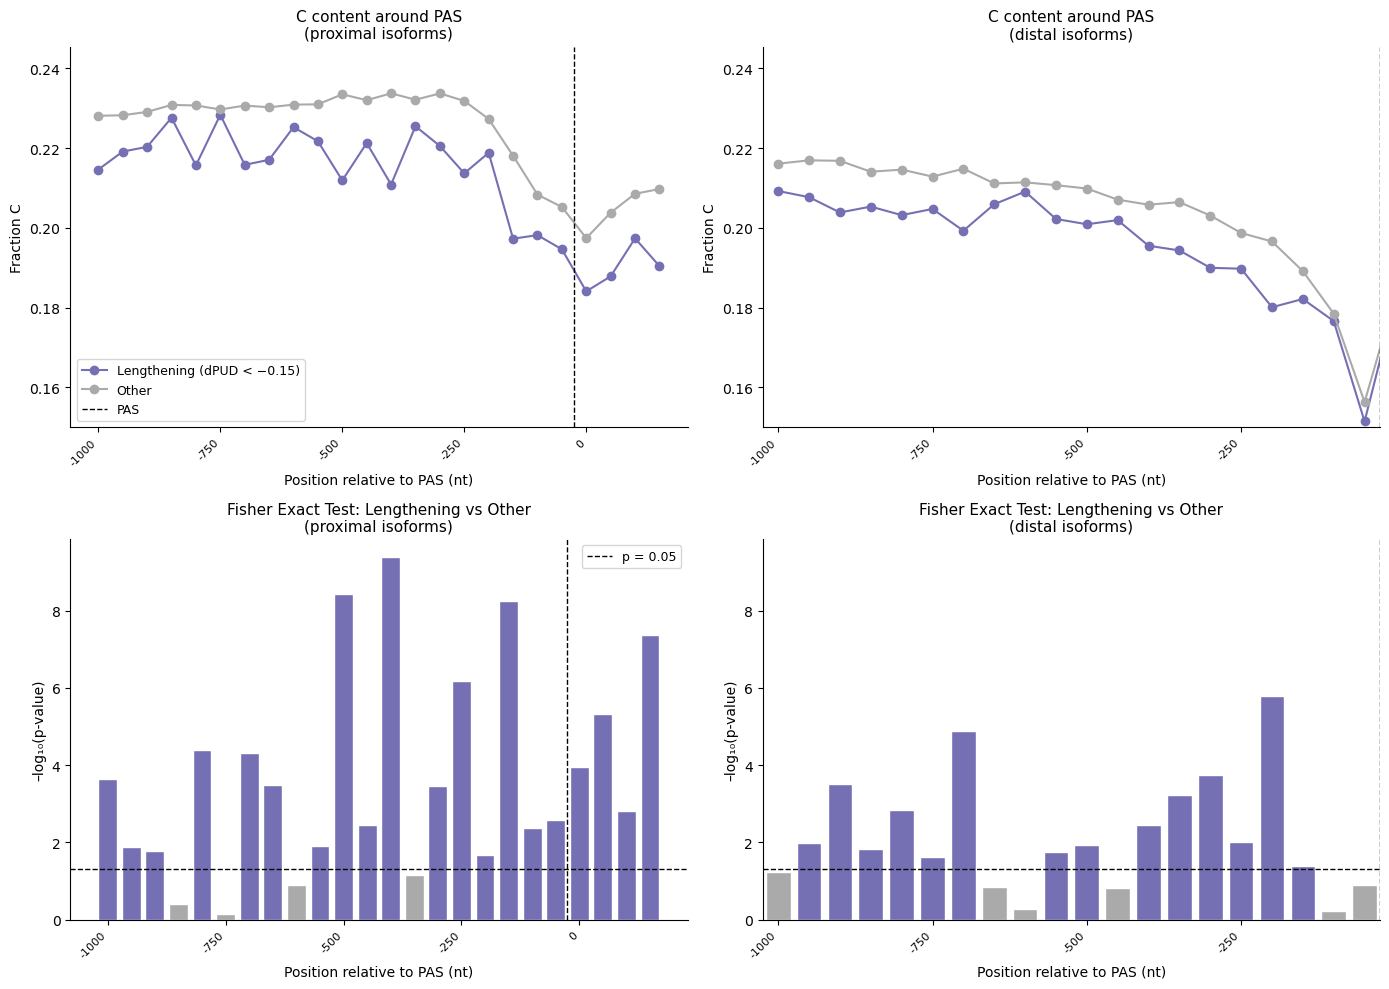

Computing G-content profile for proximal isoforms...


Computing G-content profile for distal isoforms...


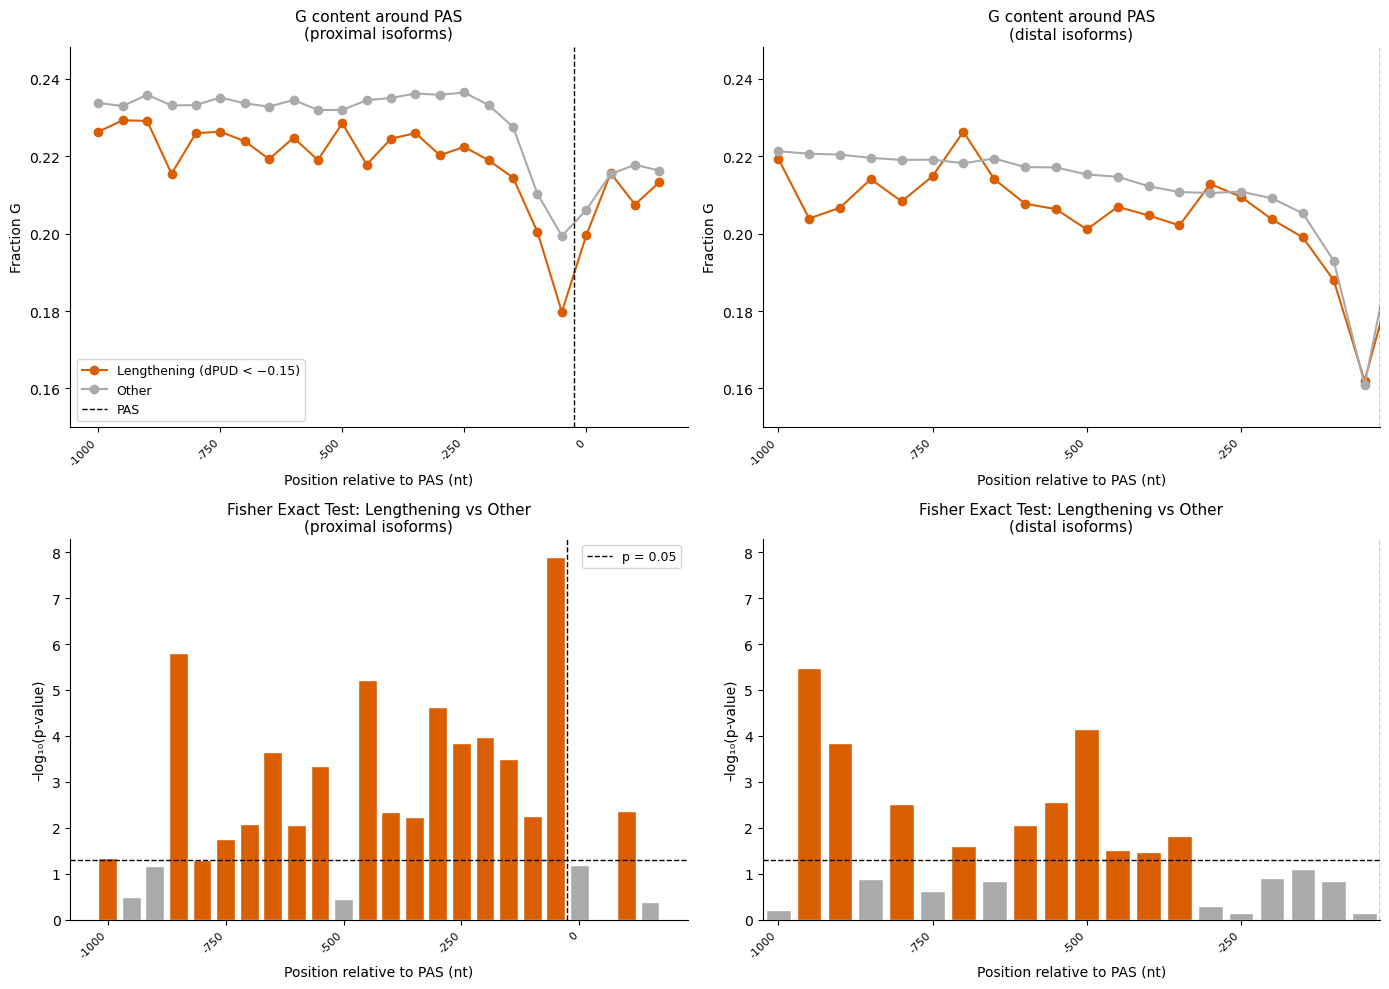

Computing U-content profile for proximal isoforms...


Computing U-content profile for distal isoforms...


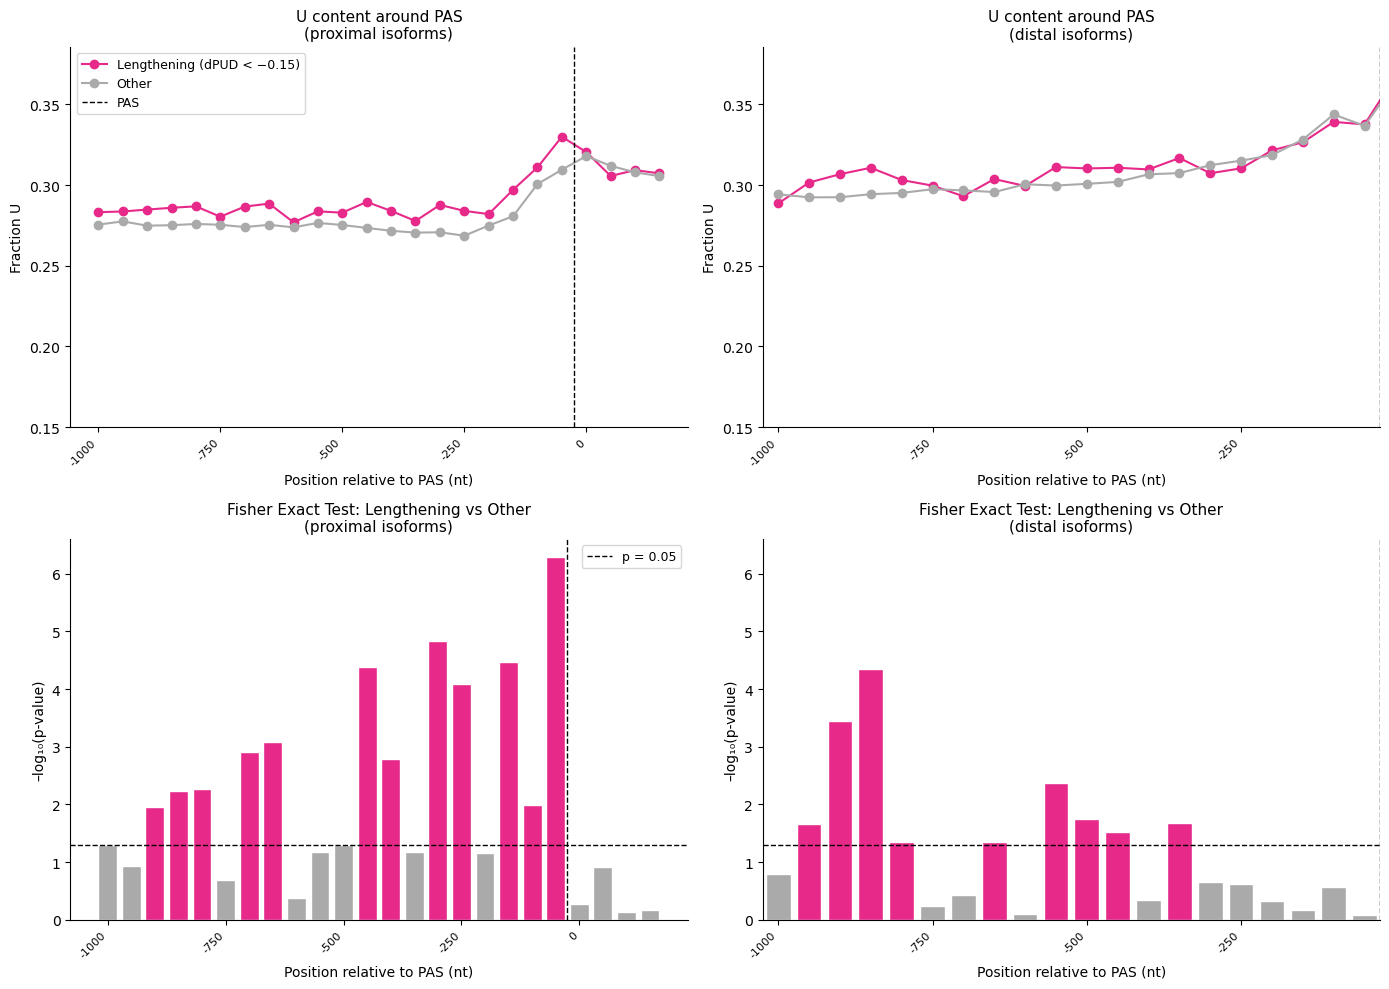

In [17]:
nt_colors = {'A': '#1b9e77', 'C': '#7570b3', 'G': '#d95f02', 'T': '#e7298a'}

for nt in NUCLEOTIDES:
    fig, axes, pvalues_nt = plot_nucleotide_window_profiles(nt, WINDOW_SIZE=50, color=nt_colors[nt], y_min=0.15)
    save_figure(f"{figures_subfolder}/{NT_LABEL[nt]}_content_around_PAS_cytoplasmic_lengthened_D22_to_D35_CTRL.pdf",
                pattern="<nucleotides>_content_around_PAS_cytoplasmic_lengthened_D22_to_D35_CTRL.pdf",
                legend="One file per nucleotide (A, C, G, U) and dinucleotide (AU, GC, GU, GA, AC, CU, AA, UU, CC, GG). Top: fraction of bases (or of overlapping dinucleotide positions) equal to it in each 50-nt window from -1000 to +200 nt around the PAS (hg38 sequence on the transcript strand, pooled over all transcripts), for 3'UTR pairs lengthened from D22 to D35 in the CTRL cytoplasm (pairs_distals_D22_Cytoplasmic_Wildtype_vs_D35_Cytoplasmic_Wildtype) (coloured) vs all other pairs (grey; longest distal isoform per proximal), proximal (left) and distal (right, shown up to the PAS) isoform. Bottom: -log10(p) of a two-sided Fisher's exact test per window (coloured = p < 0.05, uncorrected; dashed line = p 0.05). The plot legend labels the group 'Lengthening' in every comparison.")
    plt.show()


Computing AU-content profile for proximal isoforms...


Computing AU-content profile for distal isoforms...


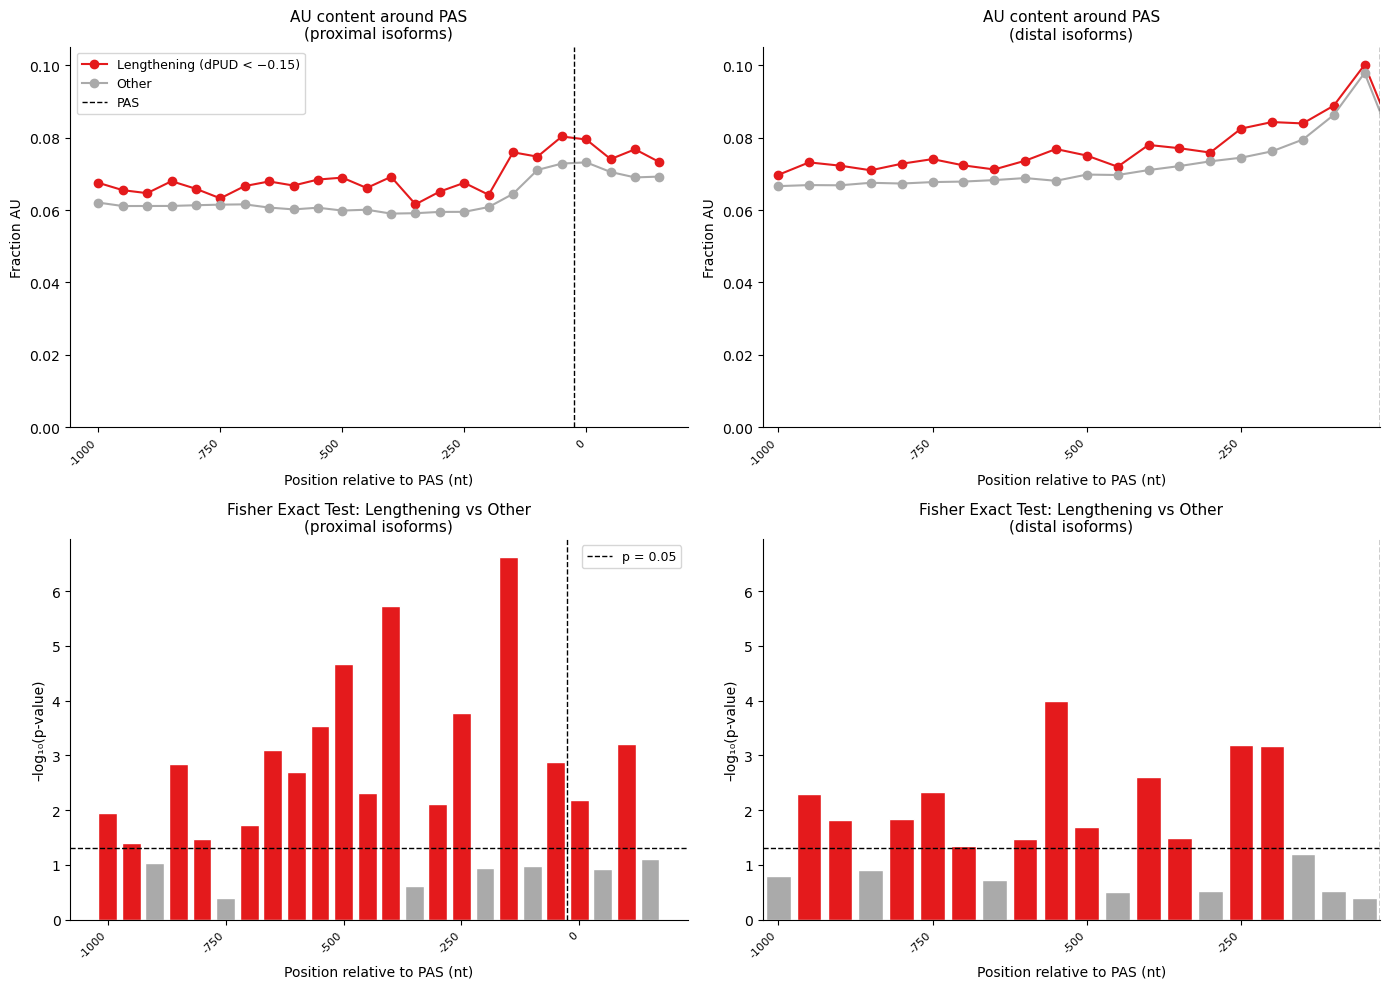

Computing GC-content profile for proximal isoforms...


Computing GC-content profile for distal isoforms...


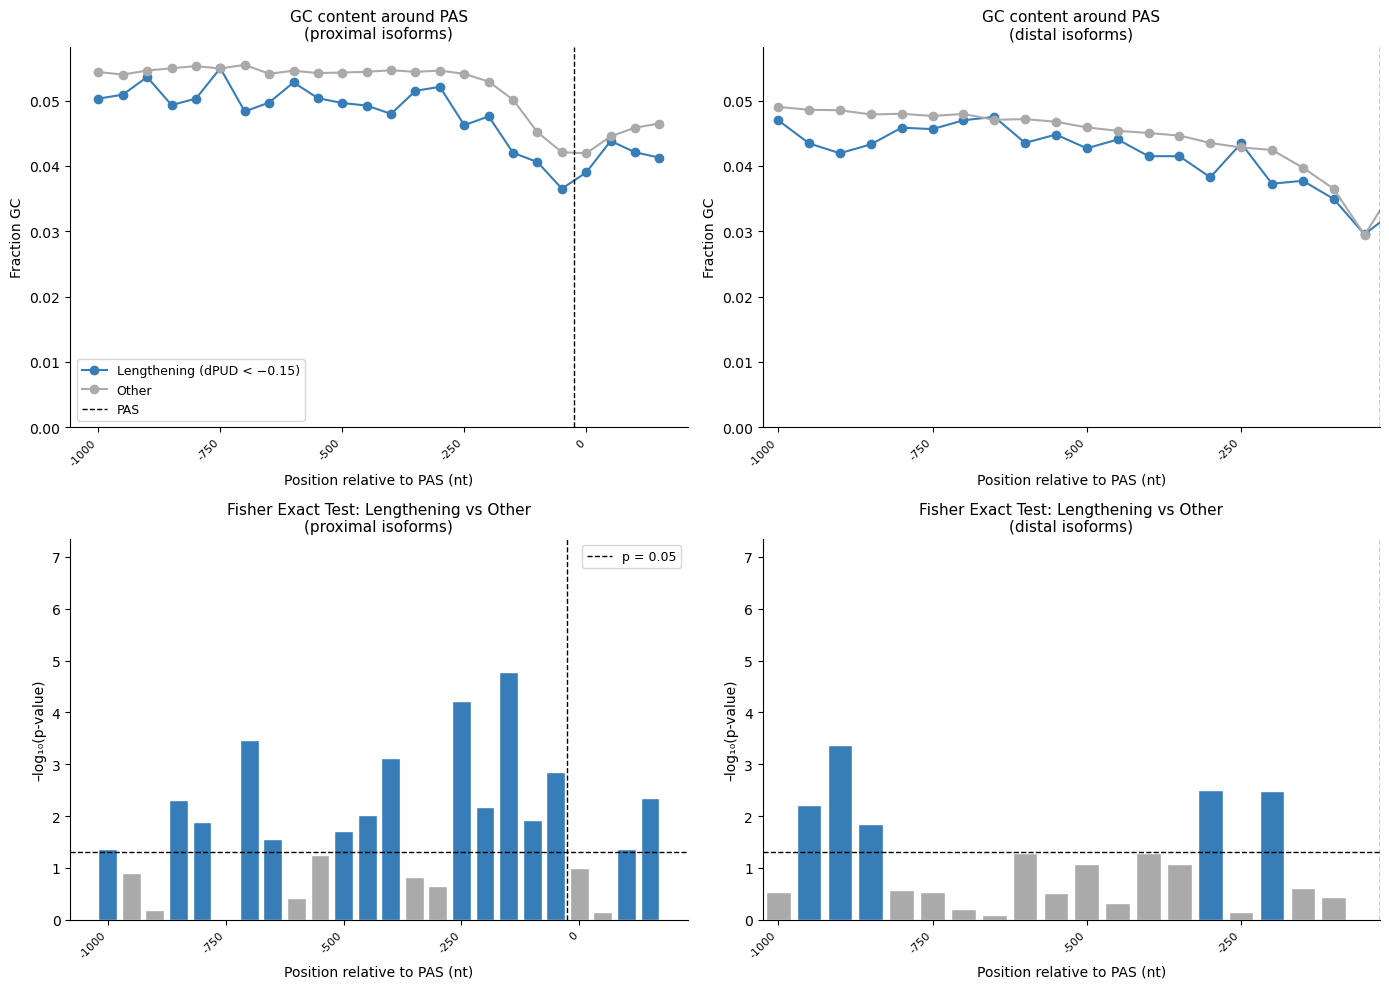

Computing GU-content profile for proximal isoforms...


Computing GU-content profile for distal isoforms...


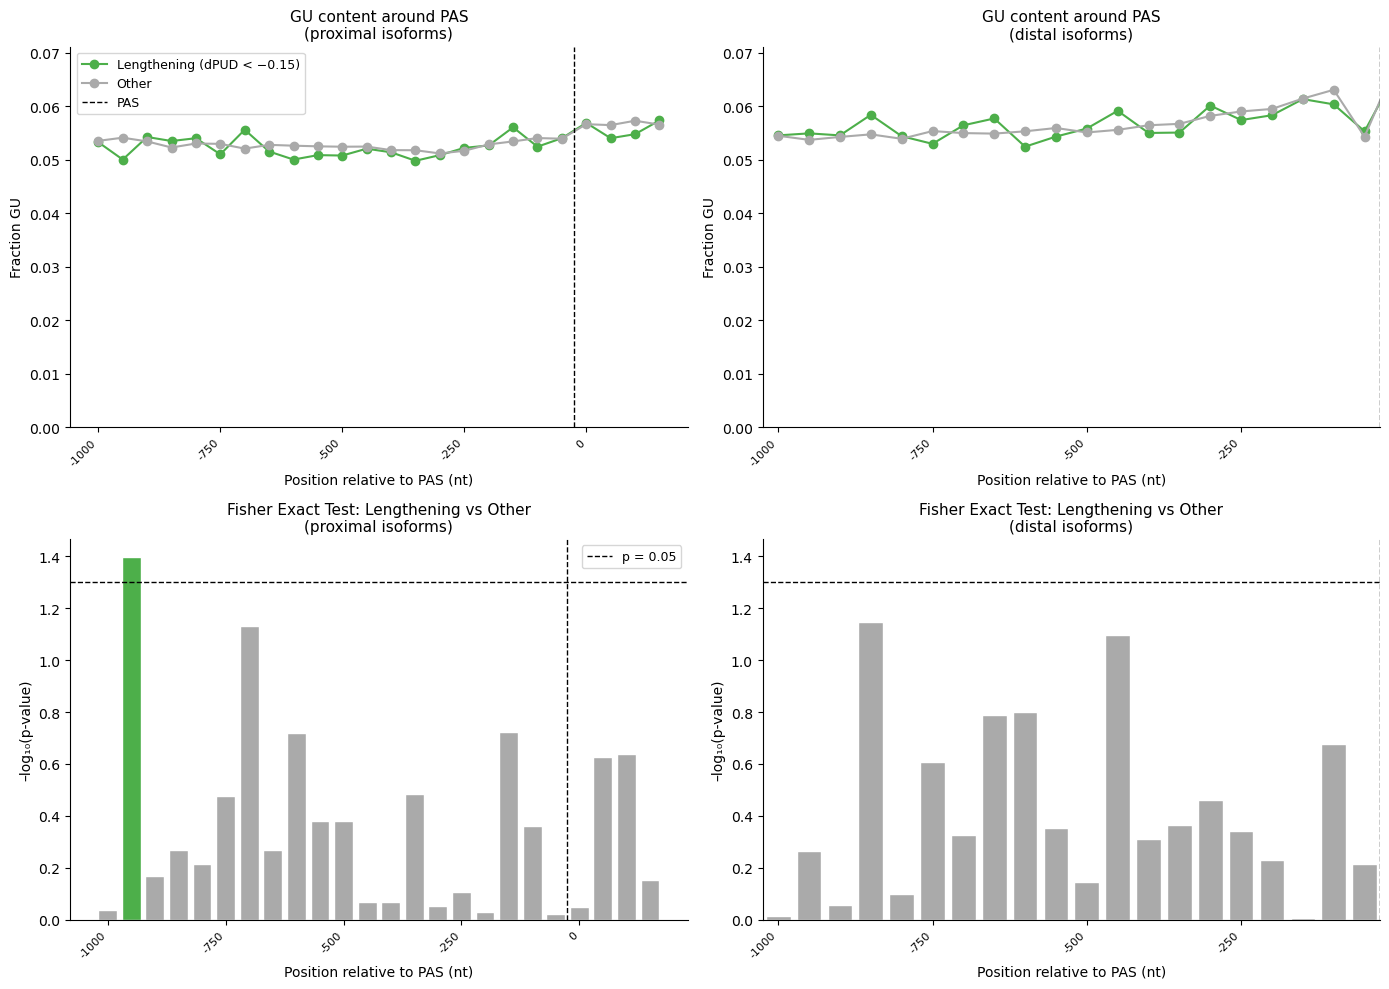

Computing GA-content profile for proximal isoforms...


Computing GA-content profile for distal isoforms...


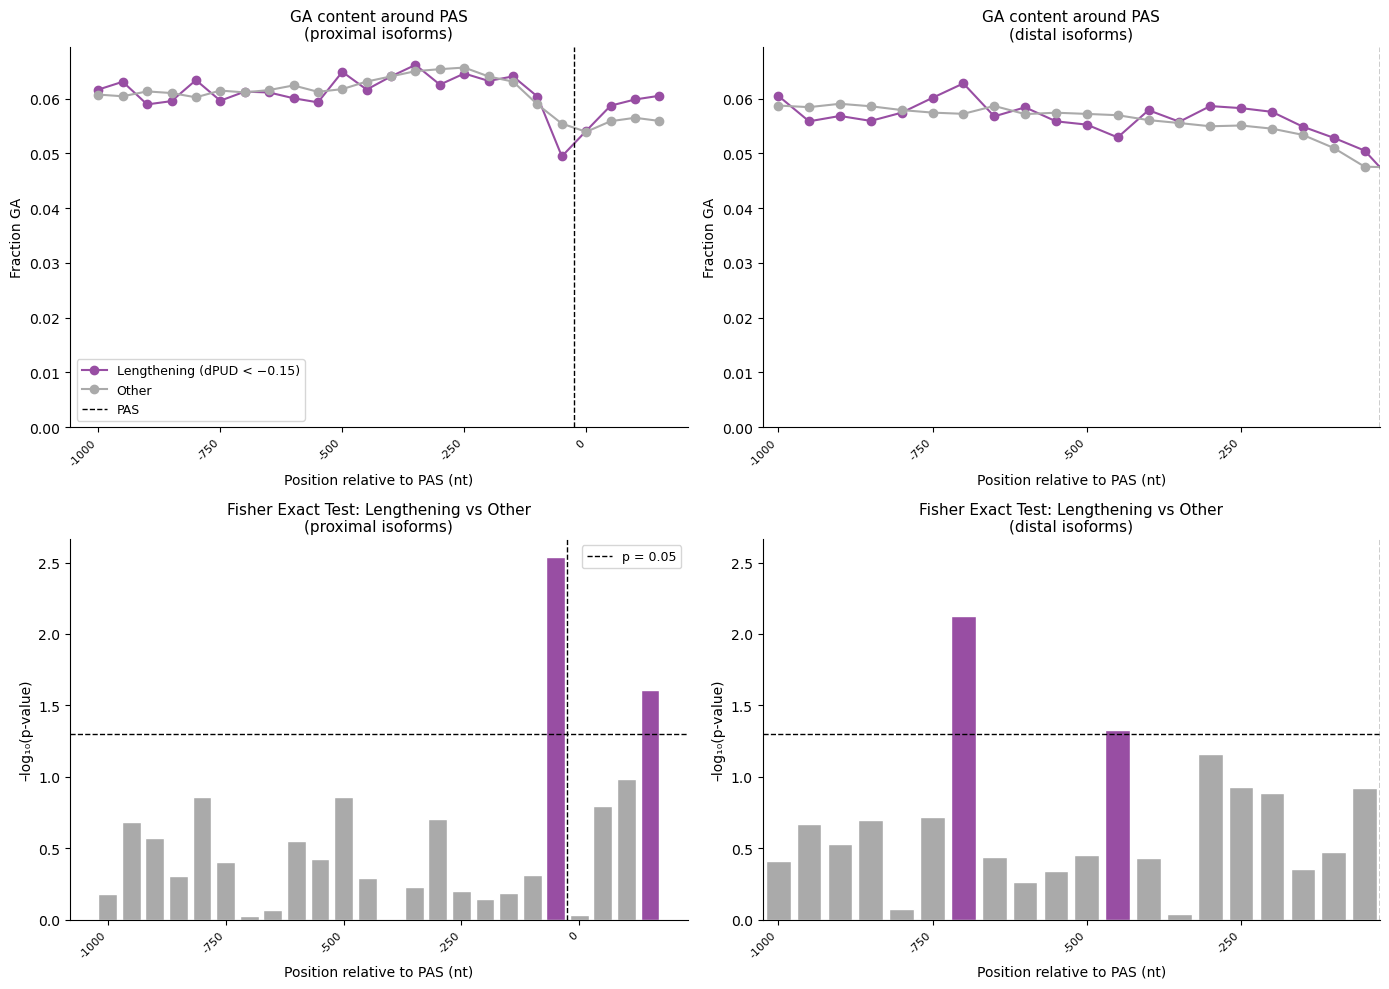

Computing AC-content profile for proximal isoforms...


Computing AC-content profile for distal isoforms...


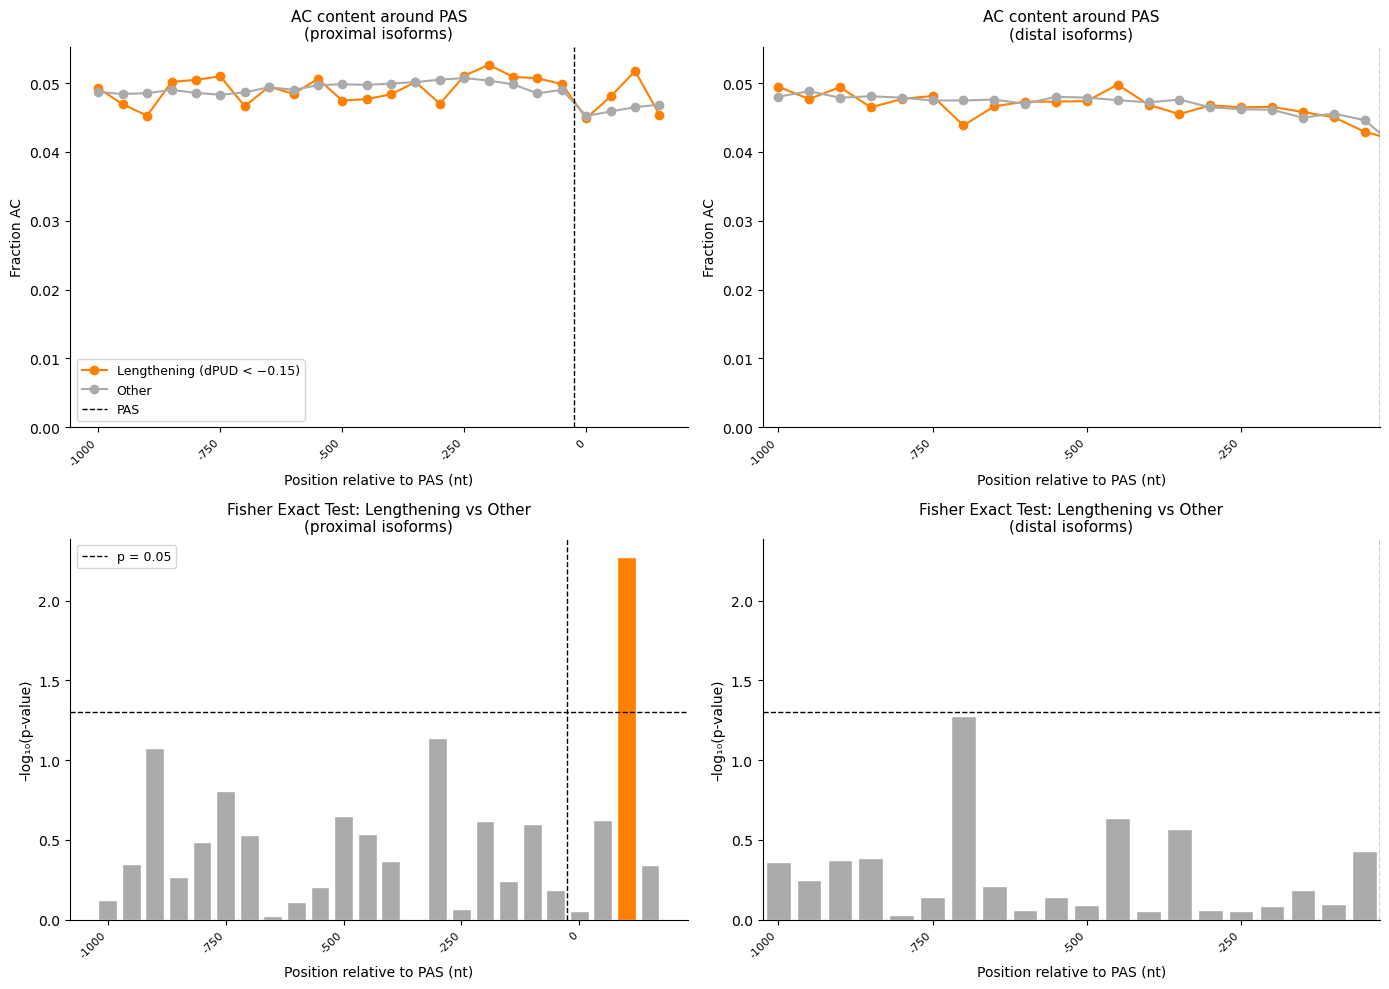

Computing CU-content profile for proximal isoforms...


Computing CU-content profile for distal isoforms...


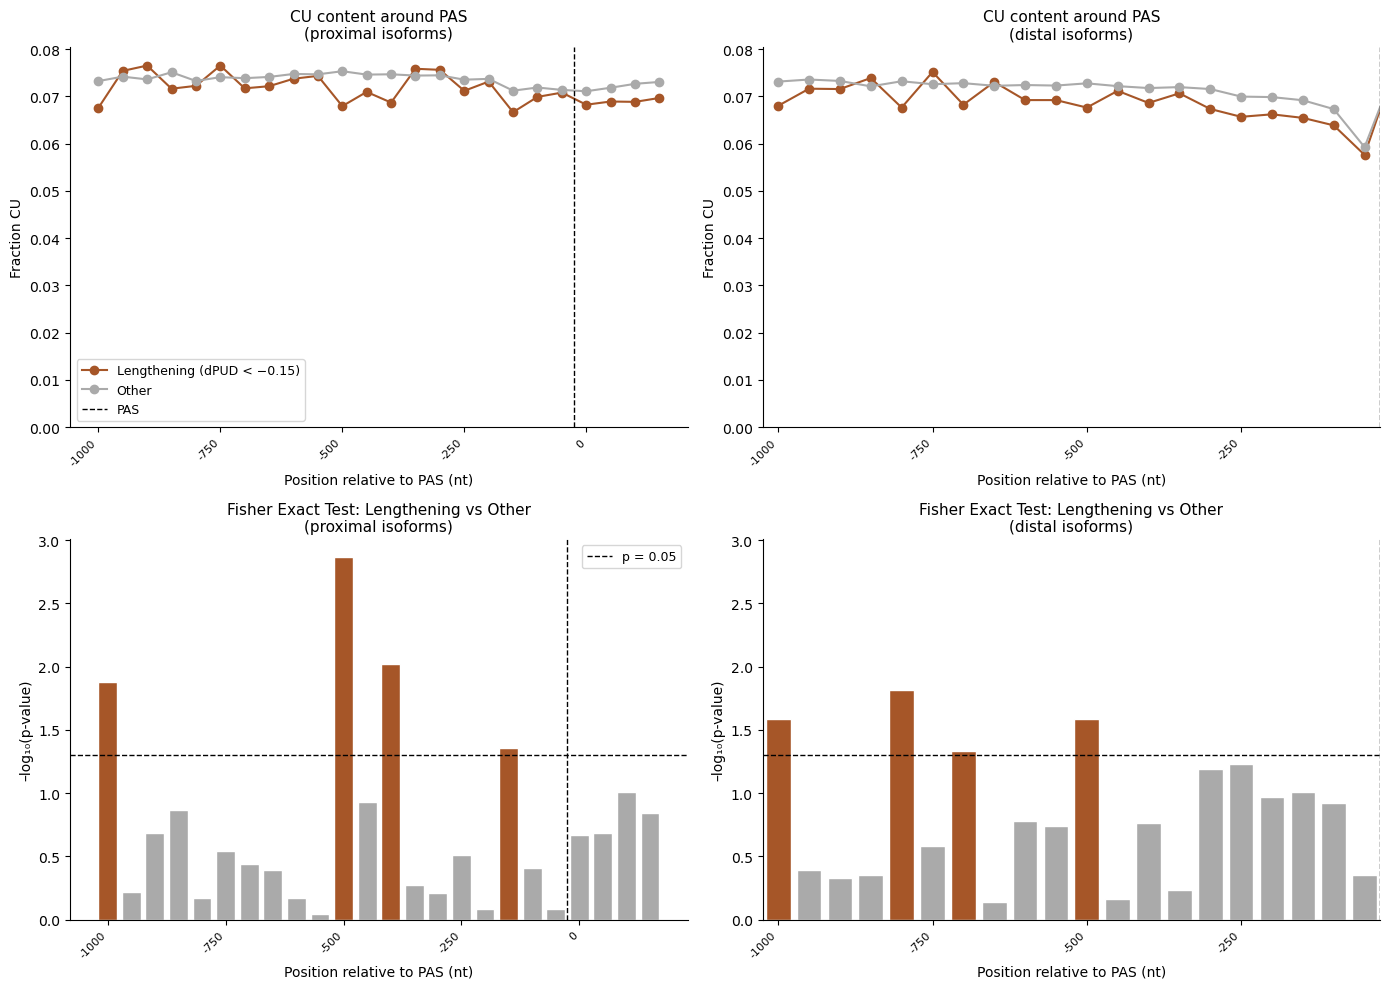

Computing AA-content profile for proximal isoforms...


Computing AA-content profile for distal isoforms...


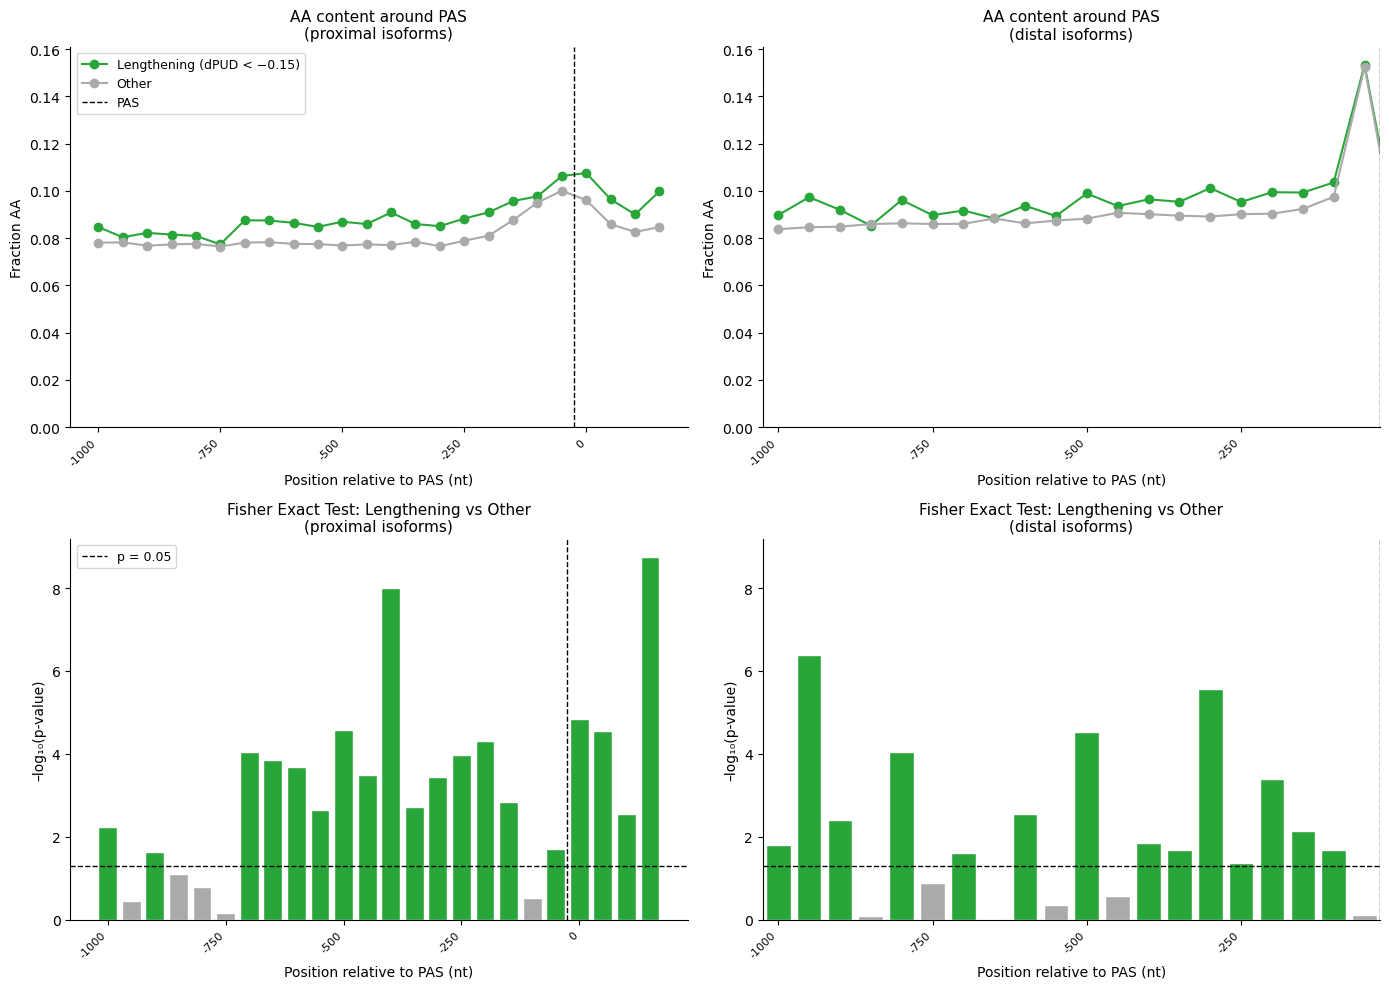

Computing UU-content profile for proximal isoforms...


Computing UU-content profile for distal isoforms...


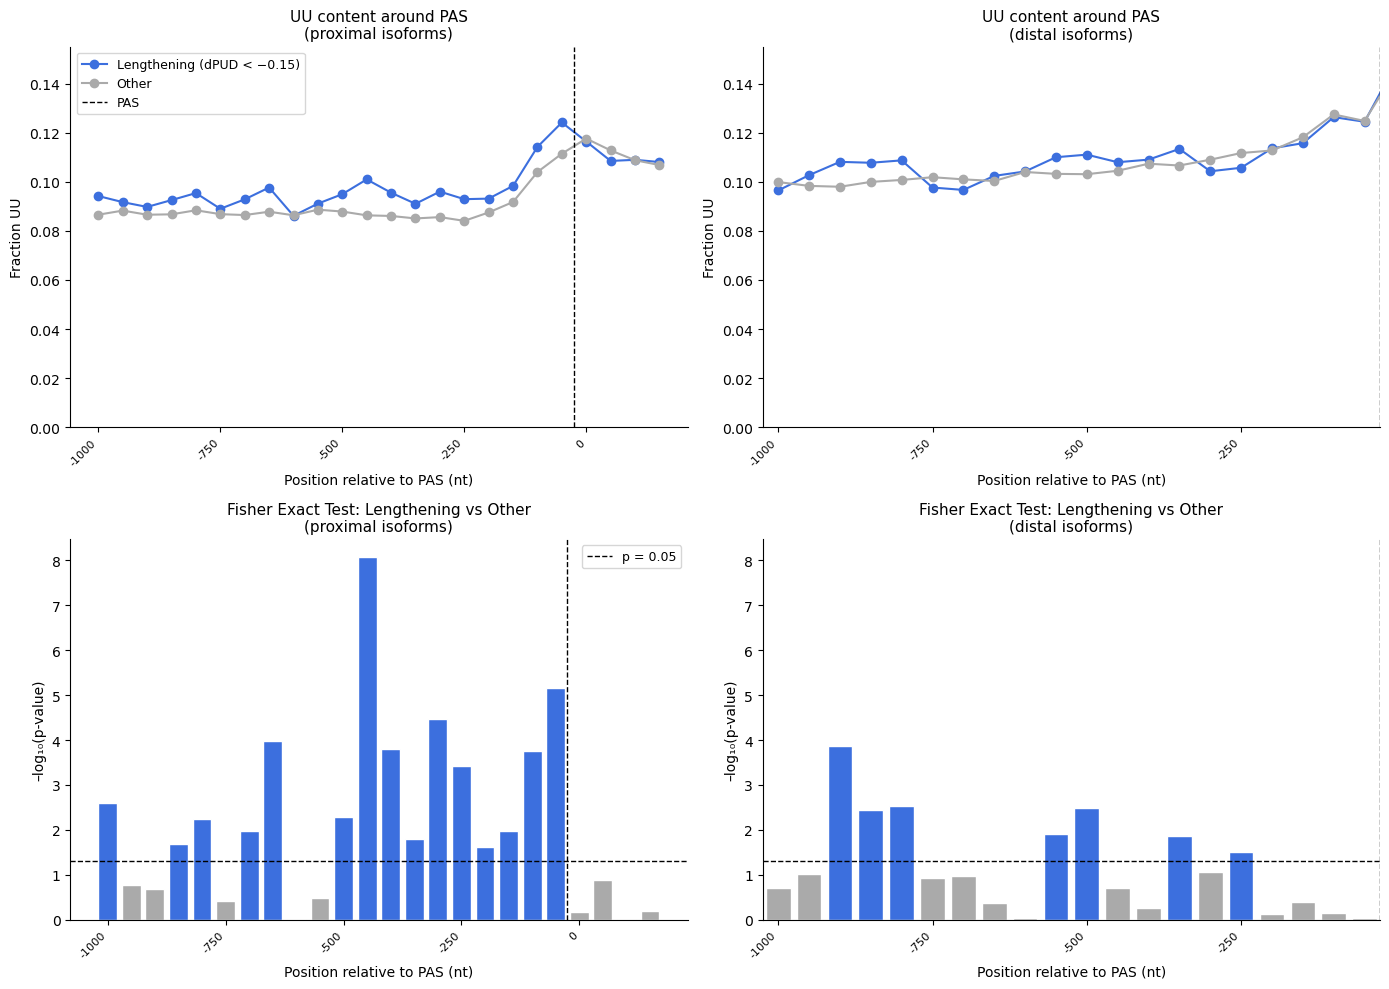

Computing CC-content profile for proximal isoforms...


Computing CC-content profile for distal isoforms...


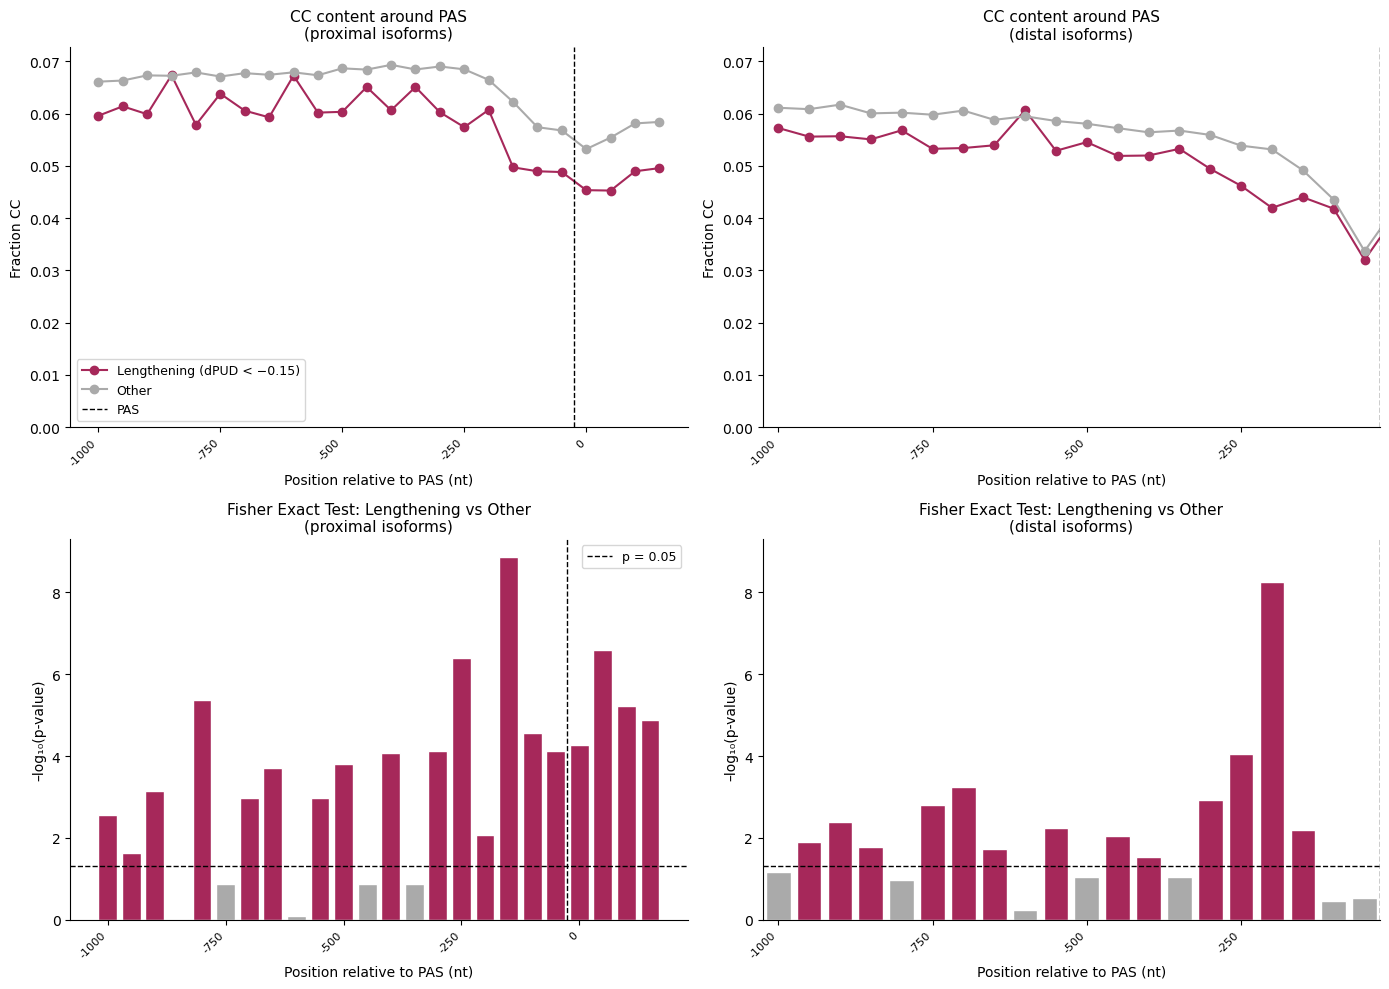

Computing GG-content profile for proximal isoforms...


Computing GG-content profile for distal isoforms...


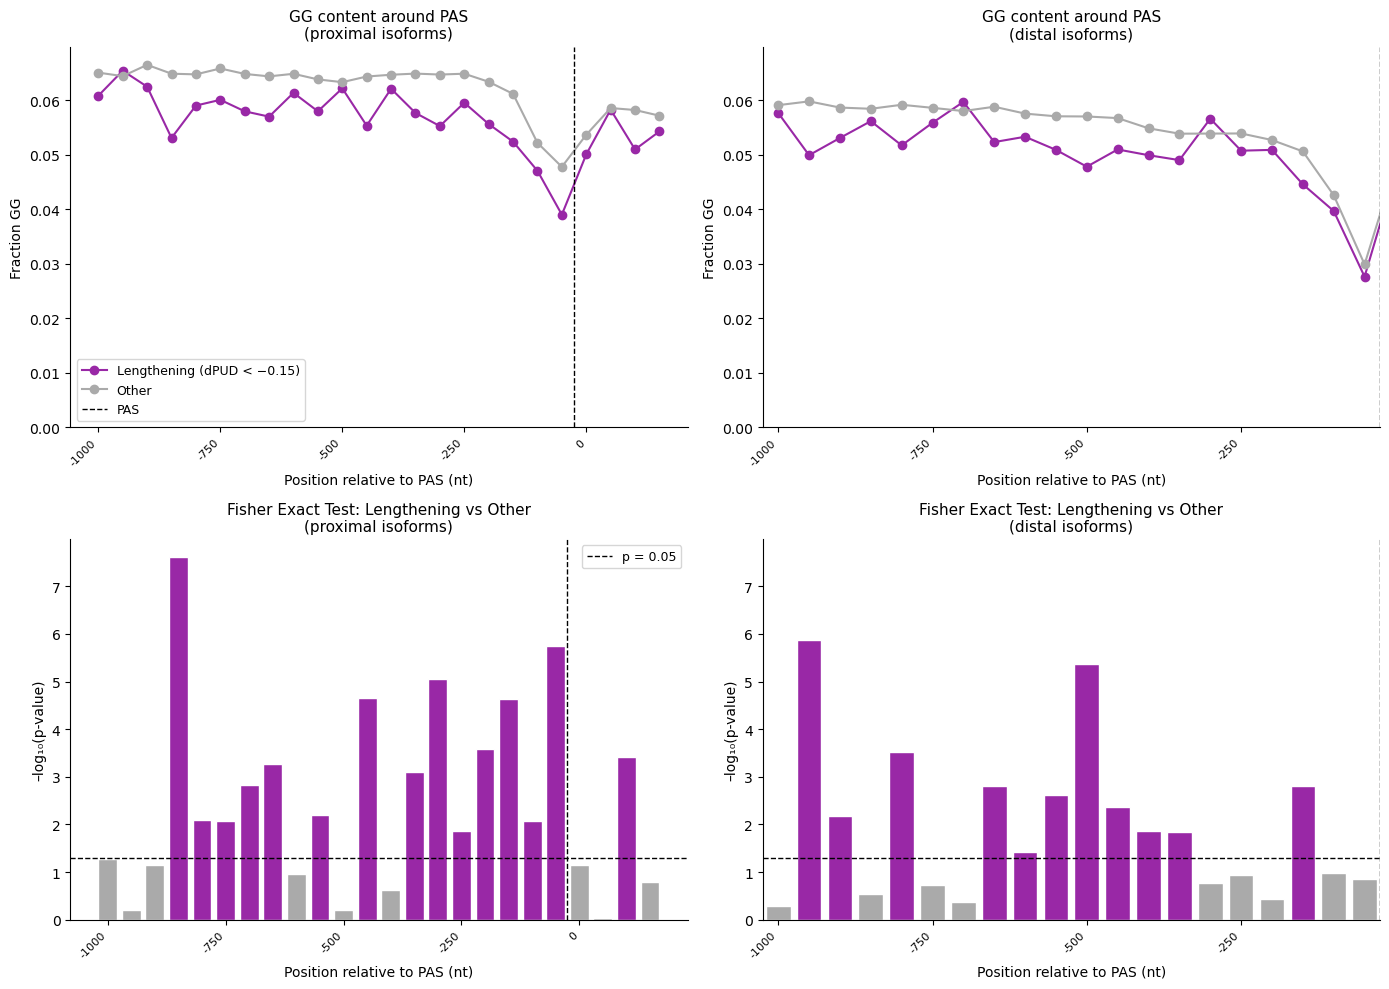

In [18]:
dimer_colors = {'AT': '#e41a1c', 'GC': '#377eb8', 'GT': '#4daf4a', 'GA': '#984ea3', 'AC': '#ff7f00', 'CT': '#a65628', 'AA': "#28a639",'TT': "#3c6fde", 'GG': "#9928a6", 'CC': "#a6285a"}

for dimer in DIMERS:
    fig, axes, pvalues_dimer = plot_dimer_window_profiles(dimer, WINDOW_SIZE=50, color=dimer_colors[dimer], y_min=0)
    save_figure(f"{figures_subfolder}/{DIMER_LABEL[dimer]}_content_around_PAS_cytoplasmic_lengthened_D22_to_D35_CTRL.pdf",
                pattern="<nucleotides>_content_around_PAS_cytoplasmic_lengthened_D22_to_D35_CTRL.pdf",
                legend="One file per nucleotide (A, C, G, U) and dinucleotide (AU, GC, GU, GA, AC, CU, AA, UU, CC, GG). Top: fraction of bases (or of overlapping dinucleotide positions) equal to it in each 50-nt window from -1000 to +200 nt around the PAS (hg38 sequence on the transcript strand, pooled over all transcripts), for 3'UTR pairs lengthened from D22 to D35 in the CTRL cytoplasm (pairs_distals_D22_Cytoplasmic_Wildtype_vs_D35_Cytoplasmic_Wildtype) (coloured) vs all other pairs (grey; longest distal isoform per proximal), proximal (left) and distal (right, shown up to the PAS) isoform. Bottom: -log10(p) of a two-sided Fisher's exact test per window (coloured = p < 0.05, uncorrected; dashed line = p 0.05). The plot legend labels the group 'Lengthening' in every comparison.")
    plt.show()


## Pairs longer in NUC vs CYTO at D35 (retained)

`pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Cytoplasmic_Wildtype.csv`: pairs shifting to the proximal PAS in the cytoplasm, i.e. longer in the nucleus (same group as in `Figure_m6A_loading.ipynb`). Same profiles. Saved: `<nucleotide>_content_around_PAS_longer_in_nucleus_D35_CTRL.pdf`.

In [19]:
fisher_sig_lengthening = pd.read_csv(f"{path_to_shift}/pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Cytoplasmic_Wildtype.csv")
fisher_sig_lengthening = fisher_sig_lengthening[fisher_sig_lengthening['distal_id'].isin(table_of_pairs_longest['distal_id'])]
fisher_other = table_of_pairs_longest[~table_of_pairs_longest['distal_id'].isin(fisher_sig_lengthening['distal_id'])][["proximal_id", "distal_id"]]

full_window_seqs = {}
for iso_type in ['proximal', 'distal']:
    col_name = f"{iso_type}_id"
    full_window_seqs[(iso_type, 'Lengthening')] = get_window_sequences(fisher_sig_lengthening, col_name, pas_lookup, hg38_fasta, WL_FULL, WR_FULL)
    full_window_seqs[(iso_type, 'Other')] = get_window_sequences(fisher_other, col_name, pas_lookup, hg38_fasta, WL_FULL, WR_FULL)
    print(f"{iso_type}: Lengthening n={len(full_window_seqs[(iso_type, 'Lengthening')])}, "
          f"Other n={len(full_window_seqs[(iso_type, 'Other')])}")


proximal: Lengthening n=3899, Other n=3978
distal: Lengthening n=3899, Other n=3978


Computing A-content profile for proximal isoforms...


Computing A-content profile for distal isoforms...


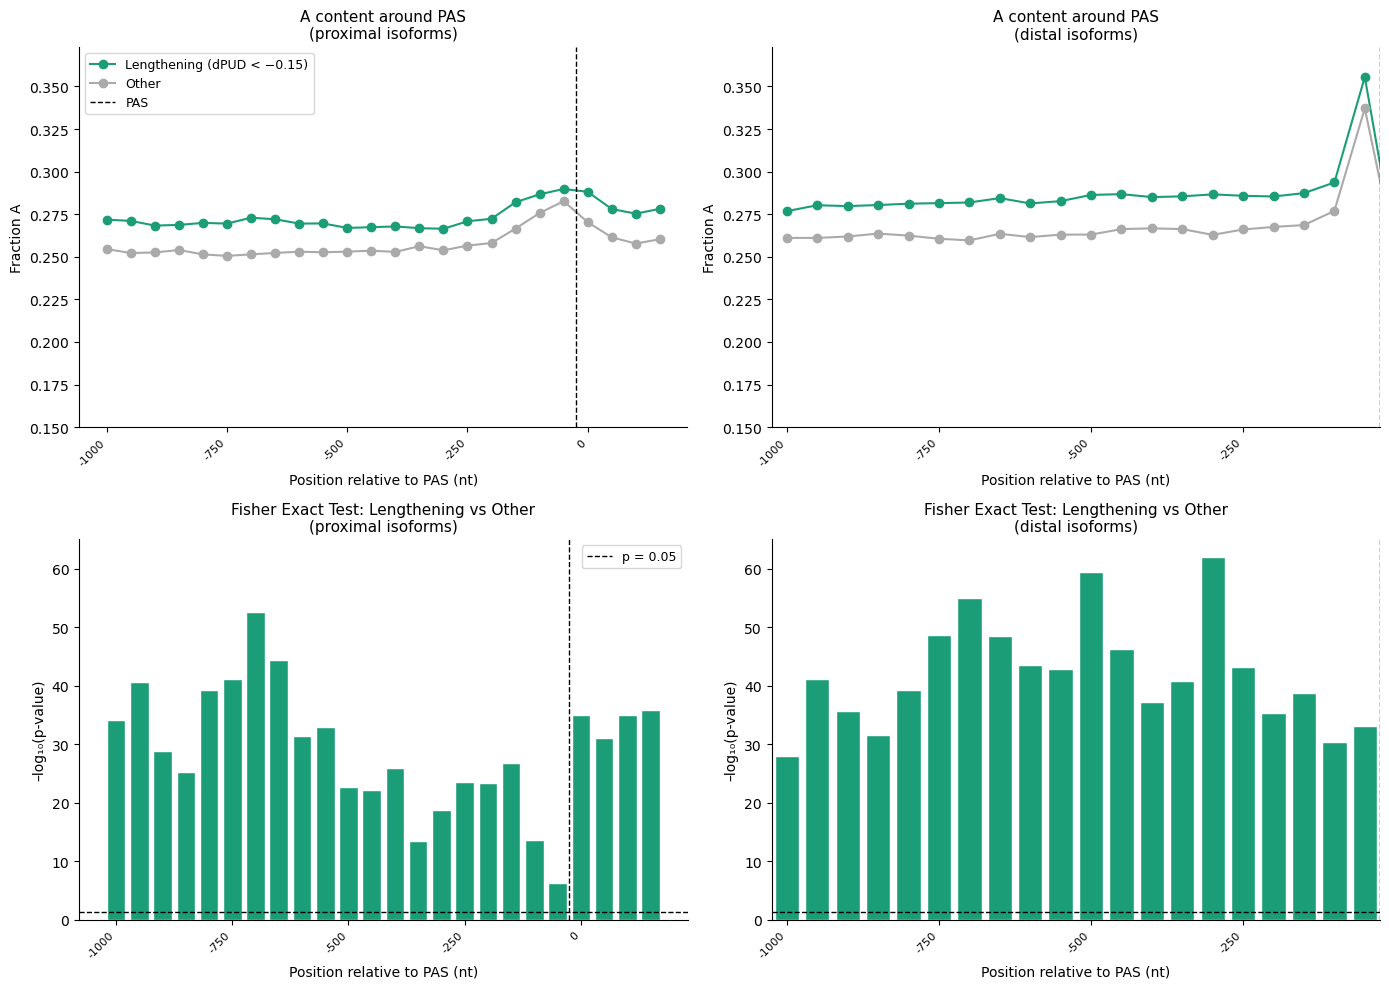

Computing C-content profile for proximal isoforms...


Computing C-content profile for distal isoforms...


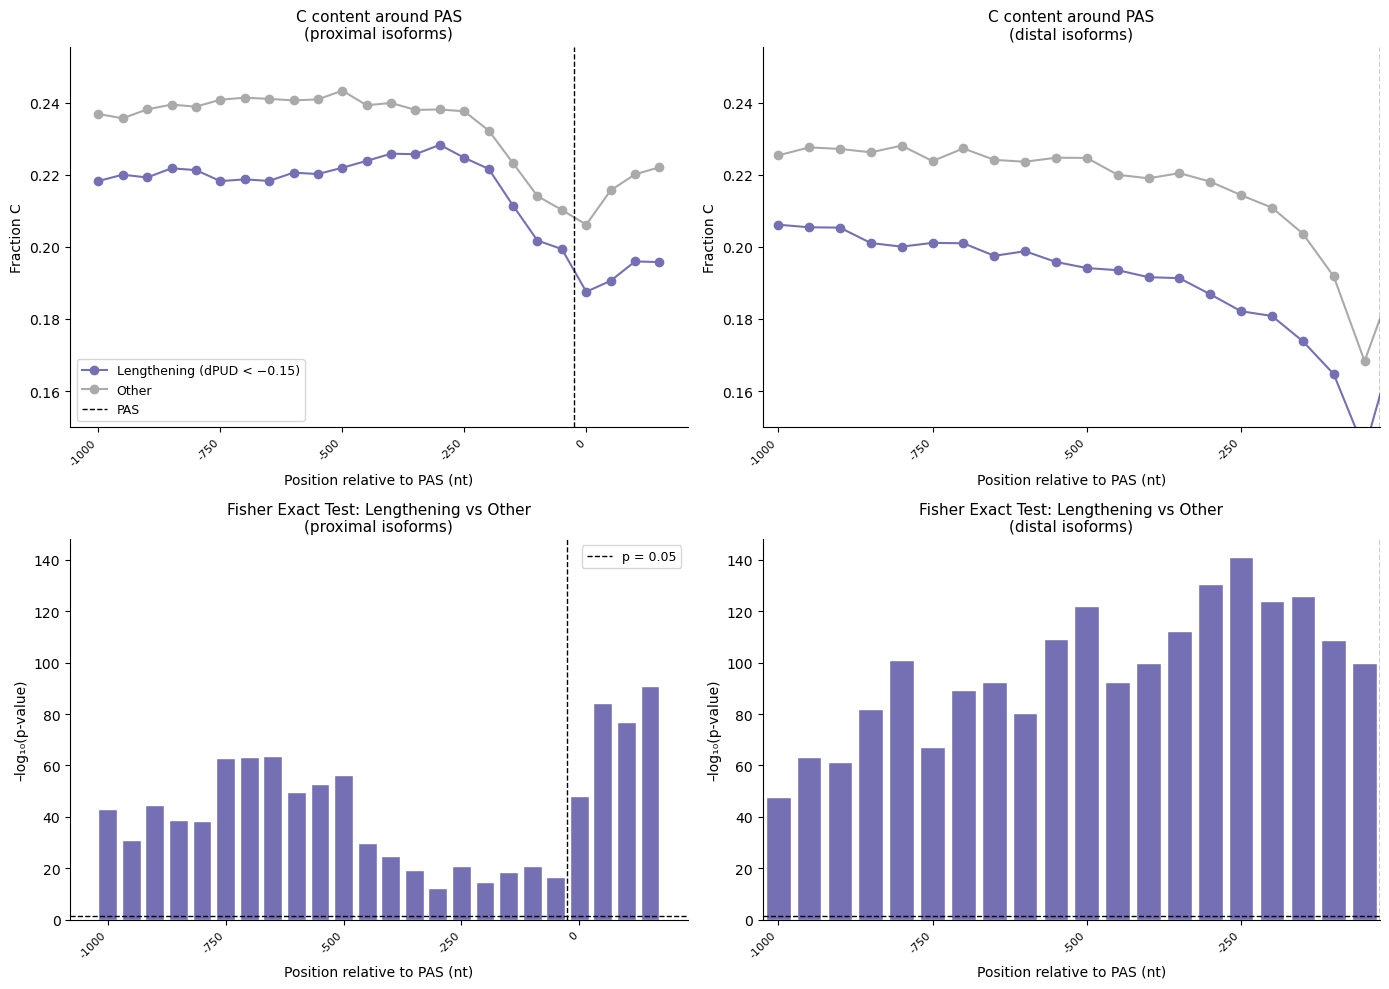

Computing G-content profile for proximal isoforms...


Computing G-content profile for distal isoforms...


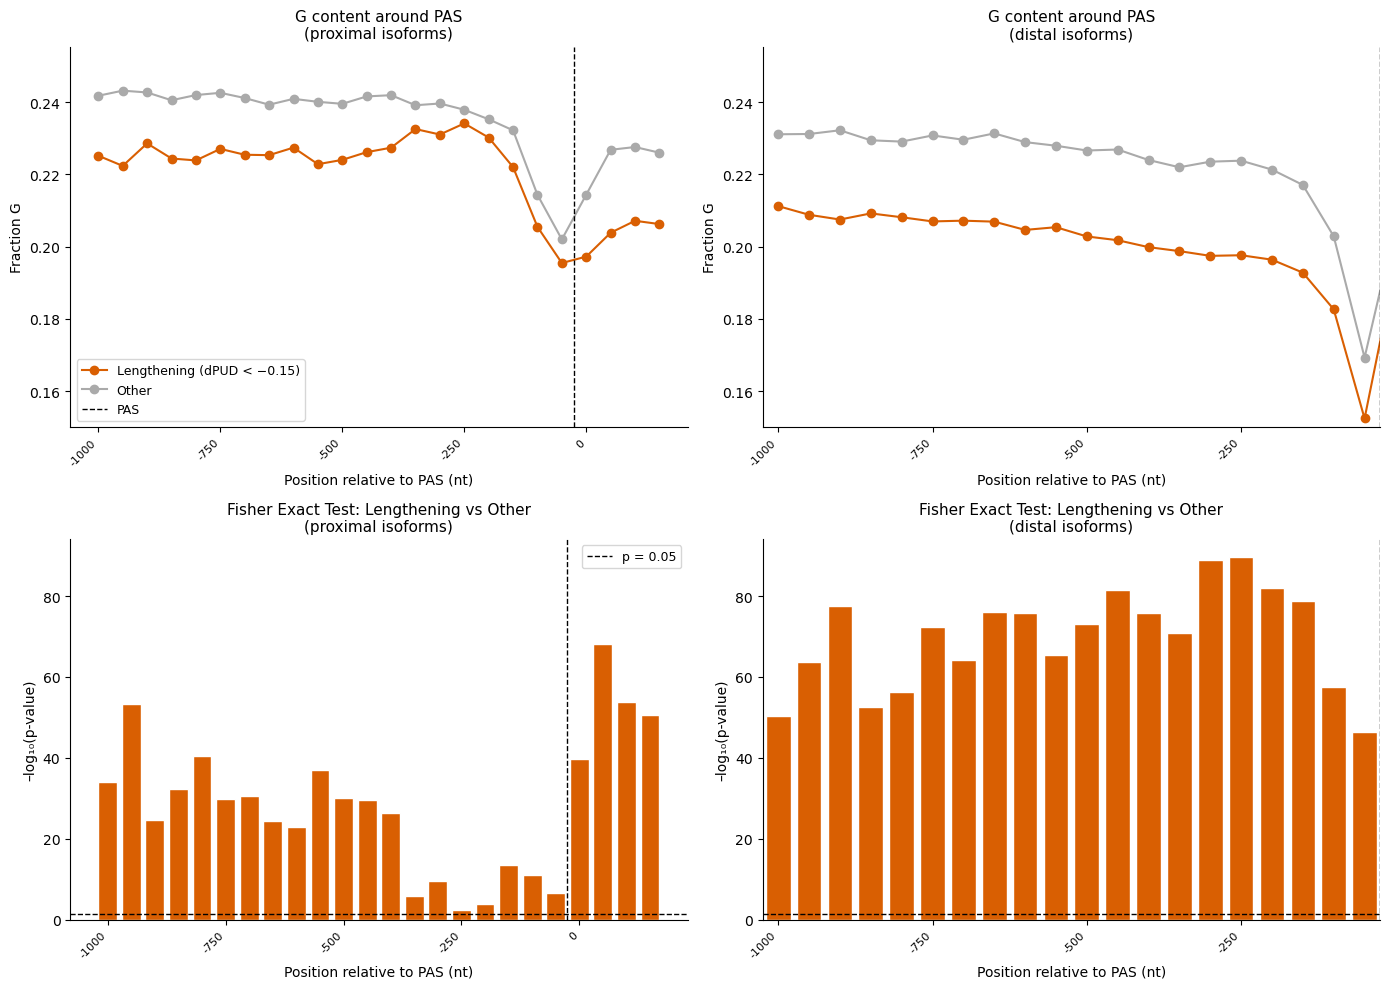

Computing U-content profile for proximal isoforms...


Computing U-content profile for distal isoforms...


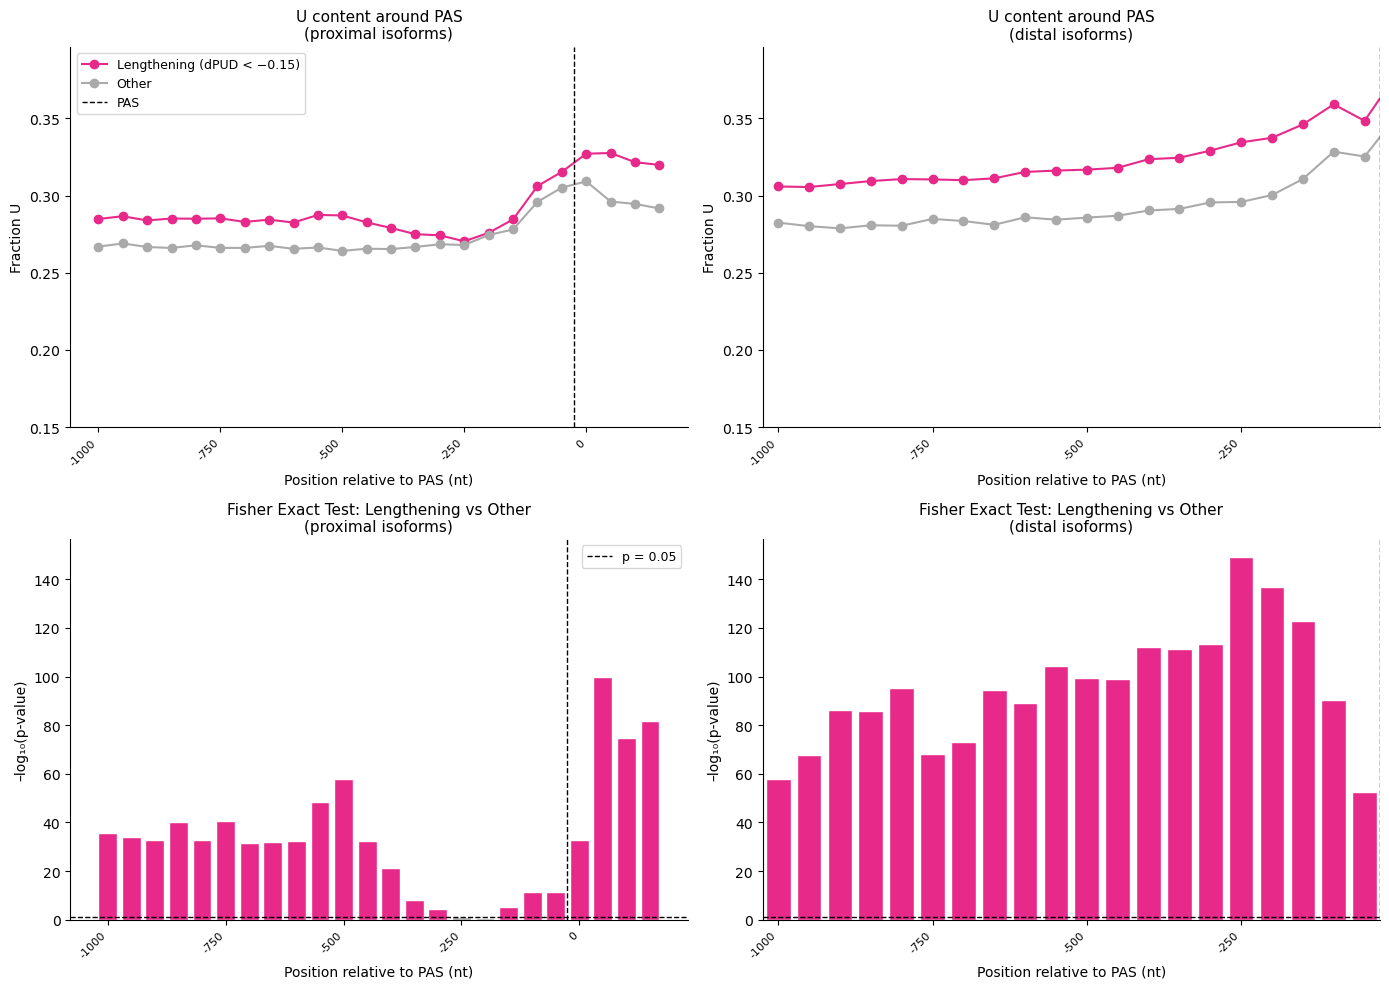

In [20]:
nt_colors = {'A': '#1b9e77', 'C': '#7570b3', 'G': '#d95f02', 'T': '#e7298a'}

for nt in NUCLEOTIDES:
    fig, axes, pvalues_nt = plot_nucleotide_window_profiles(nt, WINDOW_SIZE=50, color=nt_colors[nt], y_min=0.15)
    save_figure(f"{figures_subfolder}/{NT_LABEL[nt]}_content_around_PAS_longer_in_nucleus_D35_CTRL.pdf",
                pattern="<nucleotides>_content_around_PAS_longer_in_nucleus_D35_CTRL.pdf",
                legend="One file per nucleotide (A, C, G, U) and dinucleotide (AU, GC, GU, GA, AC, CU, AA, UU, CC, GG). Top: fraction of bases (or of overlapping dinucleotide positions) equal to it in each 50-nt window from -1000 to +200 nt around the PAS (hg38 sequence on the transcript strand, pooled over all transcripts), for 3'UTR pairs longer in the nucleus than in the cytoplasm at D35 in CTRL (proximal shift in the cytoplasm; pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Cytoplasmic_Wildtype) (coloured) vs all other pairs (grey; longest distal isoform per proximal), proximal (left) and distal (right, shown up to the PAS) isoform. Bottom: -log10(p) of a two-sided Fisher's exact test per window (coloured = p < 0.05, uncorrected; dashed line = p 0.05). The plot legend labels the group 'Lengthening' in every comparison.")
    plt.show()

Computing AU-content profile for proximal isoforms...


Computing AU-content profile for distal isoforms...


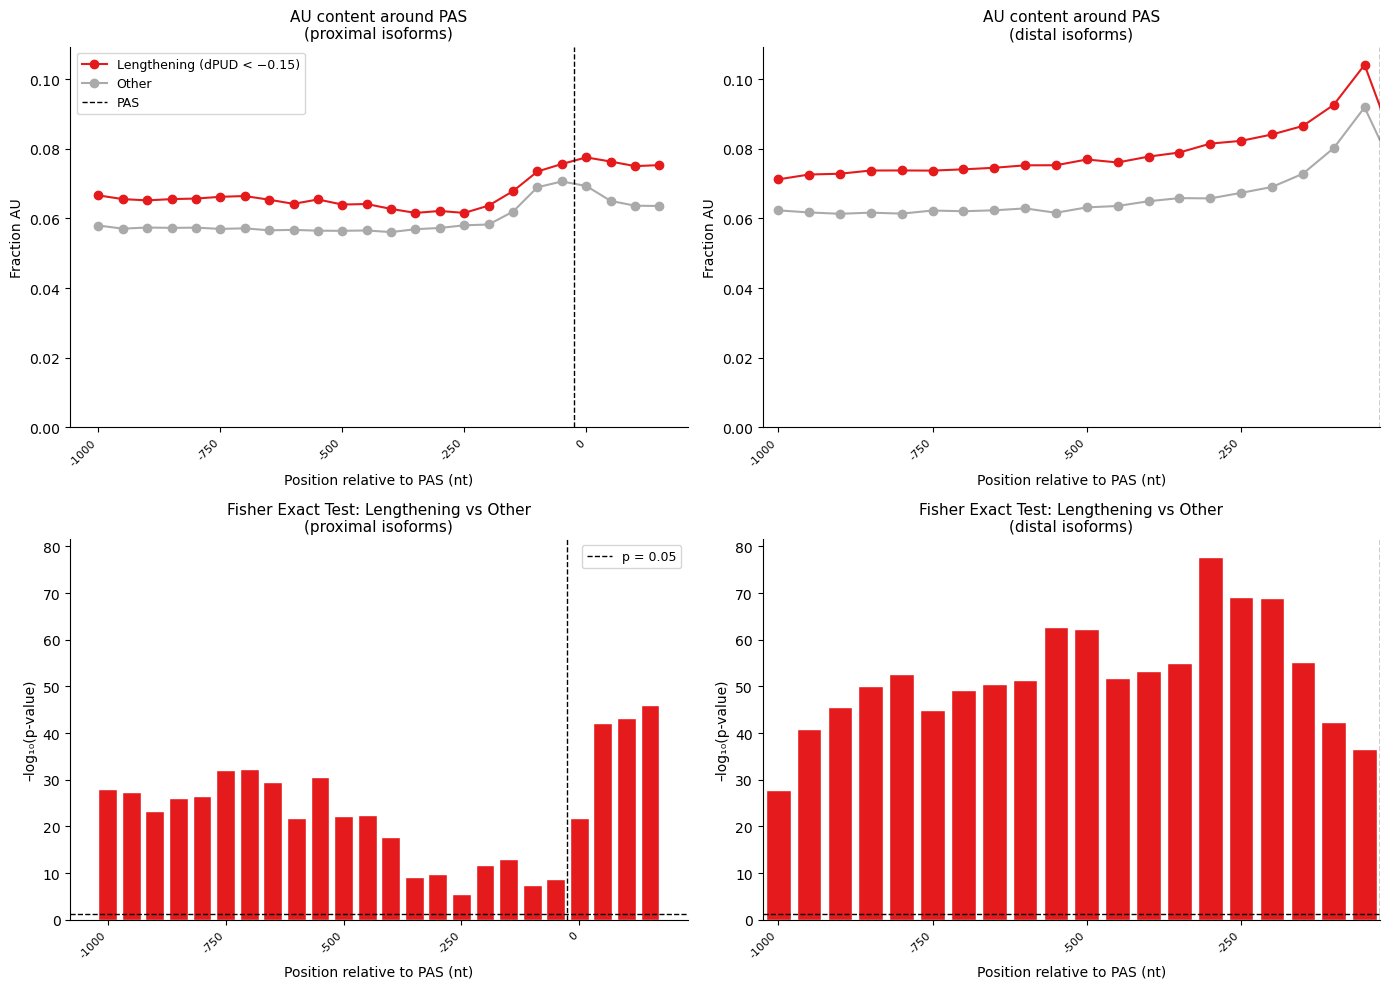

Computing GC-content profile for proximal isoforms...


Computing GC-content profile for distal isoforms...


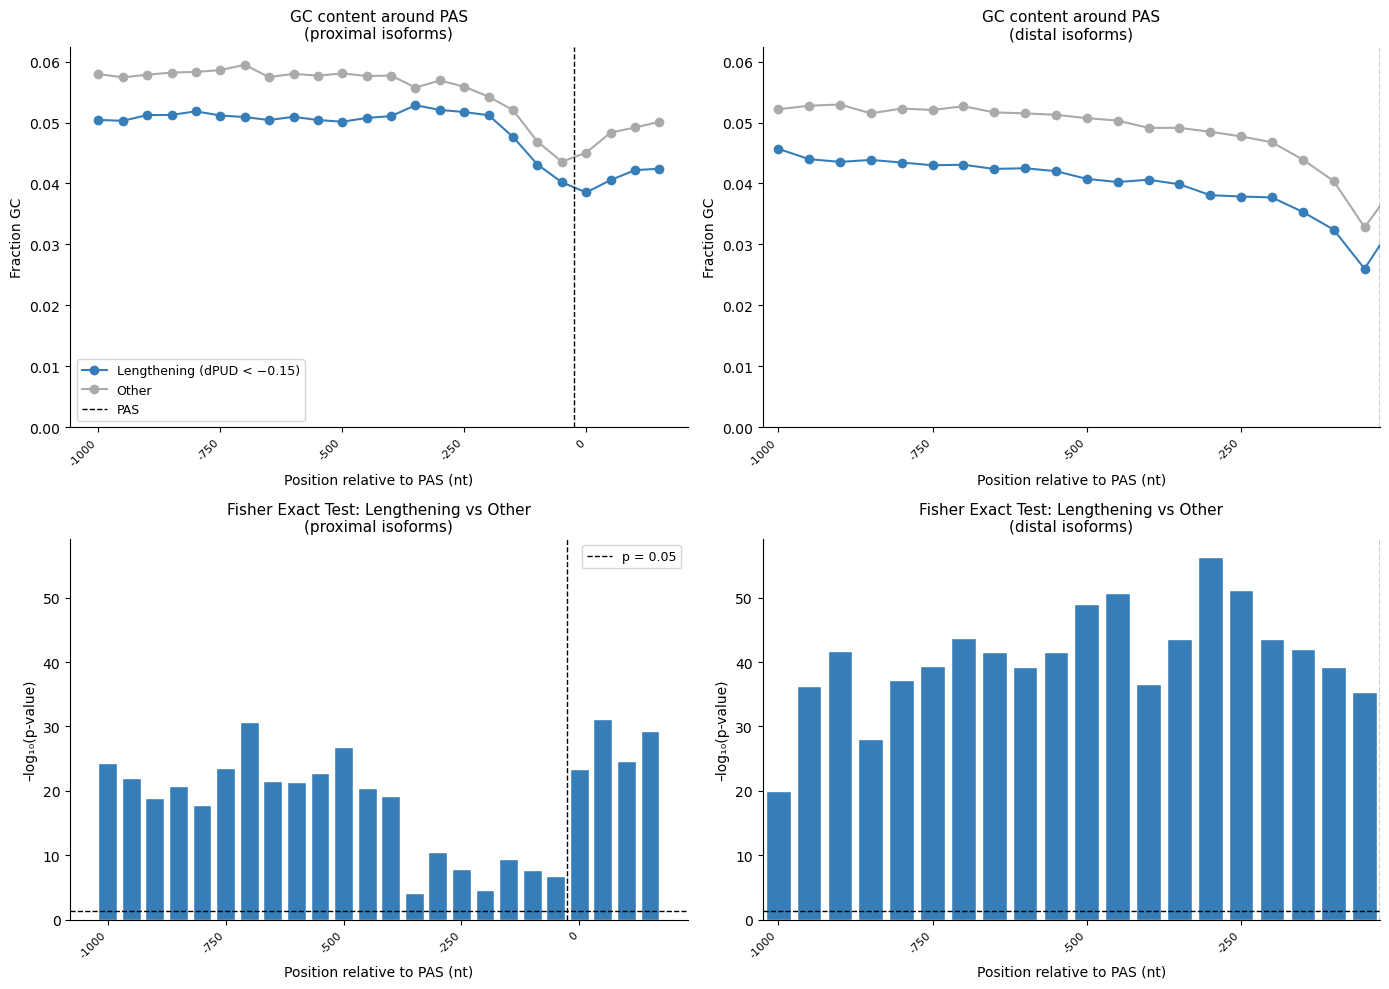

Computing GU-content profile for proximal isoforms...


Computing GU-content profile for distal isoforms...


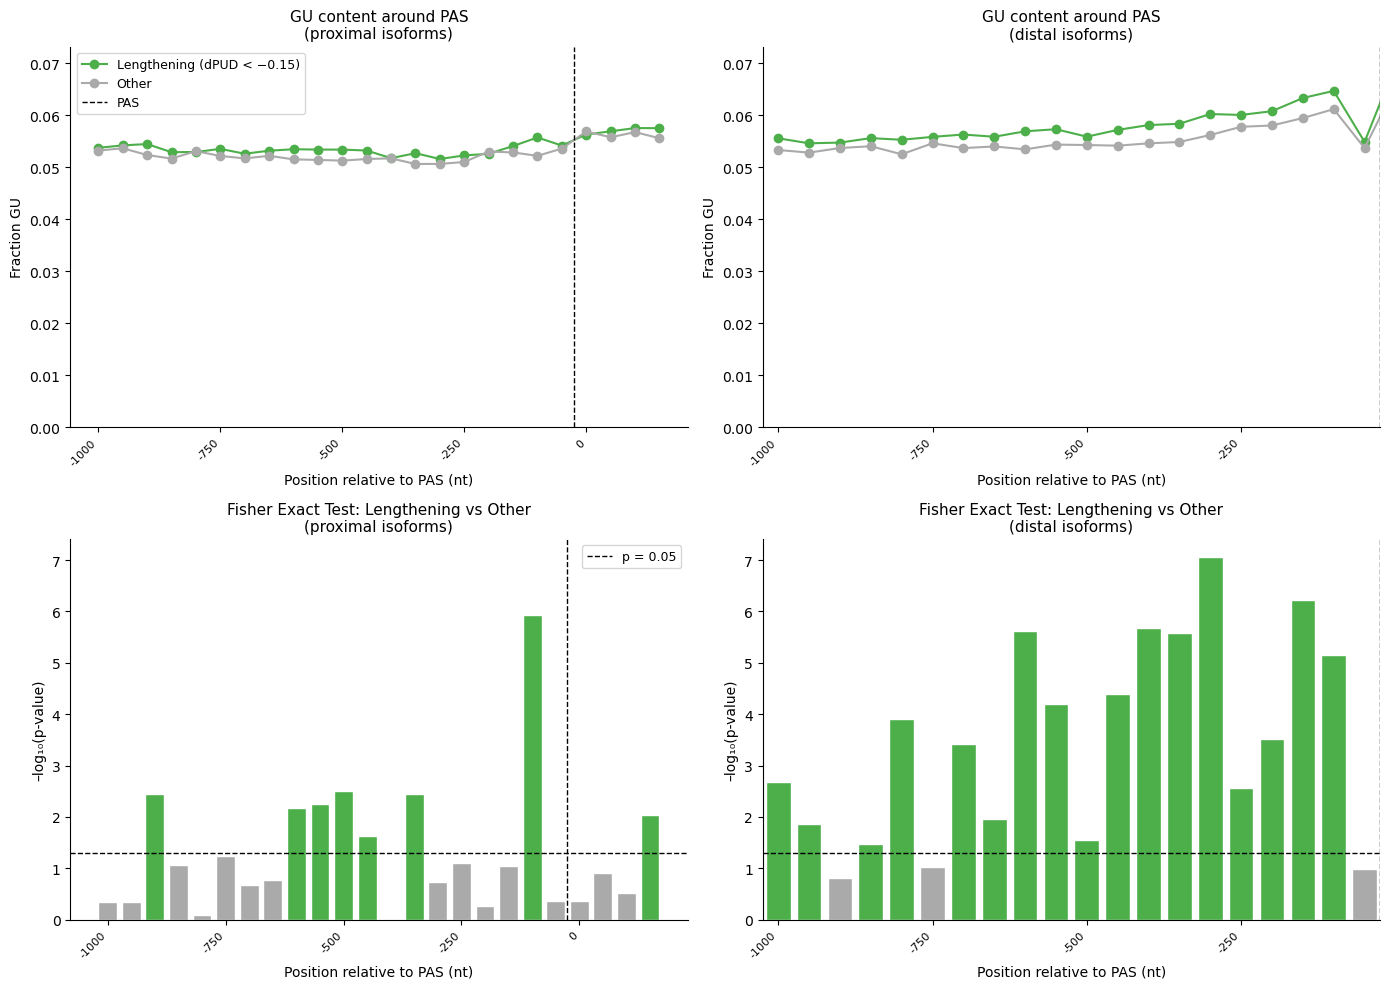

Computing GA-content profile for proximal isoforms...


Computing GA-content profile for distal isoforms...


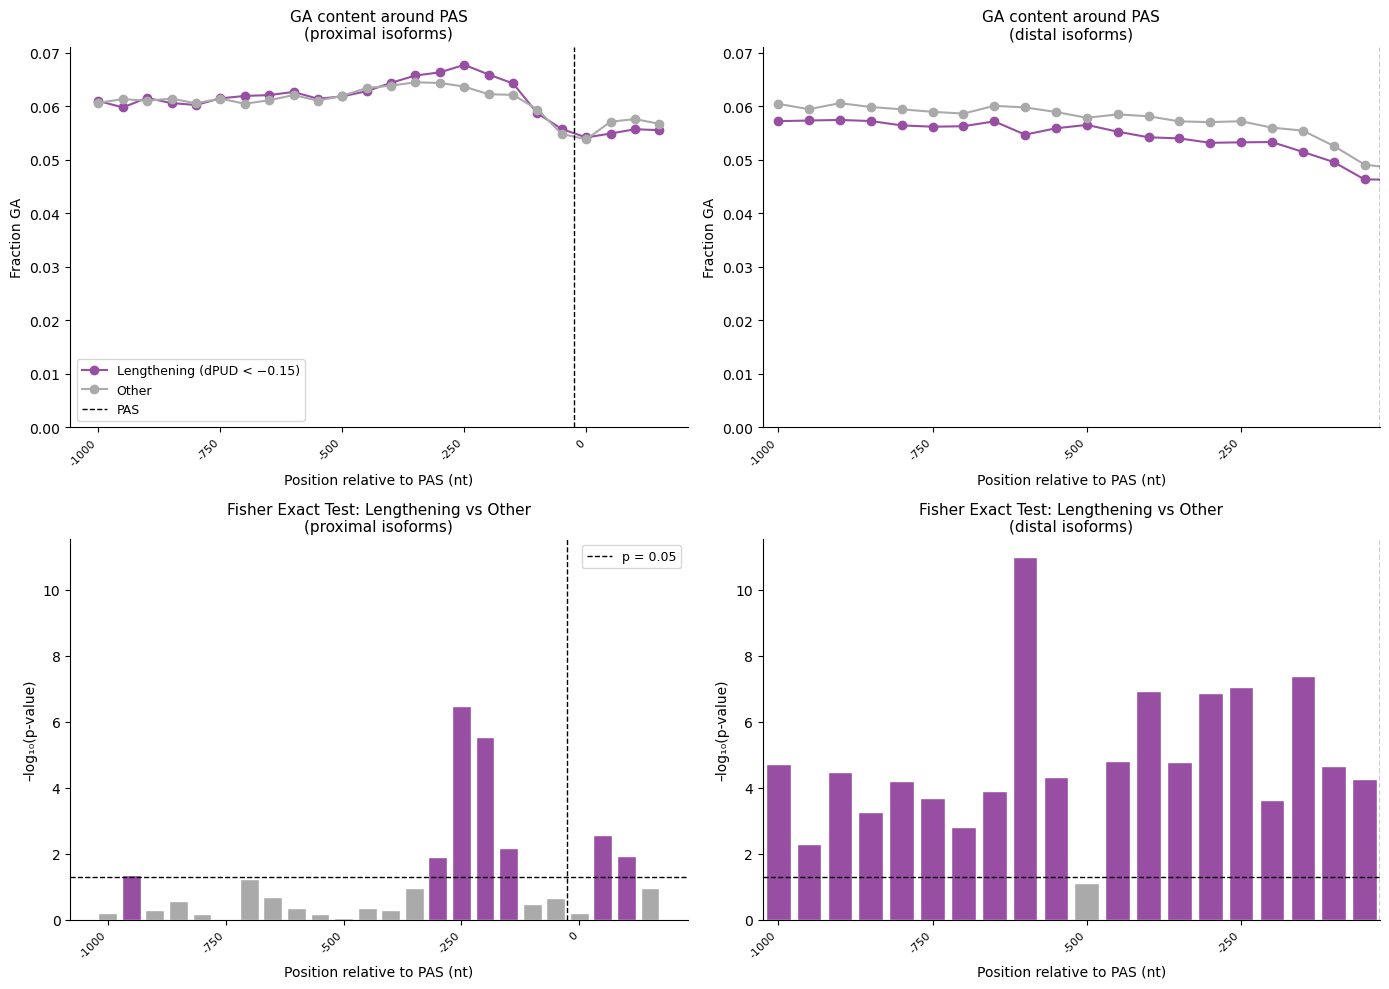

Computing AC-content profile for proximal isoforms...


Computing AC-content profile for distal isoforms...


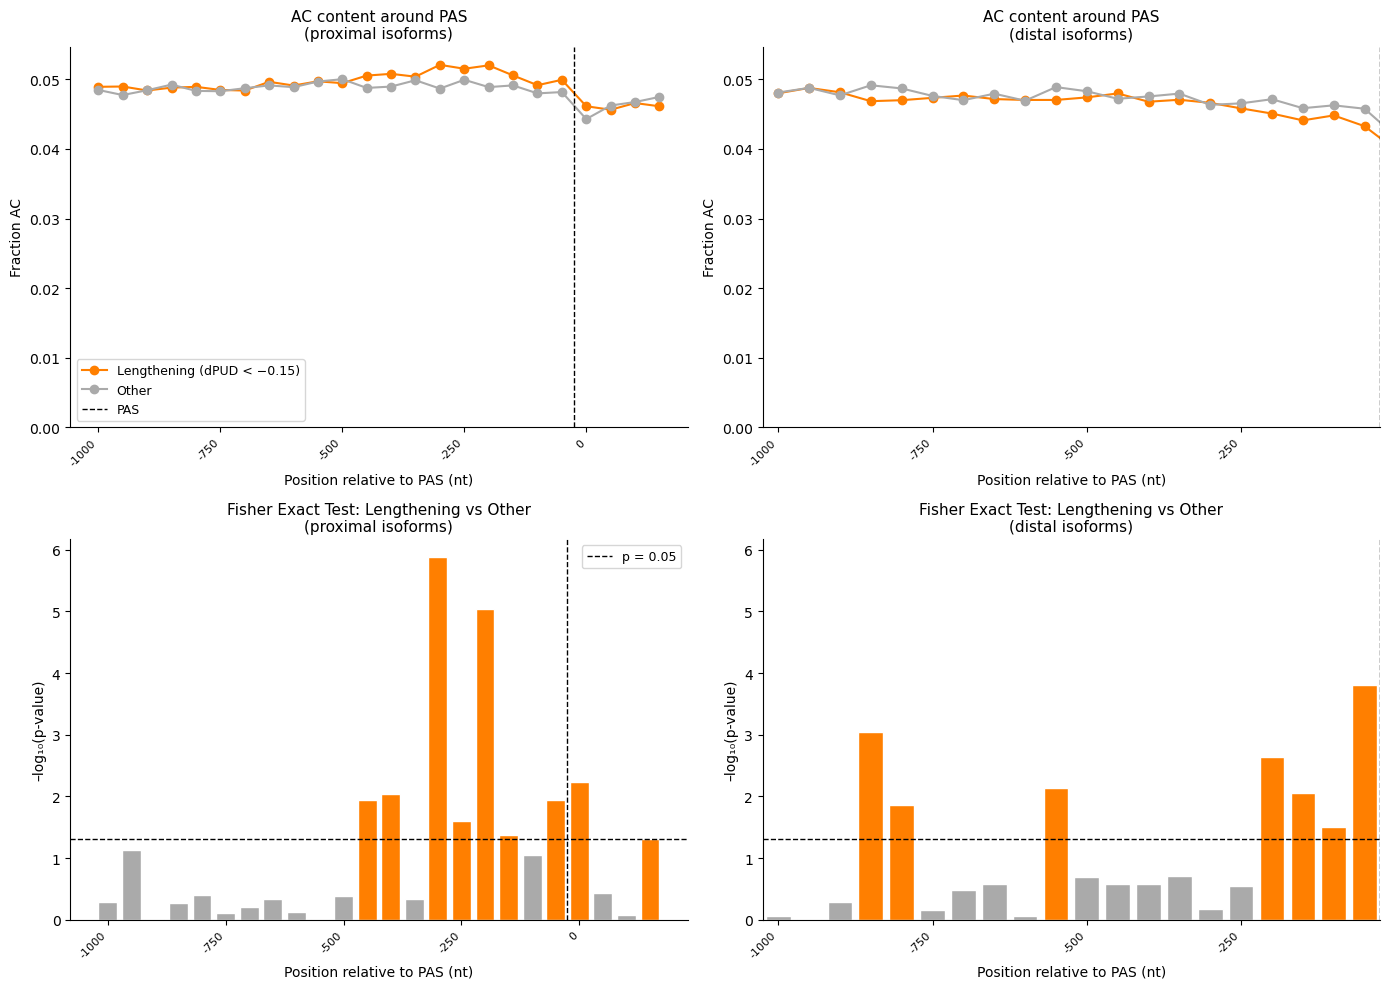

Computing CU-content profile for proximal isoforms...


Computing CU-content profile for distal isoforms...


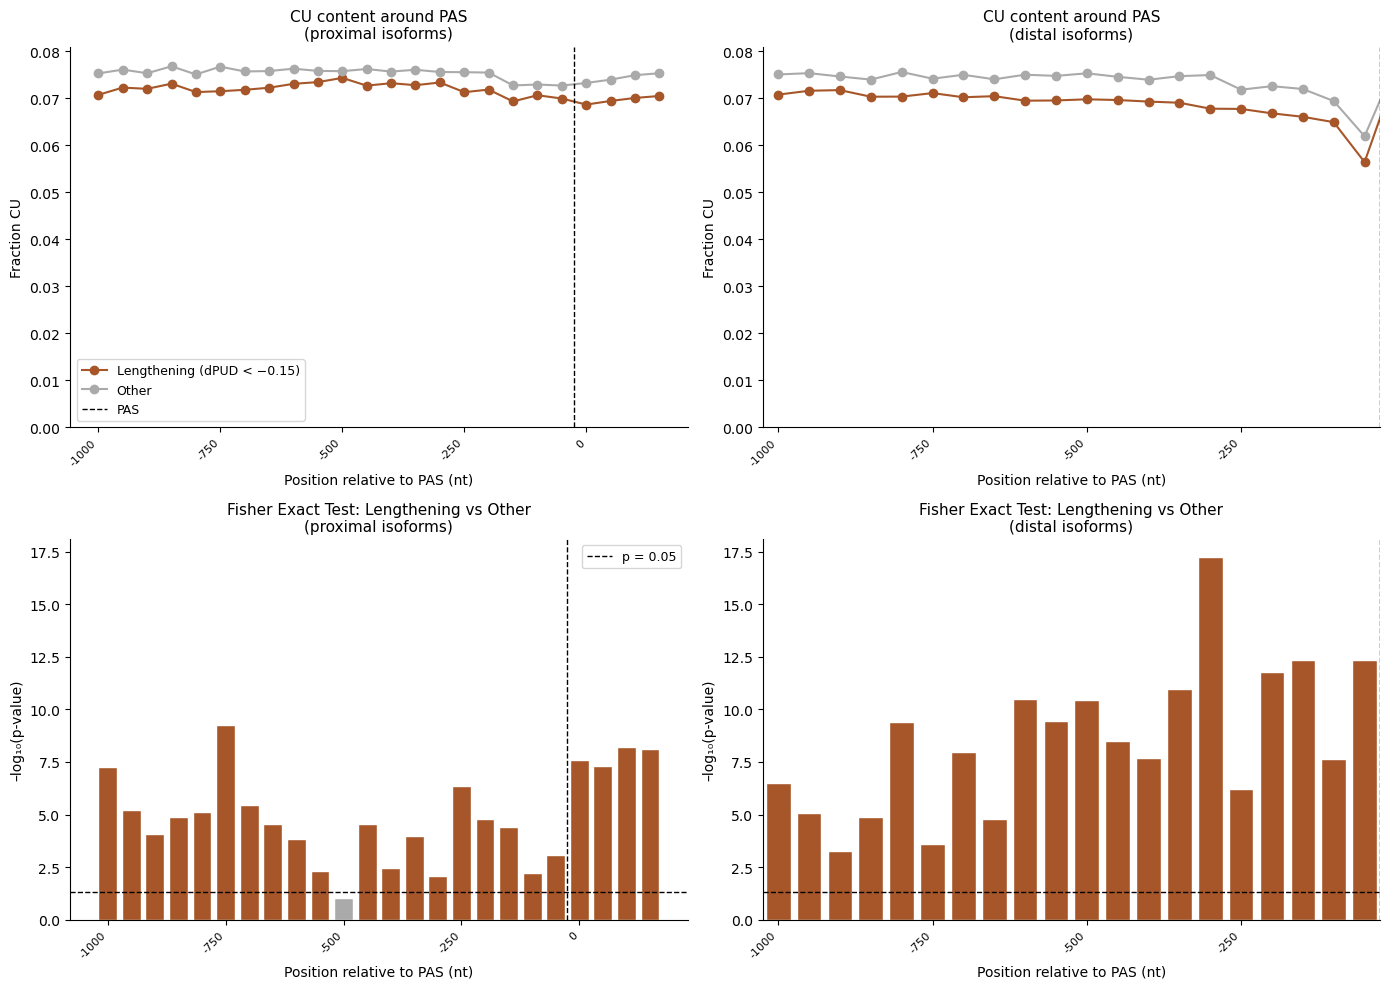

Computing AA-content profile for proximal isoforms...


Computing AA-content profile for distal isoforms...


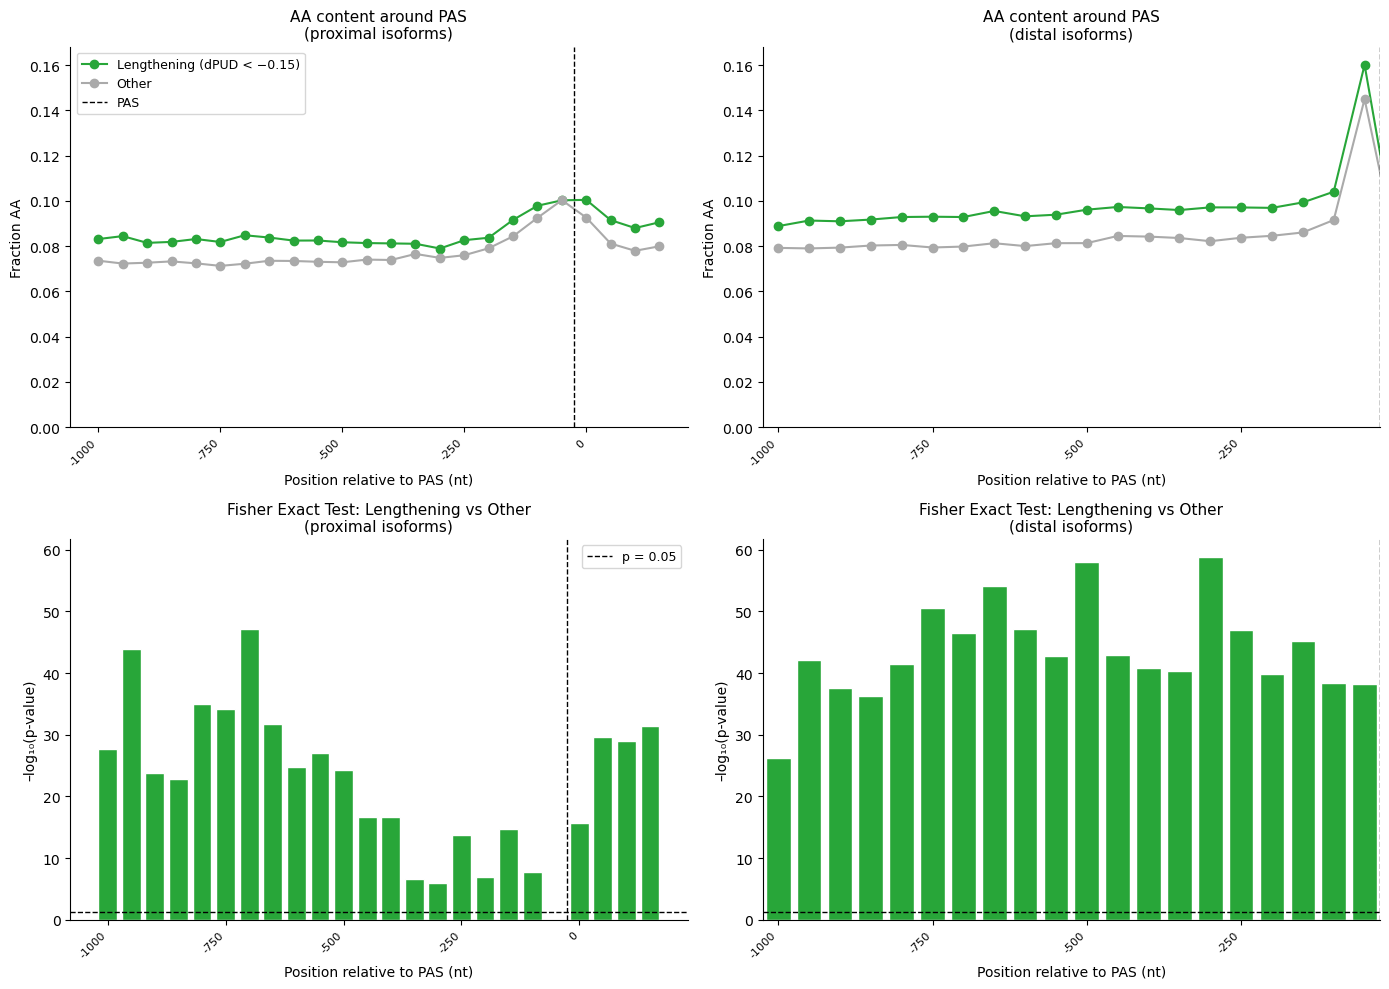

Computing UU-content profile for proximal isoforms...


Computing UU-content profile for distal isoforms...


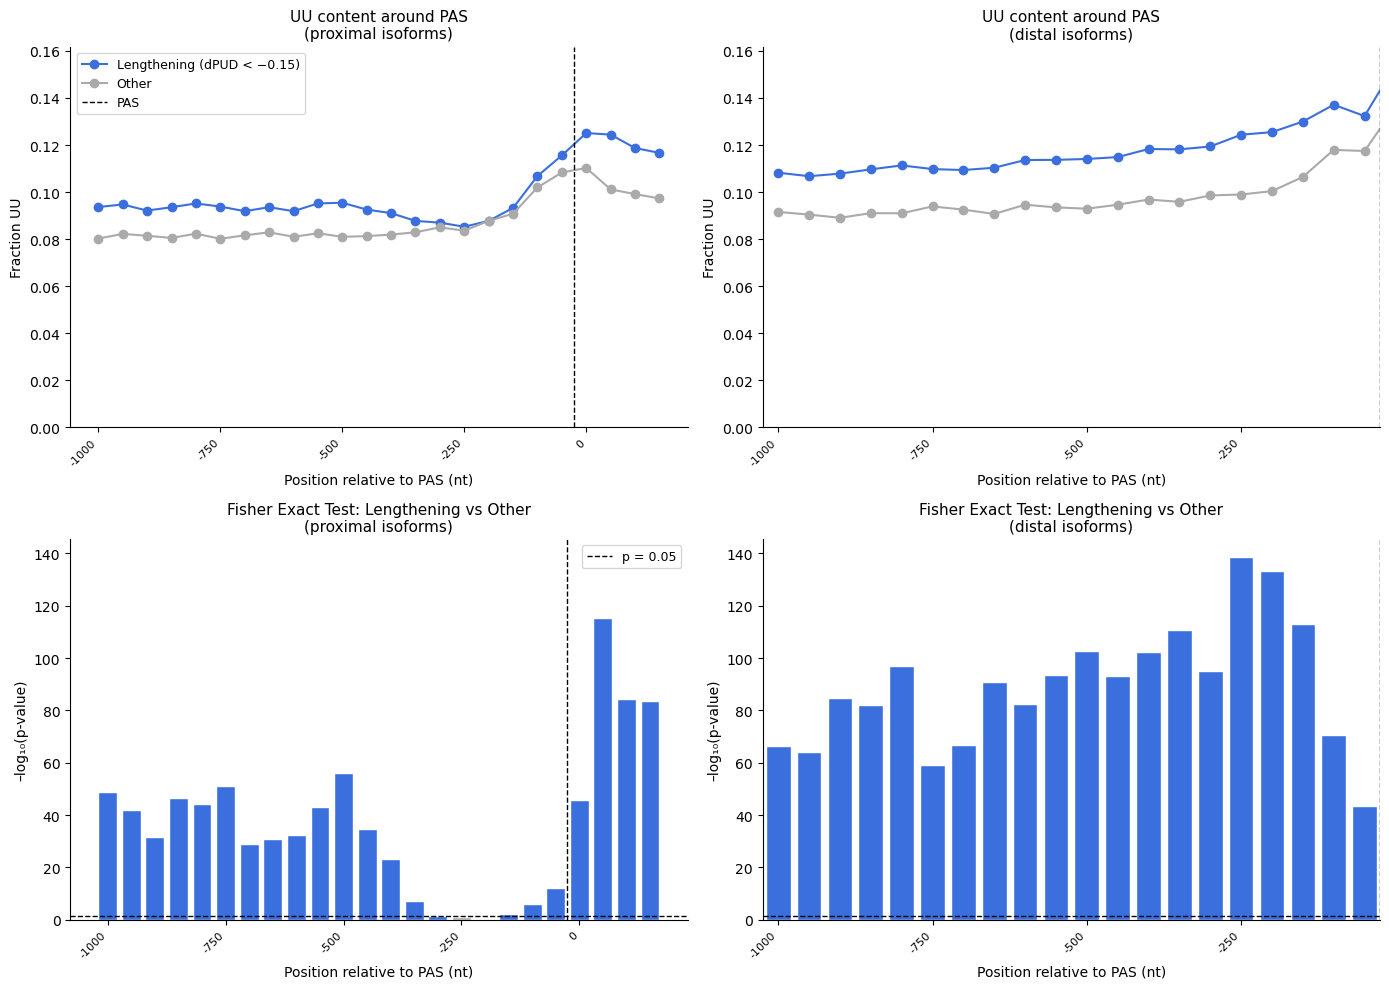

Computing CC-content profile for proximal isoforms...


Computing CC-content profile for distal isoforms...


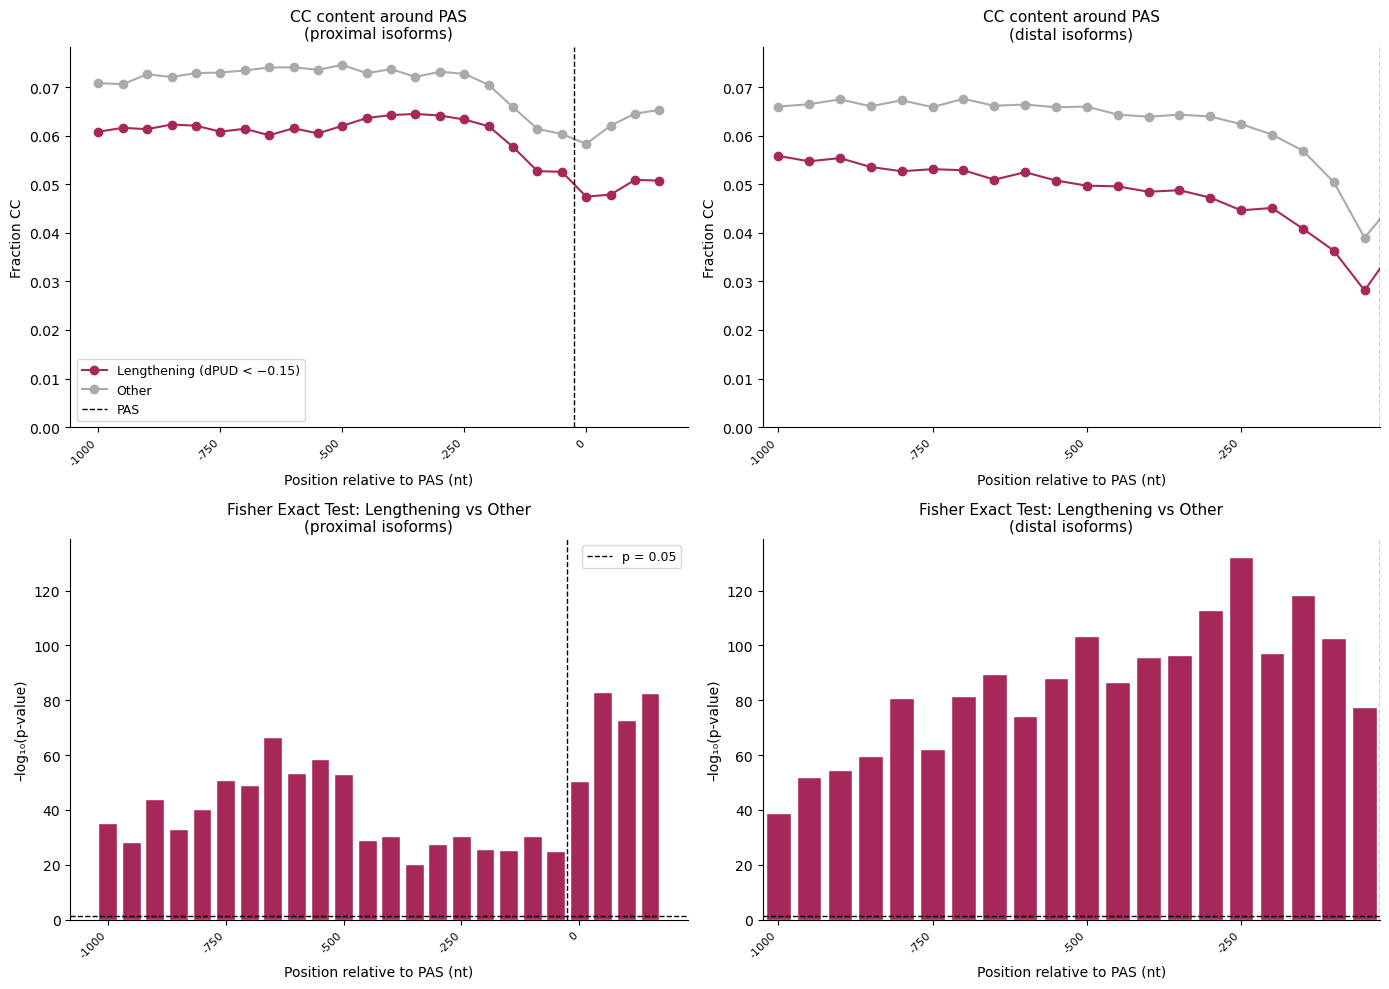

Computing GG-content profile for proximal isoforms...


Computing GG-content profile for distal isoforms...


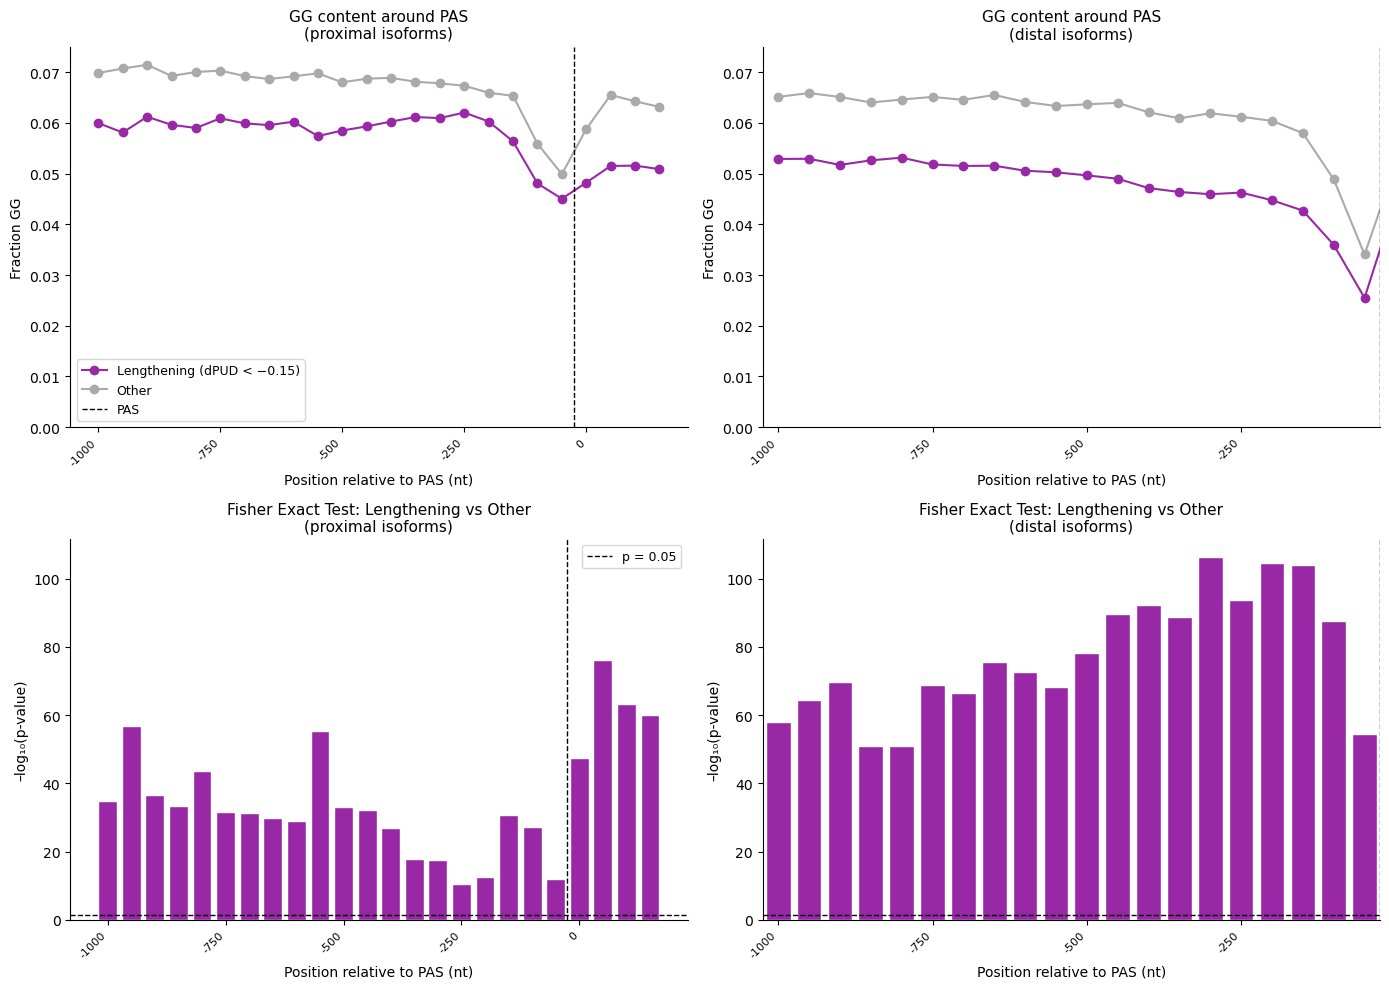

In [21]:
dimer_colors = {'AT': '#e41a1c', 'GC': '#377eb8', 'GT': '#4daf4a', 'GA': '#984ea3', 'AC': '#ff7f00', 'CT': '#a65628', 'AA': "#28a639",'TT': "#3c6fde", 'GG': "#9928a6", 'CC': "#a6285a"}

for dimer in DIMERS:
    fig, axes, pvalues_dimer = plot_dimer_window_profiles(dimer, WINDOW_SIZE=50, color=dimer_colors[dimer], y_min=0)
    save_figure(f"{figures_subfolder}/{DIMER_LABEL[dimer]}_content_around_PAS_longer_in_nucleus_D35_CTRL.pdf",
                pattern="<nucleotides>_content_around_PAS_longer_in_nucleus_D35_CTRL.pdf",
                legend="One file per nucleotide (A, C, G, U) and dinucleotide (AU, GC, GU, GA, AC, CU, AA, UU, CC, GG). Top: fraction of bases (or of overlapping dinucleotide positions) equal to it in each 50-nt window from -1000 to +200 nt around the PAS (hg38 sequence on the transcript strand, pooled over all transcripts), for 3'UTR pairs longer in the nucleus than in the cytoplasm at D35 in CTRL (proximal shift in the cytoplasm; pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Cytoplasmic_Wildtype) (coloured) vs all other pairs (grey; longest distal isoform per proximal), proximal (left) and distal (right, shown up to the PAS) isoform. Bottom: -log10(p) of a two-sided Fisher's exact test per window (coloured = p < 0.05, uncorrected; dashed line = p 0.05). The plot legend labels the group 'Lengthening' in every comparison.")
    plt.show()


## Dinucleotide enrichment per region (R1 / R2 / R3), the three lengthening groups

For each of the 10 dinucleotides profiled above (`DIMERS`) and each 50 nt window, the same Fisher exact test as in the profiles above (overlapping dinucleotide positions equal vs not equal to the dimer, Lengthening vs Other) gives a p-value and a fold enrichment FE = fraction(Lengthening) / fraction(Other). The value plotted is the signed -log10(p), sign(log2 FE) × -log10(p), averaged over the windows of each region:

- **R1**: proximal PAS [-350:0]
- **R2**: proximal PAS [0:+200]
- **R3**: distal PAS [-350:0]


Longer over time (nucleus): n Lengthening = 2481, n Other = 5396


Longer over time (cytoplasm): n Lengthening = 271, n Other = 7606


Longer in nucleus than cytoplasm (D35): n Lengthening = 3899, n Other = 3978


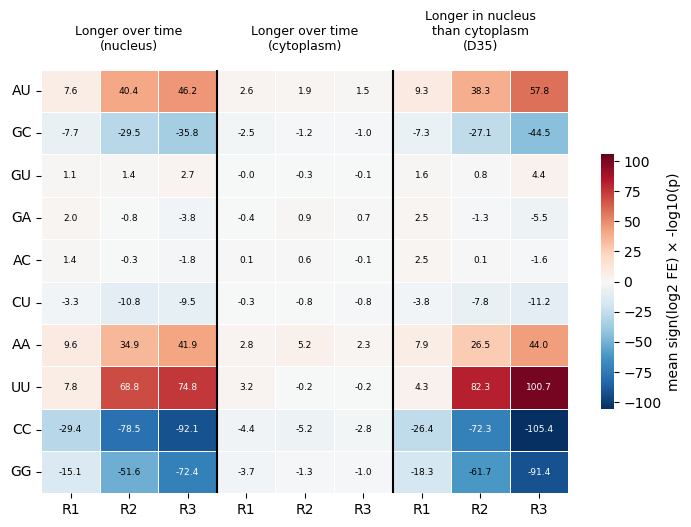

In [22]:
import textwrap

REGION_WINDOWS = {  # region -> (isoform, [left, right) relative to its PAS)
    'R1': ('proximal', (-350, 0)),
    'R2': ('proximal', (0, 200)),
    'R3': ('distal', (-350, 0)),
}
LENGTHENING_GROUPS = {
    'Longer over time (nucleus)': 'pairs_distals_D22_Nuclear_Wildtype_vs_D35_Nuclear_Wildtype.csv',
    'Longer over time (cytoplasm)': 'pairs_distals_D22_Cytoplasmic_Wildtype_vs_D35_Cytoplasmic_Wildtype.csv',
    # pairs_<proximals|distals>_<A>_vs_<B>: shift to proximal/distal usage in B (docs/data_provenance.md)
    'Longer in nucleus than cytoplasm (D35)': 'pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Cytoplasmic_Wildtype.csv',
}
_BASE_CODE = np.full(256, -1, dtype=np.int8)
for k, b in enumerate('ACGT'):
    _BASE_CODE[ord(b)] = k


def dimer_window_counts(seqs, window_lefts, WINDOW_SIZE=50, wl_full=WL_FULL):
    """(n_windows x 16) counts of overlapping dinucleotides per window, pooled across sequences,
    plus the number of dinucleotide positions per window (same counting as compute_dimer_window_profile)."""
    codes = _BASE_CODE[np.frombuffer(''.join(seqs).encode('ascii'), dtype=np.uint8)].reshape(len(seqs), -1).astype(np.int16)
    dimer_codes = np.where((codes[:, :-1] >= 0) & (codes[:, 1:] >= 0), 4 * codes[:, :-1] + codes[:, 1:], -1)
    counts = np.zeros((len(window_lefts), 16), dtype=np.int64)
    for j, wl in enumerate(window_lefts):
        offset = wl - wl_full
        block = dimer_codes[:, offset:offset + WINDOW_SIZE - 1].ravel()
        counts[j] = np.bincount(block[block >= 0], minlength=16)
    return counts, len(seqs) * (WINDOW_SIZE - 1)


def region_signed_log10p(seqs_len, seqs_other, window_lefts, WINDOW_SIZE=50):
    """Per window and dinucleotide: sign(log2 FE) * -log10(Fisher p), Lengthening vs Other."""
    c_len, n_len = dimer_window_counts(seqs_len, window_lefts, WINDOW_SIZE)
    c_oth, n_oth = dimer_window_counts(seqs_other, window_lefts, WINDOW_SIZE)
    out = np.zeros_like(c_len, dtype=float)
    for j in range(len(window_lefts)):
        for d in range(16):
            a, c = int(c_len[j, d]), int(c_oth[j, d])
            _, p = fisher_exact([[a, n_len - a], [c, n_oth - c]], alternative='two-sided')
            fe = (a / n_len) / (c / n_oth) if c else np.inf
            out[j, d] = (1 if fe > 1 else -1) * -np.log10(p)
    return out


rows = []
for group, shift_file in LENGTHENING_GROUPS.items():
    lengthening = pd.read_csv(f"{path_to_shift}/{shift_file}")
    lengthening = lengthening[lengthening['distal_id'].isin(table_of_pairs_longest['distal_id'])]
    other = table_of_pairs_longest[~table_of_pairs_longest['distal_id'].isin(lengthening['distal_id'])][["proximal_id", "distal_id"]]
    for region, (iso_type, (r_left, r_right)) in REGION_WINDOWS.items():
        window_lefts = list(range(r_left, r_right, 50))
        seqs_len = get_window_sequences(lengthening, f"{iso_type}_id", pas_lookup, hg38_fasta, WL_FULL, WR_FULL)
        seqs_other = get_window_sequences(other, f"{iso_type}_id", pas_lookup, hg38_fasta, WL_FULL, WR_FULL)
        signed = region_signed_log10p(seqs_len, seqs_other, window_lefts)
        for dimer in DIMERS:  # the dinucleotides profiled above
            d = 4 * 'ACGT'.index(dimer[0]) + 'ACGT'.index(dimer[1])
            rows.append({'group': group, 'region': region, 'dinucleotide': DIMER_LABEL[dimer],
                         'n_lengthening': len(seqs_len), 'n_other': len(seqs_other), 'n_windows': len(window_lefts),
                         'mean_signed_log10p': signed[:, d].mean()})
    print(f"{group}: n Lengthening = {len(lengthening)}, n Other = {len(other)}")

dimer_region_scores = pd.DataFrame(rows)
save_table(dimer_region_scores, f"{tables_subfolder}/dinucleotide_enrichment_mean_signed_log10_Fisher_p_lengthened_vs_other_3UTR_pairs_per_region_R1_R2_R3.csv", index=False,
           legend="Table behind dinucleotide_signed_log10p_per_region_heatmap.pdf: for each lengthening group, region (R1 proximal PAS [-350:0], R2 proximal PAS [0:+200], R3 distal PAS [-350:0]) and dinucleotide, the number of Lengthening / Other pairs, the number of 50-nt windows in the region and the mean over those windows of sign(log2 FE) x -log10(two-sided Fisher p), Lengthening vs Other.")

heatmap_df = dimer_region_scores.pivot_table(index='dinucleotide', columns=['group', 'region'], values='mean_signed_log10p')
heatmap_df = heatmap_df.loc[[DIMER_LABEL[d] for d in DIMERS], [(g, r) for g in LENGTHENING_GROUPS for r in REGION_WINDOWS]]
vmax = np.abs(heatmap_df.values).max()

fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.heatmap(heatmap_df, cmap='RdBu_r', center=0, vmin=-vmax, vmax=vmax, linewidths=0.4, linecolor='white', cbar_kws={'label': 'mean sign(log2 FE) × -log10(p)', 'shrink': 0.6}, ax=ax)
for (yi, xi), v in np.ndenumerate(heatmap_df.values):  # written by hand: sns annot only labels the first row here
    ax.text(xi + 0.5, yi + 0.5, f"{v:.1f}", ha='center', va='center', fontsize=6.5,
            color='white' if abs(v) > 0.6 * vmax else 'black')
for k in range(1, len(LENGTHENING_GROUPS)):
    ax.axvline(k * len(REGION_WINDOWS), color='black', linewidth=1.5)
ax.set_xticklabels([r for _ in LENGTHENING_GROUPS for r in REGION_WINDOWS], rotation=0)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
for k, group in enumerate(LENGTHENING_GROUPS):
    ax.text((k + 0.5) * len(REGION_WINDOWS), -0.4, textwrap.fill(group, 18), ha='center', va='bottom', fontsize=9)
save_figure(f"{figures_subfolder}/dinucleotide_signed_log10p_per_region_heatmap.pdf",
            legend="Dinucleotide content of lengthened vs other 3'UTR pairs per region. Rows: the 10 dinucleotides profiled above (AU, GC, GU, GA, AC, CU, AA, UU, CC, GG). Columns: R1 (proximal PAS [-350:0]), R2 (proximal PAS [0:+200]) and R3 (distal PAS [-350:0]) for three groups of lengthened pairs in CTRL: longer from D22 to D35 in the nucleus (pairs_distals_D22_Nuclear_Wildtype_vs_D35_Nuclear_Wildtype), longer from D22 to D35 in the cytoplasm (pairs_distals_D22_Cytoplasmic_Wildtype_vs_D35_Cytoplasmic_Wildtype) and longer in the nucleus than in the cytoplasm at D35 (pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Cytoplasmic_Wildtype); each compared with all other pairs (longest distal isoform per proximal). In each 50-nt window, a two-sided Fisher's exact test compares overlapping dinucleotide positions equal vs not equal to the dinucleotide (hg38 sequence on the transcript strand, pooled over transcripts) between the two groups; the value is sign(log2 fold enrichment) x -log10(p), averaged over the region's windows (7 for R1 and R3, 4 for R2). Red = enriched, blue = depleted in lengthened pairs; p uncorrected.")
plt.show()

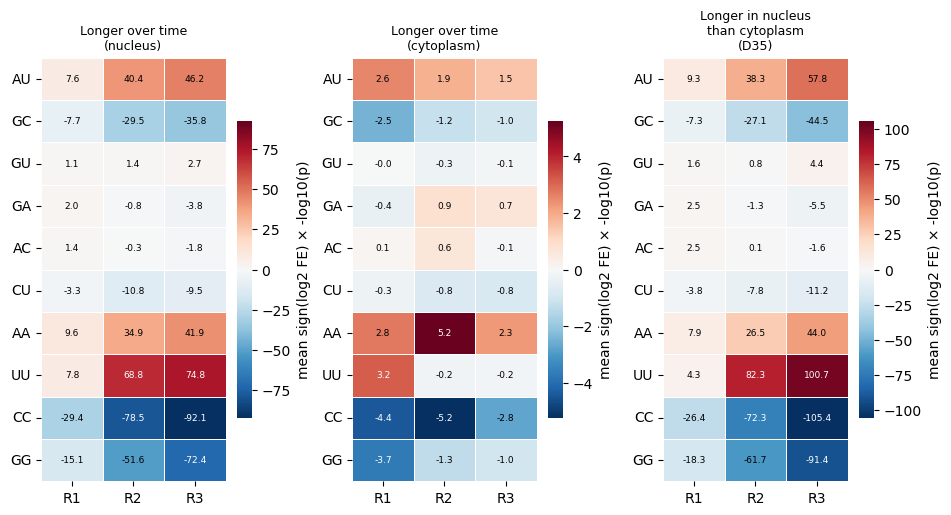

In [23]:
# Same values, one colour scale per group (the -log10(p) range depends on group size)
fig, axes = plt.subplots(1, len(LENGTHENING_GROUPS), figsize=(11, 5.5), gridspec_kw={'wspace': 0.35})
for ax, group in zip(axes, LENGTHENING_GROUPS):
    sub_df = heatmap_df[group][list(REGION_WINDOWS)]
    vmax_g = np.abs(sub_df.values).max()
    sns.heatmap(sub_df, cmap='RdBu_r', center=0, vmin=-vmax_g, vmax=vmax_g, linewidths=0.4, linecolor='white',
                cbar_kws={'label': 'mean sign(log2 FE) × -log10(p)', 'shrink': 0.7}, ax=ax)
    for (yi, xi), v in np.ndenumerate(sub_df.values):  # written by hand: sns annot only labels the first row here
        ax.text(xi + 0.5, yi + 0.5, f"{v:.1f}", ha='center', va='center', fontsize=6.5,
                color='white' if abs(v) > 0.6 * vmax_g else 'black')
    ax.set_title(textwrap.fill(group, 18), fontsize=9)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_xticklabels(list(REGION_WINDOWS), rotation=0)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
save_figure(f"{figures_subfolder}/dinucleotide_signed_log10p_per_region_heatmap_per_group_scale.pdf",
            legend="Same values as dinucleotide_signed_log10p_per_region_heatmap.pdf, with one colour scale per group (symmetric around 0, set by the group's largest absolute value), since -log10(p) scales with group size (2,481 pairs longer over time in the nucleus, 271 in the cytoplasm, 3,899 longer in the nucleus than in the cytoplasm at D35). Rows: the 10 dinucleotides (AU, GC, GU, GA, AC, CU, AA, UU, CC, GG). Columns: R1 (proximal PAS [-350:0]), R2 (proximal PAS [0:+200]), R3 (distal PAS [-350:0]). Value: sign(log2 fold enrichment) x -log10(two-sided Fisher p) per 50-nt window, lengthened vs all other pairs, averaged over the region's windows. Red = enriched, blue = depleted in lengthened pairs; p uncorrected.")
plt.show()